In [1]:
import sys
print(sys.executable)

/Users/stuart/repos/ml-predictive-maintenance-mlops/.venv/bin/python3


# EDA for Predictive Maintenance + MLOps Project

## Dataset: NASA C-MAPPS FD001

### Section 0: Notebook Purpose and Questions

- This notebook explores the NASA C-MAPPS FD001 dataset.
- The goal of this notebook is to understand the structure of the dataset, construct a target for predictive maintenance, understand sensor behavior, and discern the modeling implications.
- This is a critical part of Phase 2 of the project. 

### Section 1: Imports, Paths, and Dataset Files

In [2]:
# STEP 1: import the libraries that will be needed for inspection and plotting

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# STEP 2: define the project-relative paths

project_root_dir = Path("/Users/stuart/repos/ml-predictive-maintenance-mlops/")
raw_data_dir = project_root_dir / "data/raw/CMAPSSData"
interim_data_dir = project_root_dir / "data/interim"
processed_data_dir = project_root_dir / "data/processed"

In [4]:
# STEP 3: define the three core FD001 file paths explicitly

train_FD001 = "train_FD001.txt" 
test_FD001 = "test_FD001.txt"
rul_FD001 = "RUL_FD001.txt"

train_path = raw_data_dir / train_FD001
test_path = raw_data_dir / test_FD001
rul_path = raw_data_dir / rul_FD001

#### File explanations...

- train_FD001 contains run-to-failure engine histories for the training set. Each row corresponds to one engine cycle.
- test_FD001 contains the engine histories for the test set. These sequences stop before failure.
- rul_FD001 contains the true remaining useful life values for the test engines after the final observed cycle in the test file.

In [5]:
# STEP 4: display or verify the paths

print(project_root_dir); print(project_root_dir.exists())
print(raw_data_dir); print(raw_data_dir.exists())
print(interim_data_dir); print(interim_data_dir.exists())
print(processed_data_dir); print(processed_data_dir.exists())

print(train_FD001)
print(test_FD001)
print(rul_FD001)

print(train_path); print(train_path.is_file())
print(test_path); print(test_path.is_file())
print(rul_path); print(rul_path.is_file())

/Users/stuart/repos/ml-predictive-maintenance-mlops
True
/Users/stuart/repos/ml-predictive-maintenance-mlops/data/raw/CMAPSSData
True
/Users/stuart/repos/ml-predictive-maintenance-mlops/data/interim
True
/Users/stuart/repos/ml-predictive-maintenance-mlops/data/processed
True
train_FD001.txt
test_FD001.txt
RUL_FD001.txt
/Users/stuart/repos/ml-predictive-maintenance-mlops/data/raw/CMAPSSData/train_FD001.txt
True
/Users/stuart/repos/ml-predictive-maintenance-mlops/data/raw/CMAPSSData/test_FD001.txt
True
/Users/stuart/repos/ml-predictive-maintenance-mlops/data/raw/CMAPSSData/RUL_FD001.txt
True


#### Closing statements for this section...

In this section I...
- Imported a few libraries rather than all possible libraries.
- Saved file paths to variables by setting them up as Path objects rather than raw strings.
- Applied the ".exists()" and ".is_file()" methods to the Path objects that I created for verification. 

### Section 2: Raw Loading and First Look

In [6]:
# STEP 1: load the three FD001 files into pandas dataframes

# it looks like the data could be described as space separated values
train_df = pd.read_csv(train_path, sep=r"\s+", header=None)
test_df = pd.read_csv(test_path, sep=r"\s+", header=None)
rul_df = pd.read_csv(rul_path, sep=r"\s+", header=None)

In [7]:
# STEP 2: inspect the shapes of the three dataframes

print(f"train shape: {train_df.shape}")
print(f" test shape: {test_df.shape}")
print(f"  rul shape: {rul_df.shape}")

train shape: (20631, 26)
 test shape: (13096, 26)
  rul shape: (100, 1)


In [8]:
# STEP 3: inspect the first few rows of each dataframe

train_df.head(3)

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442


In [9]:
test_df.head(3)

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166


In [10]:
print(rul_df.head(6))
print(rul_df.tail(6))

     0
0  112
1   98
2   69
3   82
4   91
5   93
      0
94  128
95  137
96   82
97   59
98  117
99   20


In [11]:
# STEP 4: inspect the last few rows of each dataframe

train_df.tail(3)

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,520.01,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,519.67,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640
20630,100,200,-0.0032,-0.0005,100.0,518.67,643.85,1600.38,1432.14,14.62,...,519.30,2388.26,8137.33,8.5036,0.03,396,2388,100.0,38.37,23.0522


In [12]:
test_df.tail(3)

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
13093,100,196,-0.0006,-0.0003,100.0,518.67,643.44,1593.15,1406.82,14.62,...,521.18,2388.04,8217.24,8.4569,0.03,395,2388,100.0,38.62,23.2051
13094,100,197,-0.0038,0.0001,100.0,518.67,643.26,1594.99,1419.36,14.62,...,521.33,2388.08,8220.48,8.4711,0.03,395,2388,100.0,38.66,23.2699
13095,100,198,0.0013,0.0003,100.0,518.67,642.95,1601.62,1424.99,14.62,...,521.07,2388.05,8214.64,8.4903,0.03,396,2388,100.0,38.70,23.1855


In [13]:
rul_df.tail(3)

,0
97,59
98,117
99,20


#### Description of what's been seen so far...

I'm not seeing anything wrong with the way the dataset is set up. But we'll definitely need to get these columns named. 

#### Closing statements for this section...

In this section I...
- Loaded the data files into pandas dataframes via their path objects.
- Used the fact that the data files are (variable) space separated rather than comma separated.
- Looked at the heads and tails of all three data files, revealing that the RUL file is structurally different than the other two.
- Learned that variable white space is best handled with a regex.
- Learned that "header=None" can be used to tell pandas there is no header row. 

### Section 3: Assign Column Meanings

In [14]:
# STEP 1: figure out the expected column structure

"""
The data are provided as a zip-compressed text file with 26 columns of numbers, separated by spaces. Each row is a snapshot of data taken during a single operational cycle, each column is a different variable. The columns correspond to:
1)	unit number
2)	time, in cycles
3)	operational setting 1
4)	operational setting 2
5)	operational setting 3
6)	sensor measurement  1
7)	sensor measurement  2
...
26)	sensor measurement  26
"""

'\nThe data are provided as a zip-compressed text file with 26 columns of numbers, separated by spaces. Each row is a snapshot of data taken during a single operational cycle, each column is a different variable. The columns correspond to:\n1)\tunit number\n2)\ttime, in cycles\n3)\toperational setting 1\n4)\toperational setting 2\n5)\toperational setting 3\n6)\tsensor measurement  1\n7)\tsensor measurement  2\n...\n26)\tsensor measurement  26\n'

In [15]:
# STEP 2: determine how many columns belong to each group

"""
1 column for unit number
1 column for time (in cycles)
3 columns for operational settings
21 columns for sensor measurements
"""

'\n1 column for unit number\n1 column for time (in cycles)\n3 columns for operational settings\n21 columns for sensor measurements\n'

In [16]:
# STEP 3: create a clean list of column names

train_test_column_names = ["unit_no", "cycles"]

for i in range(3): 
    name = f"op_setting_{i + 1}"
    train_test_column_names.append(name)

for i in range(26 - 5): 
    name = f"sensor_measurement_{i + 1}"
    train_test_column_names.append(name)

rul_column_name = ["rul"]

print(len(train_test_column_names))

26


In [17]:
# STEP 4: assign the column names to train and test

train_df.columns = train_test_column_names
test_df.columns = train_test_column_names

In [18]:
# STEP 5: assign a meaningful name to the RUL dataframe column

rul_df.columns = rul_column_name

In [19]:
# STEP 6: re-inspect the first few rows after naming

train_df.head(3)

,unit_no,cycles,op_setting_1,op_setting_2,op_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_12,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442


In [20]:
test_df.head(3)

,unit_no,cycles,op_setting_1,op_setting_2,op_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_12,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166


In [21]:
rul_df.head(3)

,rul
0,112
1,98
2,69


In [22]:
# STEP 7: confirm that the train and test still align perfectly

print(list(train_df.columns) == list(test_df.columns))

True


#### A description of what we've done in this section...

Because of this section...
- Columns have now been named.
- We know what column groups there are.

#### Closing statements...
- I'm making decent progress on this project!

### Section 4: What One Row Means and What One Full Sequence Means

In [23]:
# STEP 1: pick one engine from the training set 

engine_13 = train_df.loc[train_df["unit_no"] == 13]

In [24]:
# STEP 2: display the first few rows for that one engine
engine_13.head(6)

,unit_no,cycles,op_setting_1,op_setting_2,op_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_12,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21
2546,13,1,-0.0010,-0.0002,100.0,518.67,641.94,1594.32,1405.50,14.62,...,520.87,2388.11,8131.99,8.4393,0.03,392,2388,100.0,38.76,23.3793
2547,13,2,0.0039,-0.0000,100.0,518.67,642.61,1592.31,1406.78,14.62,...,521.45,2388.08,8135.24,8.4325,0.03,393,2388,100.0,38.97,23.2731
2548,13,3,-0.0034,-0.0001,100.0,518.67,642.23,1589.66,1410.36,14.62,...,521.66,2388.10,8137.34,8.4642,0.03,393,2388,100.0,38.67,23.2775
2549,13,4,-0.0013,0.0002,100.0,518.67,642.67,1593.12,1408.66,14.62,...,521.44,2388.16,8133.29,8.4115,0.03,391,2388,100.0,38.80,23.3566
2550,13,5,-0.0018,0.0004,100.0,518.67,642.77,1589.93,1408.31,14.62,...,521.32,2388.14,8133.30,8.3731,0.03,393,2388,100.0,39.08,23.4748
2551,13,6,0.0010,-0.0002,100.0,518.67,642.83,1589.25,1406.72,14.62,...,521.70,2388.10,8134.54,8.4222,0.03,392,2388,100.0,38.88,23.2899


In [25]:
# STEP 3: display the last few rows for that same engine

engine_13.tail(6)

,unit_no,cycles,op_setting_1,op_setting_2,op_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_12,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21
2703,13,158,-0.0024,0.0001,100.0,518.67,643.17,1610.57,1427.79,14.62,...,520.74,2388.17,8208.97,8.5075,0.03,396,2388,100.0,38.58,23.1415
2704,13,159,-0.0008,-0.0004,100.0,518.67,643.53,1612.88,1418.86,14.62,...,520.50,2388.20,8212.93,8.5540,0.03,396,2388,100.0,38.28,23.1357
2705,13,160,0.0011,0.0000,100.0,518.67,643.77,1597.42,1429.73,14.62,...,519.80,2388.13,8210.94,8.5109,0.03,397,2388,100.0,38.49,23.2090
2706,13,161,-0.0030,-0.0001,100.0,518.67,643.50,1602.21,1432.17,14.62,...,520.26,2388.19,8210.25,8.5269,0.03,396,2388,100.0,38.43,23.0185
2707,13,162,-0.0011,0.0003,100.0,518.67,643.87,1605.83,1431.55,14.62,...,520.08,2388.15,8218.44,8.5015,0.03,397,2388,100.0,38.35,23.1104
2708,13,163,-0.0002,-0.0004,100.0,518.67,644.26,1610.89,1430.32,14.62,...,519.76,2388.16,8211.76,8.5477,0.03,397,2388,100.0,38.53,23.1291


In [26]:
# STEP 4: check how many rows belong to that engine

engine_13.shape

(163, 26)

In [27]:
# STEP 5: verify that cycles increase in order within the engine

cycle_nums = engine_13['cycles'].to_list()
print(pd.Series(cycle_nums).is_monotonic_increasing)

True


In [28]:
# STEP 6: compare two different engines briefly

engine_11 = train_df.loc[train_df["unit_no"] == 11]

print("ENGINE SHAPES")
print(engine_11.shape, engine_13.shape, "\n")

print("CYCLE MONOTONIC INCREASING BEHAVIOR")
engine_11_cycles = engine_11['cycles'].to_list()
engine_13_cycles = engine_13['cycles'].to_list()
engine_11_series = pd.Series(engine_11_cycles)
engine_13_series = pd.Series(engine_13_cycles)
print(engine_11_series.is_monotonic_increasing)
print(engine_13_series.is_monotonic_increasing, "\n")

print("CHECK FOR DUPLICATES")
print(engine_11['cycles'].duplicated().sum())
print(engine_13['cycles'].duplicated().sum(), "\n")

print("CYCLE MINS")
print(min(engine_11_series), min(engine_13_cycles), "\n")

print("CYCLE MAXES")
print(max(engine_11_cycles), max(engine_13_cycles), "\n")

print("CHECK FOR OUT OF PLACE UNIT NUMBERS")
print(all(engine_11['unit_no'].to_list()[i] == 11 for i in range(engine_11.shape[0])))
print(all(engine_13['unit_no'].to_list()[i] == 13 for i in range(engine_13.shape[0])))

ENGINE SHAPES
(240, 26) (163, 26) 

CYCLE MONOTONIC INCREASING BEHAVIOR
True
True 

CHECK FOR DUPLICATES
0
0 

CYCLE MINS
1 1 

CYCLE MAXES
240 163 

CHECK FOR OUT OF PLACE UNIT NUMBERS
True
True


#### STEP 7: write down the plain-English interpretation

Engine 13 contains 163 observations covering cycles 1-163. Engine 11 contains 240 observations covering cycles 1-240. Both engines begin their own sequence independently, but their sequence lengths are different. This confirms that the dataframe contains multiple separate engine lifecycles rather than one continuous global timeline. 

One row represents one engine at one operating cycle. It contains the engine's identifier, its position in the observed lifecycle, three operating settings, and 21 sensor measurements recorded during that cycle.

A full sequence consists of all rows belonging to one engine, ordered by cycle number. For example, Engine 13 contributes 163 rows representing cycles 1 through 163. Another engine begins its own cycle count at 1 and may have a different sequence length. 

Therefore, the FD001 training table is not one continuous timeline. It is a collection of separate engine lifecycles stored together in one dataframe. 

#### STEP 8: add a modeling implication note

Rows belonging to the same engine are related because they describe neighboring stages of the same physical lifecycle. They should not be treated as completely independent observations. 

A random row-level train/validation split could place early cycles from an engine in one subset and later cycles from that same engine in another. This could produce an overly optimistic evaluation because the model would be evaluated on an engine whose behavior it had already encountered in training. 

A safer validation strategy is to keep complete engine sequences together so that validation performance measures generalization to unseen engines. Time order must also be preserved when constructing features: rolling statistics, trends, or windows for a given cycle must use only information available at or before that cycle, never future sensor readings. 

Finally, a single-cycle snapshot may not fully describe degradation. Later feature engineering should investigate whether recent sensor history, rolling summaries, or trend features predict RUL better than isolated rows.

### Section 5: Sequence Lengths Across Engines

#### TASK 1: define "sequence length" clearly

A sequence length is the number of observed cycles belonging to a single engine. In the training set, this is the run-to-failure history. In the testing set, it is only the observed history before truncation. 

In [29]:
# TASK 2: calculate the training sequence length for every engine

cycle_counts = train_df.groupby("unit_no")['cycles'].count()
print(cycle_counts.head(6))

unit_no
1    192
2    287
3    179
4    189
5    269
6    188
Name: cycles, dtype: int64


In [30]:
# TASK 3: validate the sequence length calculation

cycle_count_summary = (
    train_df
    .groupby("unit_no")["cycles"]
    .agg(["min", "max", "count", "nunique"])
    
)

print(cycle_count_summary.shape)

print(cycle_count_summary)

all_min_equal_1 = (cycle_count_summary["min"] == 1).all()
print("\n", "ALL MIN EQUAL 1")
print(all_min_equal_1)

columns = ["max", "count", "nunique"]
cycle_count_summary["all_3_equal"] = (
    cycle_count_summary[columns]
    .eq(cycle_count_summary[columns[0]], axis=0)
    .all(axis=1)
)

print("\n", "ALL MAX/COUNT/NUNIQUE EQUAL")
print((cycle_count_summary["all_3_equal"] == True).all())

(100, 4)
         min  max  count  nunique
unit_no                          
1          1  192    192      192
2          1  287    287      287
3          1  179    179      179
4          1  189    189      189
5          1  269    269      269
...      ...  ...    ...      ...
96         1  336    336      336
97         1  202    202      202
98         1  156    156      156
99         1  185    185      185
100        1  200    200      200

[100 rows x 4 columns]

 ALL MIN EQUAL 1
True

 ALL MAX/COUNT/NUNIQUE EQUAL
True


In [31]:
# TASK 4: produce descriptive statistics for training sequence lengths

cycle_count_stats = (
    train_df
    .groupby("unit_no")["cycles"]
    .agg(["count"])
    
)

print(cycle_count_stats.describe())

            count
count  100.000000
mean   206.310000
std     46.342749
min    128.000000
25%    177.000000
50%    199.000000
75%    229.250000
max    362.000000


We can see from the statistics that...
* A typical training lifecycle is around 200 cycles.
* Lifecycle length vary substantially, spanning 128 to 362 cycles.
* The mean is slightly higher than the median, indicating some longer-lived engines are pulling the average upward.
* The middle 50% of training cycles is between 177 and 229.5 cycles. 

In [32]:
# TASK 5: identify the shortest and longest training sequences

sorted_cycle_counts = cycle_count_stats.sort_values("count")

print(sorted_cycle_counts.head(6))
print(sorted_cycle_counts.tail(6))

         count
unit_no       
39         128
91         135
70         137
57         137
58         147
24         147
         count
unit_no       
2          287
83         293
67         313
96         336
92         341
69         362


When looking at dataset sorted by lifecycle count, we can see that...
* The engines do not all fail after approximately the same number of cycles. Their simulated run-to-failure lifetimes vary considerably. 

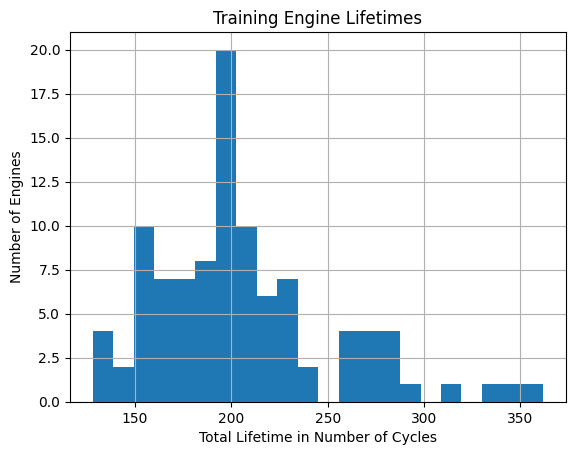

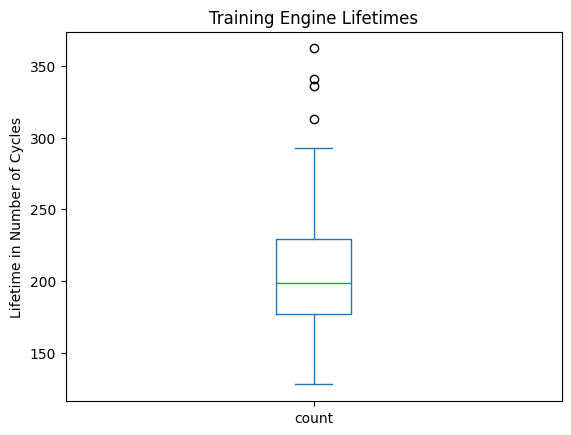

In [33]:
# TASK 6: visualize the training sequence-length distribution

sorted_cycle_counts["count"].hist(bins=22)
plt.title("Training Engine Lifetimes")
plt.xlabel("Total Lifetime in Number of Cycles")
plt.ylabel("Number of Engines")
plt.show()

sorted_cycle_counts.plot.box()
plt.title("Training Engine Lifetimes")
plt.ylabel("Lifetime in Number of Cycles")
plt.show()

         count
unit_no       
1           31
85          34
39          37
22          39
14          46
25          48
         count
unit_no       
81         213
12         217
62         232
91         234
93         244
49         303
            count
count  100.000000
mean   130.960000
std     53.593479
min     31.000000
25%     88.750000
50%    133.500000
75%    164.250000
max    303.000000


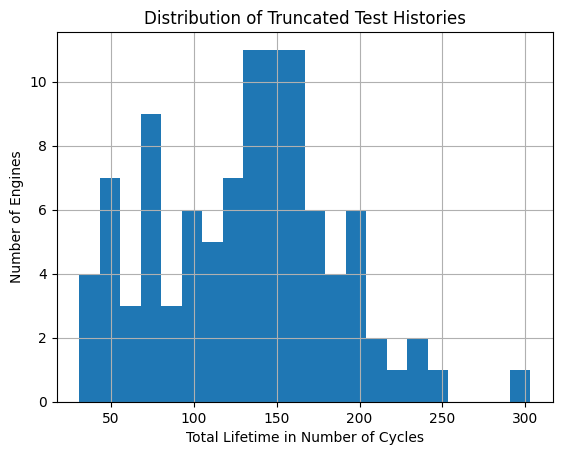

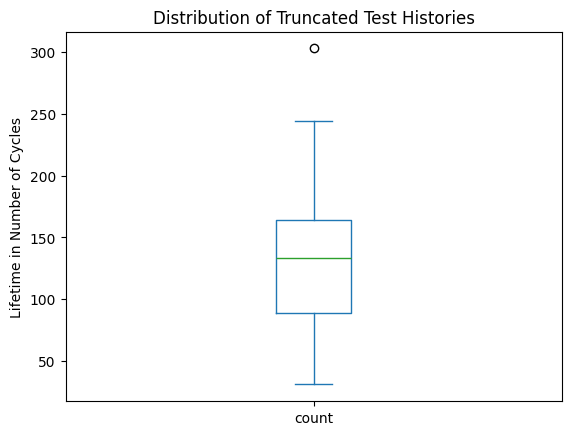

In [34]:
# TASK 7: calculate observed sequence lengths for the test engines

test_cycle_stats = (
    test_df.groupby("unit_no")["cycles"]
    .agg(["count"])
).sort_values("count")

train_cycle_stats = sorted_cycle_counts

print(test_cycle_stats.head(6))
print(test_cycle_stats.tail(6))

print(test_cycle_stats.describe())

test_cycle_stats["count"].hist(bins=22)
plt.title("Distribution of Truncated Test Histories")
plt.xlabel("Total Lifetime in Number of Cycles")
plt.ylabel("Number of Engines")
plt.show

test_cycle_stats.plot.box()
plt.title("Distribution of Truncated Test Histories")
plt.ylabel("Lifetime in Number of Cycles")
plt.show()

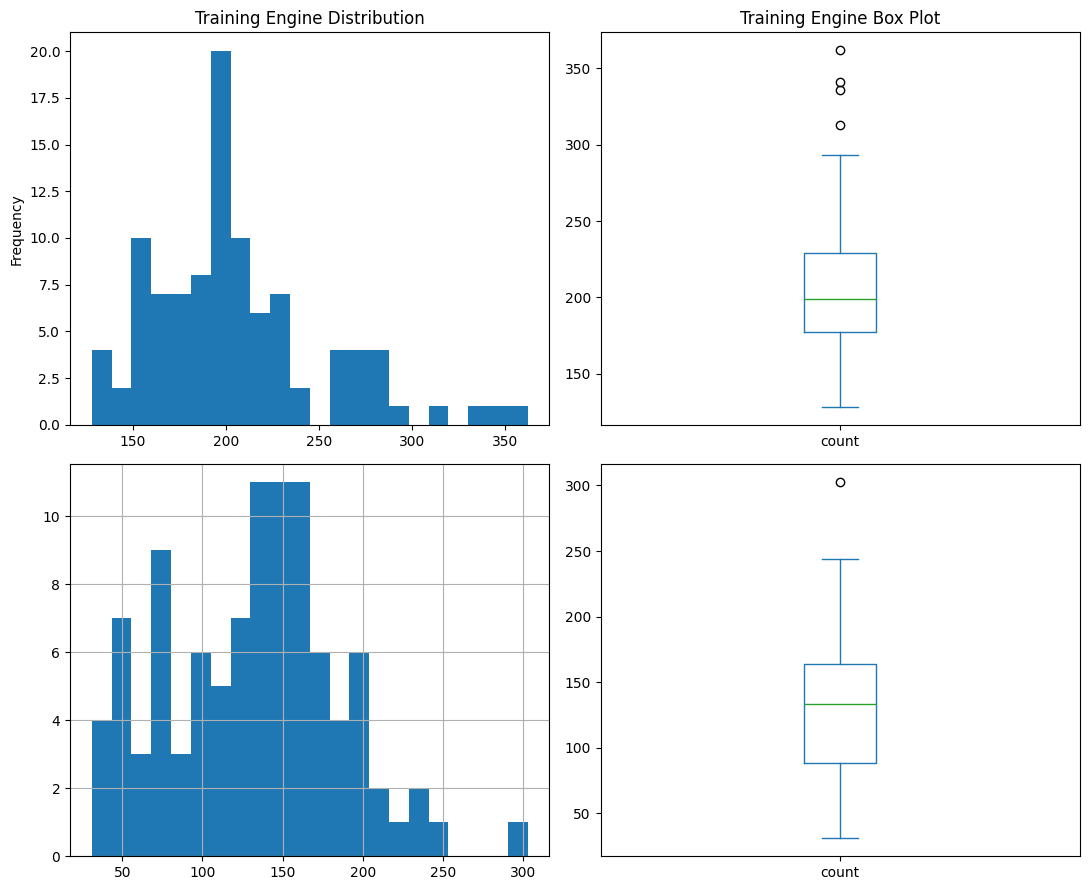

In [35]:
# TASK 8: compare train and test sequence lengths carefully

fig, axes = plt.subplots(
    2,
    2, 
    figsize=(11, 9)
)

sorted_cycle_counts["count"].plot.hist(
    bins=22,
    ax=axes[0, 0],
    title="Training Engine Distribution",
)

sorted_cycle_counts.plot.box(
    ax=axes[0, 1],
    title="Training Engine Box Plot",
)

test_cycle_stats["count"].hist(
    bins=22,
    ax=axes[1, 0]
)

test_cycle_stats.plot.box(
    ax=axes[1, 1]
)

plt.tight_layout()
plt.show()

<Axes: xlabel='unit_no', ylabel='lifecycle_length'>

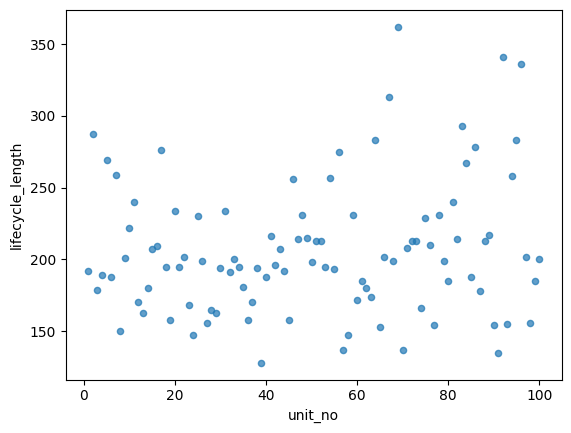

In [36]:
# TASK 9: investigate whether lifecycle length is related to engine identifier

train_engine_lifetimes = (
    train_df
    .groupby("unit_no", as_index=False)
    .agg(lifecycle_length=("cycles", "max"))
)

train_engine_lifetimes.plot.scatter(
    x="unit_no",
    y="lifecycle_length",
    s=20, 
    alpha=0.7,
)

#### TASK 10: write the modeling implications 

Engine histories have unequal lengths, so individual engines contribute different numbers of observations to the dataset. 

So, in analyzing this dataset, there are a few things we should keep in mind. Different engines have different amounts of influence on the dataset, with longer-lived engines have more influence than shorter-lived engines. This also means that if we want to create window-based features, there is the possibility of some engines not having a long enough lifetime to fit the window. At the very least, entire engine histories should remain together when splitting the data. 

#### TASK 11: write the Section 5 summary

In analyzing this dataset, we have dealt with 100 training engines and 100 testing engines. The number of cycles in the training set vary from 128 to 362, with the number of cycles in the testing set varying from 31 to 303. It's worth noting that the data associated with the testing engines does not end at engine failure (i.e., the engines still have some RUL when the dataset cuts off). 

We also found that the engines' unit numbers do not seem to correlate with lifecycle length. 

### Section 6: Construct and Inspect the Training Target

#### Task 6-1: make sure you can give a precise definition of RUL

RUL is the number of operating cycles remaining until the engine reaches the end of its recorded run-to-failure sequence. 
For a training engine $i$ at a cycle $t$: 
$$ RUL_{i, t} = T_{i} - t $$
Here: 
* $T_{i}$ is the final cycle for engine $i$
* $t$ is the current cycle

In [37]:
# Task 6-2: create a final-cycle lookup for every training engine

final_cycles = (
    train_df.groupby("unit_no")["cycles"]
    .max()
    .reset_index(name="final_cycle")
)

print(final_cycles.shape)
print(final_cycles["unit_no"].nunique())
print(final_cycles["unit_no"].is_unique)
print(final_cycles["final_cycle"].notna().all())

(100, 2)
100
True
True


In [38]:
# Task 6-3: Attach each engine's final cycle to every training row

print(f"Shape before adding new column: {train_df.shape}")
train_df["final_cycle"] = (
    train_df.groupby("unit_no")["cycles"]
    .transform("max")
)
print(f"Shape after adding new column: {train_df.shape}", "\n")

print(train_df[["unit_no", "cycles", "final_cycle"]].head(6))
print(train_df["final_cycle"].notna().all())

Shape before adding new column: (20631, 26)
Shape after adding new column: (20631, 27) 

   unit_no  cycles  final_cycle
0        1       1          192
1        1       2          192
2        1       3          192
3        1       4          192
4        1       5          192
5        1       6          192
True


In [39]:
# Task 6-4: Calculate the uncapped training RUL

print(train_df["final_cycle"][0] - train_df["cycles"][0])

print(train_df["final_cycle"][1] - train_df["cycles"][1])

print(train_df["final_cycle"][191] - train_df["cycles"][191])

train_df["rul"] = train_df["final_cycle"] - train_df["cycles"]

train_df.head(6)

191
190
0


,unit_no,cycles,op_setting_1,op_setting_2,op_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21,final_cycle,rul
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,192,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,192,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,192,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,192,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,192,187
5,1,6,-0.0043,-0.0001,100.0,518.67,642.10,1584.47,1398.37,14.62,...,8132.85,8.4108,0.03,391,2388,100.0,38.98,23.3669,192,186


In [40]:
# Task 6-5: manually inspect RUL for selected engines

engine_11 = train_df.loc[train_df["unit_no"] == 11]
engine_13 = train_df.loc[train_df["unit_no"] == 13]

print(engine_11[["unit_no", "cycles", "final_cycle", "rul"]][0:2])
print(engine_11[["unit_no", "cycles", "final_cycle", "rul"]][99:101])
print(engine_11[["unit_no", "cycles", "final_cycle", "rul"]][-2:])

print(engine_13[["unit_no", "cycles", "final_cycle", "rul"]][0:2])
print(engine_13[["unit_no", "cycles", "final_cycle", "rul"]][99:101])
print(engine_13[["unit_no", "cycles", "final_cycle", "rul"]][-2:])

      unit_no  cycles  final_cycle  rul
2136       11       1          240  239
2137       11       2          240  238
      unit_no  cycles  final_cycle  rul
2235       11     100          240  140
2236       11     101          240  139
      unit_no  cycles  final_cycle  rul
2374       11     239          240    1
2375       11     240          240    0
      unit_no  cycles  final_cycle  rul
2546       13       1          163  162
2547       13       2          163  161
      unit_no  cycles  final_cycle  rul
2645       13     100          163   63
2646       13     101          163   62
      unit_no  cycles  final_cycle  rul
2707       13     162          163    1
2708       13     163          163    0


In [41]:
# Task 6-6: Validate the target across all training engines

train_validation = train_df[["unit_no", "cycles", "final_cycle", "rul"]]

## Task 6-6-1: confirm that for every engine the minimum RUL is 0

min_rul_check = (
    train_validation
    .groupby("unit_no")["rul"]
    .min()
    .eq(0)
)

print(min_rul_check)

print("MIN IS ZERO FOR ALL RUL:", min_rul_check.all())

unit_no
1      True
2      True
3      True
4      True
5      True
       ... 
96     True
97     True
98     True
99     True
100    True
Name: rul, Length: 100, dtype: bool
MIN IS ZERO FOR ALL RUL: True


In [42]:
## Task 6-6-2: confirm that for every engine maximum RUL equals final_cycle - 1

max_rul_check = (
    train_validation
    .groupby("unit_no")
    .agg(
        max_rul=("rul", "max"),
        final_cycle=("final_cycle", "first")
    )
)
print(max_rul_check)
max_rul_check["expected_max_rul"] = (
    max_rul_check["final_cycle"] - 1
)
print(max_rul_check)

max_rul_check["max_rul_is_correct"] = (
    max_rul_check["max_rul"]
    .eq(max_rul_check["expected_max_rul"])
)
print(max_rul_check)
max_correct = max_rul_check["max_rul_is_correct"].all()
print("ALL MAX RUL ARE CORRECT: ", max_correct)

         max_rul  final_cycle
unit_no                      
1            191          192
2            286          287
3            178          179
4            188          189
5            268          269
...          ...          ...
96           335          336
97           201          202
98           155          156
99           184          185
100          199          200

[100 rows x 2 columns]
         max_rul  final_cycle  expected_max_rul
unit_no                                        
1            191          192               191
2            286          287               286
3            178          179               178
4            188          189               188
5            268          269               268
...          ...          ...               ...
96           335          336               335
97           201          202               201
98           155          156               155
99           184          185               184
100       

In [43]:
## Task 6-6-3: confirm that for every engine the number of unique RUL values equals sequence length

num_unique = (
    train_validation
    .groupby("unit_no")["rul"]
    .agg(["size", "nunique"])
)

num_unique["matched"] = (
    num_unique["size"]
    .eq(num_unique["nunique"])
)

print(f"NUMBER OF RUL VALUES EQUALS SEQUENCE LENGTH: {num_unique["matched"].all()}")

NUMBER OF RUL VALUES EQUALS SEQUENCE LENGTH: True


In [44]:
## Task 6-4: confirm that RUL is monotonically decreasing for every engine

ordered_validation = train_validation.sort_values(
    ["unit_no", "cycles"]
)

rul_monotonic_check = (
    ordered_validation
    .groupby("unit_no")["rul"]
    .agg(lambda rul: rul.is_monotonic_decreasing)
)

print(
    f"ALL ENGINES HAVE RUL THAT IS MONOTONICALLY DECREASING: {rul_monotonic_check.all()}"
)

ALL ENGINES HAVE RUL THAT IS MONOTONICALLY DECREASING: True


In [45]:
## Task 6-6-5: confirm that consecutive RUL differences are all -1

ordered_validation = (
    train_validation
    .sort_values(["unit_no", "cycles"])
    .copy()
)

ordered_validation["rul_difference"] = (
    ordered_validation
    .groupby("unit_no")["rul"]
    .diff()
)

ordered_validation["diff_is_minus_one"] = (
    ordered_validation["rul_difference"].eq(-1)
)

rul_difference_check = (
    ordered_validation
    .groupby("unit_no")["rul"]
    .agg(lambda rul: rul.diff().dropna().eq(-1).all())
)

print(
    f"ALL DIFFERENCES BETWEEN CONSECUTIVE RUL MEASUREMENTS ARE -1: {rul_difference_check.all()}"
)

ALL DIFFERENCES BETWEEN CONSECUTIVE RUL MEASUREMENTS ARE -1: True


In [46]:
# Task 6-7: Understand the test RUL labels

In [47]:
## Task 6-7-1: confirm the test set contains the same number of unique engines as the RUL file has rows

print(test_df.shape)
print(rul_df.shape)

print(test_df["unit_no"].nunique() == rul_df.shape[0])

(13096, 26)
(100, 1)
True


In [48]:
## Task 6-7-2: confirm the test engine ordering aligns with RUL row ordering

unit_nos = test_df["unit_no"]
unique_unit_nos = unit_nos.drop_duplicates()
print(unique_unit_nos.iloc[0:6])
print(unique_unit_nos.iloc[-6:])
print(unique_unit_nos.shape)

actual_unit_order = unique_unit_nos.tolist()
expected_unit_order = list(range(1, 100 + 1))
engine_order_matches = actual_unit_order == expected_unit_order
print(engine_order_matches)

0      1
31     2
80     3
206    4
312    5
410    6
Name: unit_no, dtype: int64
12360     95
12449     96
12546     97
12680     98
12801     99
12898    100
Name: unit_no, dtype: int64
(100,)
True


In [49]:
## Task 6-7-3: confirm each RUL value is associated with one test engine

unit_nos = test_df["unit_no"].drop_duplicates().reset_index(drop=True)
rul_values = rul_df["rul"].reset_index(drop=True)

engine_rul_table = pd.concat(
    [unit_nos, rul_values],
    axis=1
)

engine_rul_table = engine_rul_table.rename(
    columns={"rul": "endpoint_rul"}
)

print(unit_nos.shape, rul_values.shape, engine_rul_table.shape)

print(engine_rul_table["unit_no"].nunique())
print(engine_rul_table["unit_no"].dropna().shape)
print(engine_rul_table["endpoint_rul"].dropna().shape)
print(engine_rul_table["endpoint_rul"].ge(0).all())
print(engine_rul_table["unit_no"].tolist() == list(range(1, 101)))

(100,) (100,) (100, 2)
100
(100,)
(100,)
True
True


In [50]:
## Task 6-7-4: confirm the provided label represents RUL at the final visible cycle, not at every test row

last_observed_cycle = (
    test_df
    .groupby("unit_no")["cycles"]
    .max()
    .reset_index(drop=True)
)

test_endpoint_summary = pd.concat(
    [unit_nos, last_observed_cycle, rul_values],
    axis=1
)

test_endpoint_summary = test_endpoint_summary.rename(
    columns={"rul": "endpoint_rul", "cycles": "last_observed_cycle"}
)

test_endpoint_summary

,unit_no,last_observed_cycle,endpoint_rul
0,1,31,112
1,2,49,98
2,3,126,69
3,4,106,82
4,5,98,91
...,...,...,...
95,96,97,137
96,97,134,82
97,98,121,59
98,99,97,117


In [51]:
# Task 6-8: Create a test-engine endpoint summary

test_endpoint_summary["implied_failure_cycle"] = (
    test_endpoint_summary["last_observed_cycle"] + test_endpoint_summary["endpoint_rul"]
)

test_endpoint_summary

,unit_no,last_observed_cycle,endpoint_rul,implied_failure_cycle
0,1,31,112,143
1,2,49,98,147
2,3,126,69,195
3,4,106,82,188
4,5,98,91,189
...,...,...,...,...
95,96,97,137,234
96,97,134,82,216
97,98,121,59,180
98,99,97,117,214


In [52]:
# Task 6-9: Decide whether to keep the raw target uncapped initially

### Initial RUL target decision

The initial modeling target will be **uncapped remaining useful life**, calculated as the number of cycles between the current observation and the engine's final failure cycle.

Using uncapped RUL preserves the complete numerical target and provides a straightforward baseline. It requires the model to distinguish between both high and low remaining-life values.

A capped or piecewise-linear RUL target may be evaluated later. Capping would treat all values above a selected threshold as equivalent, reflecting the possibility that precise early-life RUL is difficult to infer and less operationally important. However, it would also discard information and change the meaning of the prediction.

Therefore, capped RUL will be treated as a separate modeling experiment rather than applied during initial target construction.

In [53]:
# Task 6-10: Examine the uncapped training RUL distribution

In [54]:
## Task 6-10-1: perform basic integrity checks

print(
    train_df["rul"].shape, 
    train_df["rul"].isna().sum(),
    train_df["rul"].min(),
    train_df["rul"].max(),
    train_df["rul"].nunique(),
    train_df["rul"].ge(0).all()
)

(20631,) 0 0 361 362 True


In [55]:
## Task 6-10-2: calculate descriptive statistics

train_df["rul"].describe()

count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: rul, dtype: float64

In [56]:
## Task 6-10-3: count how often each exact RUL value occurs

value_counts = train_df["rul"].value_counts().sort_index()

print(value_counts.head(13))
print(value_counts.tail(13))

rul
0     100
1     100
2     100
3     100
4     100
5     100
6     100
7     100
8     100
9     100
10    100
11    100
12    100
Name: count, dtype: int64
rul
349    1
350    1
351    1
352    1
353    1
354    1
355    1
356    1
357    1
358    1
359    1
360    1
361    1
Name: count, dtype: int64


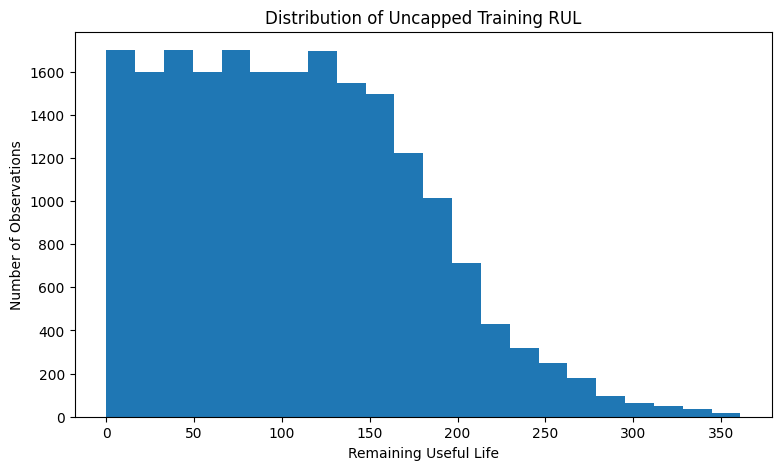

In [57]:
## Task 6-10-4: plot a histogram of uncapped RUL

train_df["rul"].plot.hist(
    bins=22, 
    figsize=(9, 5)
)
plt.title("Distribution of Uncapped Training RUL")
plt.xlabel("Remaining Useful Life")
plt.ylabel("Number of Observations")
plt.show()

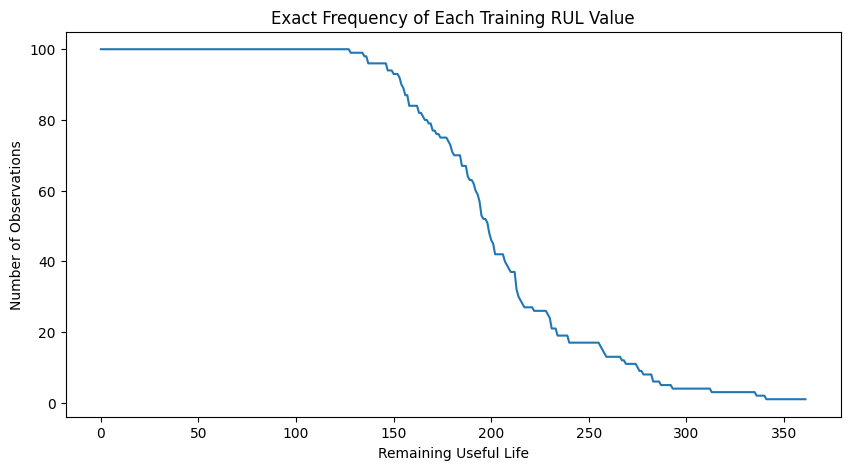

True


In [58]:
## Task 6-10-5: plot exact RUL frequency as a line

value_counts = train_df["rul"].value_counts().sort_index()

value_counts.plot.line(
    figsize=(10, 5)
)

plt.title("Exact Frequency of Each Training RUL Value")
plt.xlabel("Remaining Useful Life")
plt.ylabel("Number of Observations")
plt.show()

print(value_counts.is_monotonic_decreasing)

In [59]:
## Task 6-10-6: inspect low, medium, and high RUL regions

inspection_points = [
    0, 10, 25, 50, 
    100, 150, 200,
    250, 300, 325, 
    350, 361
]

rul_frequency_inspection = (
    value_counts
    .reindex(inspection_points)
    .rename("row_count")
    .to_frame()
)

number_of_engines = train_df["unit_no"].nunique()


rul_frequency_inspection["share_of_engines"] = (
    rul_frequency_inspection["row_count"] / number_of_engines
)

rul_frequency_inspection

,row_count,share_of_engines
rul,,
0,100,1.00
10,100,1.00
25,100,1.00
50,100,1.00
100,100,1.00
150,93,0.93
200,46,0.46
250,17,0.17
300,4,0.04


In [60]:
## Task 6-10-7: connect the distribution to unequal engine lengths

sequence_lengths = (
    train_df
    .groupby("unit_no")
    .size()
)

expected_rul_counts = pd.Series(
    {
    rul: sequence_lengths.ge(rul + 1).sum()
    for rul in value_counts.index
    }, 
    name="expected_count"
)

rul_frequency_check = pd.concat(
    [
        value_counts.rename("observed_count"),
        expected_rul_counts
    ],
    axis=1
)

rul_frequency_check["counts_match"] = (
    rul_frequency_check["observed_count"]
    .eq(rul_frequency_check["expected_count"])
)

print(rul_frequency_check.head())
print(rul_frequency_check.tail())

print(
    "\nAll RUL frequencies are explained by engine lengths:",
    rul_frequency_check["counts_match"].all()
)

   observed_count  expected_count  counts_match
0             100             100          True
1             100             100          True
2             100             100          True
3             100             100          True
4             100             100          True
     observed_count  expected_count  counts_match
357               1               1          True
358               1               1          True
359               1               1          True
360               1               1          True
361               1               1          True

All RUL frequencies are explained by engine lengths: True


In [61]:
## Task 6-10-8: identify initial modeling implications

rul_regions = pd.cut(
    train_df["rul"],
    bins=[-1, 50, 150, float("inf")],
    labels=[
        "Low RUL: 0-50",
        "Medium RUL: 51-150", 
        "High RUL: 151+"
    ]
)

rul_region_summary = (
    rul_regions
    .value_counts(sort=False)
    .rename("row_count")
    .to_frame()
)

rul_region_summary["proportion"] = (
    rul_region_summary["row_count"] / 
    rul_region_summary["row_count"].sum()
)

rul_region_summary

,row_count,proportion
rul,,
Low RUL: 0-50,5100,0.247201
Medium RUL: 51-150,9924,0.481024
High RUL: 151+,5607,0.271775


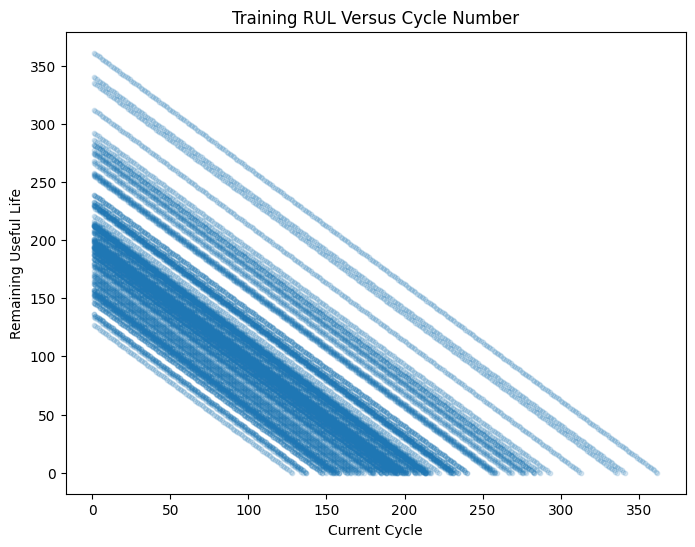

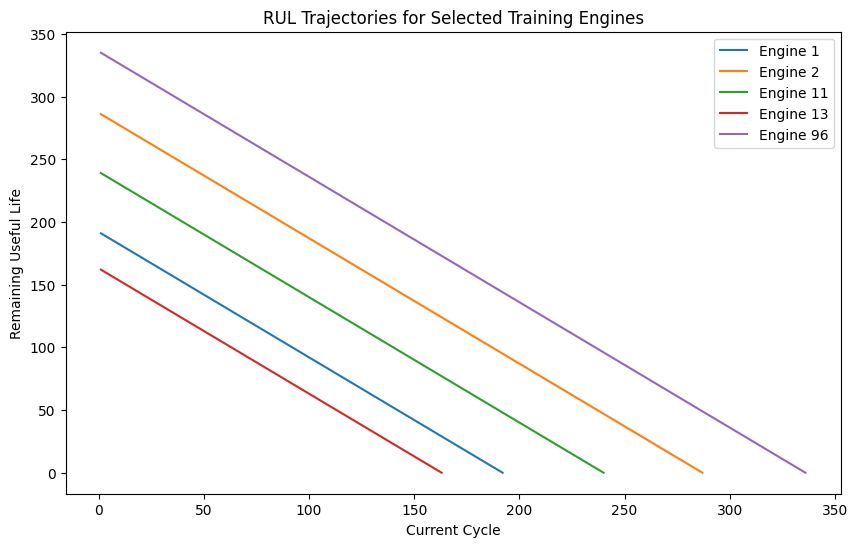

In [62]:
# Task 6-11: inspect RUL against cycle number

# start with a pooled scatterplot 

train_df.plot.scatter(
    x="cycles",
    y="rul",
    figsize=(8, 6),
    alpha=0.15,
    s=10
)

plt.title("Training RUL Versus Cycle Number")
plt.xlabel("Current Cycle")
plt.ylabel("Remaining Useful Life")
plt.show()

# next, plot individual engines

selected_units = [1, 2, 11, 13, 96]

plt.figure(figsize=(10, 6))

for unit_no in selected_units: 
    engine_rows = (
        train_df
        .loc[train_df["unit_no"].eq(unit_no)]
        .sort_values("cycles")
    )

    plt.plot(
        engine_rows["cycles"], 
        engine_rows["rul"],
        label=f"Engine {unit_no}"
    )

plt.title("RUL Trajectories for Selected Training Engines")
plt.xlabel("Current Cycle")
plt.ylabel("Remaining Useful Life")
plt.legend()
plt.show()

#### Task 6-12: Identify target-related leakage risks

Target leakage would occur if the model received information that is unavailable at the moment a prediction is made. The final_cycle column is direct leakage because it was calculated using the complete future lifecycle and is one of the two quantities used to construct RUL. The rul column is the target itself and must not appear among the input features. Any future-derived feature—such as remaining sequence length, distance from the engine’s final row, or a statistic calculated using later cycles—would also leak target information.

The unit_no column should be retained for grouping and validation but not used as a predictive feature because it is an arbitrary identifier. The cycles column is not inherently leakage because the current operating age is known when a prediction is made.

Train-validation splitting must occur by engine rather than randomly by row. A random row split would place observations from the same engine in both training and validation sets, allowing highly related lifecycle observations to appear on both sides of the split. Preprocessing operations must also be fitted using only the training partition.

In [63]:
# Task 6-13: Define the target used in the initial model

# predictive features: X
# regression target: y
# engine grouping information: groups

target_column = "rul"
group_column = "unit_no"

excluded_feature_columns = [
    target_column,
    "final_cycle",
    group_column
]

X = train_df.drop(
    columns=excluded_feature_columns
).copy()

y = train_df[target_column].copy()

groups = train_df[group_column].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Groups shape:", groups.shape)

print("\nTarget name:", y.name)
print("Number of feature columns:", X.shape[1])
print("Feature columns:")
print(X.columns.tolist())

# add leakage guards

forbidden_features = {
    "rul",
    "final_cycle",
    "unit_+no"
}

assert forbidden_features.isdisjoint(X.columns)
assert len(X) == len(y) == len(groups)
assert y.notna().all()
assert y.ge(0).all()

print("\nInitial target and feature definitions passed validation.")

Feature matrix shape: (20631, 25)
Target shape: (20631,)
Groups shape: (20631,)

Target name: rul
Number of feature columns: 25
Feature columns:
['cycles', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_measurement_1', 'sensor_measurement_2', 'sensor_measurement_3', 'sensor_measurement_4', 'sensor_measurement_5', 'sensor_measurement_6', 'sensor_measurement_7', 'sensor_measurement_8', 'sensor_measurement_9', 'sensor_measurement_10', 'sensor_measurement_11', 'sensor_measurement_12', 'sensor_measurement_13', 'sensor_measurement_14', 'sensor_measurement_15', 'sensor_measurement_16', 'sensor_measurement_17', 'sensor_measurement_18', 'sensor_measurement_19', 'sensor_measurement_20', 'sensor_measurement_21']

Initial target and feature definitions passed validation.


#### Task 6-14: write the Section 6 summary

### Section 6 Summary

The training RUL target was constructed using:

$$
RUL_{i,t}=T_i-t
$$

where $T_i$ is the final recorded cycle for engine $i$, and $t$ is the current cycle. The final training observation for every engine therefore has an RUL of zero, and RUL decreases by exactly one between consecutive cycles.

The target was validated across all 100 training engines. Every engine had a minimum RUL of zero, a maximum RUL equal to `final_cycle - 1`, one unique RUL value per observed cycle, a monotonically decreasing RUL sequence, and consecutive RUL differences of negative one.

The training data contains 20,631 RUL observations ranging from 0 to 361, with no missing or negative values. The median RUL is 103, the mean is approximately 107.8, and the middle 50% of observations falls between 51 and 155 cycles.

Exact RUL frequencies decrease as RUL increases. Every training engine contributes one observation at low RUL values, while only the longest-lived engines contribute observations at very high RUL values. This pattern is fully explained by the unequal training sequence lengths: an engine contributes an observation at RUL (r) only when its sequence length is at least (r+1).

The provided test RUL file contains one endpoint label for each of the 100 test engines. Each label represents the remaining useful life after the engine’s final visible test cycle. Adding the final visible cycle to the endpoint RUL gives the engine’s implied failure cycle.

The initial modeling target will remain uncapped RUL. This preserves the complete target information and provides a straightforward regression baseline. A capped or piecewise-linear target may later be evaluated as a separate modeling experiment.

For the initial model, `rul` is the target, while `final_cycle` is excluded because it contains future information and would cause direct target leakage. `unit_no` is also excluded from the predictive features but retained as a grouping variable. Data splitting will be performed by engine so that observations from the same lifecycle cannot appear in both training and validation data.


### Section 7: Missing values, duplicates, and broken data

In [66]:
# ============================================================
# SECTION 7: MISSING VALUES, DUPLICATES, AND BROKEN DATA
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 7-1: Define and validate column groups
# ------------------------------------------------------------

identifier_cols = ["unit_no", "cycles"]

setting_cols = [
    "op_setting_1",
    "op_setting_2",
    "op_setting_3"
]

sensor_cols = [
    f"sensor_measurement_{i}"
    for i in range(1, 22)
]

raw_feature_cols = setting_cols + sensor_cols
derived_train_cols = ["final_cycle", "rul"]

print(setting_cols)
print(len(setting_cols))
print(len(sensor_cols))
print(len(raw_feature_cols))

expected_train_cols = (
    identifier_cols
    + raw_feature_cols
    + derived_train_cols
)

expected_test_cols = (
    identifier_cols
    + raw_feature_cols
)

column_group_summary = pd.DataFrame({
    "group": [
        "Identifiers",
        "Operating settings",
        "Sensors",
        "Raw features",
        "Training-derived"
    ],
    "number_of_columns": [
        len(identifier_cols),
        len(setting_cols),
        len(sensor_cols),
        len(raw_feature_cols),
        len(derived_train_cols)
    ],
    "columns": [
        identifier_cols,
        setting_cols,
        sensor_cols,
        raw_feature_cols,
        derived_train_cols
    ]
})

print("=" * 70)
print("COLUMN GROUPS")
print("=" * 70)
display(column_group_summary)

print("Unclassified training columns:",
      set(train_df.columns) - set(expected_train_cols))

print("Expected training columns that are missing:",
      set(expected_train_cols) - set(train_df.columns))

print("Unclassified test columns:",
      set(test_df.columns) - set(expected_test_cols))

print("Expected test columns that are missing:",
      set(expected_test_cols) - set(test_df.columns))


# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------

def is_integer_valued(series):
    """Return True when every nonmissing numeric value is integer-valued."""
    values = series.dropna()

    if not pd.api.types.is_numeric_dtype(values):
        return False

    return bool(np.isclose(values % 1, 0).all())


def missing_value_report(df):
    """Return missing-value counts and percentages by column."""
    report = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": df.isna().mean().mul(100)
    })

    return report.sort_values(
        by="missing_count",
        ascending=False
    )


def count_infinite_values(df):
    """Count positive and negative infinity in numeric columns."""
    numeric_df = df.select_dtypes(include=np.number)

    return int(
        np.isinf(numeric_df.to_numpy()).sum()
    )


def cycle_integrity_report(df):
    """Summarize engine ID and cycle-sequence integrity."""
    sorted_df = df.sort_values(
        ["unit_no", "cycles"]
    ).copy()

    cycle_differences = (
        sorted_df
        .groupby("unit_no")["cycles"]
        .diff()
        .dropna()
    )

    starting_cycles = (
        sorted_df
        .groupby("unit_no")["cycles"]
        .first()
    )

    ending_cycles = (
        sorted_df
        .groupby("unit_no")["cycles"]
        .last()
    )

    current_order_monotonic = (
        df.groupby("unit_no", sort=False)["cycles"]
        .apply(lambda values: values.is_monotonic_increasing)
        .all()
    )

    unique_units = np.sort(df["unit_no"].dropna().unique())

    if len(unique_units) > 0:
        expected_unit_range = np.arange(
            unique_units.min(),
            unique_units.max() + 1
        )

        unit_ids_are_contiguous = np.array_equal(
            unique_units,
            expected_unit_range
        )
    else:
        unit_ids_are_contiguous = False

    return {
        "positive_unit_numbers": bool(df["unit_no"].gt(0).all()),
        "integer_valued_unit_numbers": is_integer_valued(df["unit_no"]),
        "contiguous_unit_id_range": bool(unit_ids_are_contiguous),
        "positive_cycles": bool(df["cycles"].gt(0).all()),
        "integer_valued_cycles": is_integer_valued(df["cycles"]),
        "all_engines_start_at_cycle_1": bool(starting_cycles.eq(1).all()),
        "consecutive_cycle_differences_equal_1":
            bool(cycle_differences.eq(1).all()),
        "cycles_monotonic_in_current_row_order":
            bool(current_order_monotonic),
        "minimum_starting_cycle": starting_cycles.min(),
        "maximum_starting_cycle": starting_cycles.max(),
        "minimum_final_visible_cycle": ending_cycles.min(),
        "maximum_final_visible_cycle": ending_cycles.max()
    }


def data_quality_metrics(df):
    """Return the main Section 7 quality metrics for one DataFrame."""
    duplicate_key_mask = df.duplicated(
        subset=identifier_cols,
        keep=False
    )

    return {
        "rows": len(df),
        "columns": df.shape[1],
        "unique_engines": df["unit_no"].nunique(),
        "missing_cells": int(df.isna().sum().sum()),
        "infinite_cells": count_infinite_values(df),

        # Extra copies beyond the first occurrence
        "extra_exact_duplicate_rows":
            int(df.duplicated().sum()),

        # All rows participating in duplicate groups
        "rows_in_exact_duplicate_groups":
            int(df.duplicated(keep=False).sum()),

        "extra_duplicate_engine_cycle_rows":
            int(df.duplicated(
                subset=identifier_cols
            ).sum()),

        "rows_in_duplicate_engine_cycle_groups":
            int(duplicate_key_mask.sum()),

        "non_numeric_raw_feature_columns":
            len([
                col for col in raw_feature_cols
                if not pd.api.types.is_numeric_dtype(df[col])
            ])
    }


# ------------------------------------------------------------
# 7-2 and 7-3: Shapes, data types, and missing values
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SHAPES AND DATA TYPES")
print("=" * 70)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

dtype_comparison = pd.DataFrame({
    "train_dtype": train_df[expected_test_cols].dtypes.astype(str),
    "test_dtype": test_df[expected_test_cols].dtypes.astype(str)
})

dtype_comparison["same_dtype"] = (
    dtype_comparison["train_dtype"]
    .eq(dtype_comparison["test_dtype"])
)

display(dtype_comparison)

train_missing = missing_value_report(train_df)
test_missing = missing_value_report(test_df)

print("\nTraining columns containing missing values:")
display(train_missing.loc[train_missing["missing_count"].gt(0)])

print("Test columns containing missing values:")
display(test_missing.loc[test_missing["missing_count"].gt(0)])

print("Total missing training cells:",
      int(train_df.isna().sum().sum()))

print("Total missing test cells:",
      int(test_df.isna().sum().sum()))


# ------------------------------------------------------------
# 7-4: Non-finite values
# ------------------------------------------------------------

train_infinite_count = count_infinite_values(train_df)
test_infinite_count = count_infinite_values(test_df)

print("\n" + "=" * 70)
print("NON-FINITE VALUES")
print("=" * 70)

print("Infinite training values:", train_infinite_count)
print("Infinite test values:", test_infinite_count)

train_numeric = train_df.select_dtypes(include=np.number)
test_numeric = test_df.select_dtypes(include=np.number)

train_infinite_by_column = pd.Series(
    np.isinf(train_numeric).sum(),
    index=train_numeric.columns,
    name="infinite_count"
)

test_infinite_by_column = pd.Series(
    np.isinf(test_numeric).sum(),
    index=test_numeric.columns,
    name="infinite_count"
)

print("\nTraining columns containing infinity:")
display(
    train_infinite_by_column[
        train_infinite_by_column.gt(0)
    ].to_frame()
)

print("Test columns containing infinity:")
display(
    test_infinite_by_column[
        test_infinite_by_column.gt(0)
    ].to_frame()
)


# ------------------------------------------------------------
# 7-5 through 7-7: Exact duplicates and duplicate keys
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DUPLICATE CHECKS")
print("=" * 70)

for dataset_name, df in {
    "Training": train_df,
    "Test": test_df
}.items():

    exact_duplicate_mask = df.duplicated(
        keep=False
    )

    duplicate_key_mask = df.duplicated(
        subset=identifier_cols,
        keep=False
    )

    print(f"\n{dataset_name} data")
    print(
        "Extra exact duplicate rows:",
        int(df.duplicated().sum())
    )
    print(
        "Rows participating in exact duplicate groups:",
        int(exact_duplicate_mask.sum())
    )
    print(
        "Extra duplicated engine-cycle rows:",
        int(
            df.duplicated(
                subset=identifier_cols
            ).sum()
        )
    )
    print(
        "Rows participating in duplicated engine-cycle groups:",
        int(duplicate_key_mask.sum())
    )

    if exact_duplicate_mask.any():
        print(f"\n{dataset_name} exact duplicate rows:")
        display(
            df.loc[exact_duplicate_mask]
            .sort_values(identifier_cols)
        )

    if duplicate_key_mask.any():
        print(
            f"\n{dataset_name} rows with duplicated "
            "engine-cycle keys:"
        )
        display(
            df.loc[duplicate_key_mask]
            .sort_values(identifier_cols)
        )


# ------------------------------------------------------------
# 7-8 through 7-10: Engine and cycle integrity
# ------------------------------------------------------------

train_cycle_report = cycle_integrity_report(train_df)
test_cycle_report = cycle_integrity_report(test_df)

cycle_report = pd.DataFrame({
    "training": train_cycle_report,
    "test": test_cycle_report
})

print("\n" + "=" * 70)
print("ENGINE AND CYCLE INTEGRITY")
print("=" * 70)

display(cycle_report)


# ------------------------------------------------------------
# 7-11: Raw feature data types
# ------------------------------------------------------------

train_non_numeric_features = [
    col for col in raw_feature_cols
    if not pd.api.types.is_numeric_dtype(train_df[col])
]

test_non_numeric_features = [
    col for col in raw_feature_cols
    if not pd.api.types.is_numeric_dtype(test_df[col])
]

print("\n" + "=" * 70)
print("RAW FEATURE DATA TYPES")
print("=" * 70)

print(
    "Non-numeric training raw features:",
    train_non_numeric_features
)

print(
    "Non-numeric test raw features:",
    test_non_numeric_features
)


# ------------------------------------------------------------
# 7-12: Search for common sentinel values
# ------------------------------------------------------------

sentinel_values = [
    -9999, -999, -99,
    99, 999, 9999
]

train_sentinel_counts = (
    train_df[raw_feature_cols]
    .isin(sentinel_values)
    .sum()
)

test_sentinel_counts = (
    test_df[raw_feature_cols]
    .isin(sentinel_values)
    .sum()
)

sentinel_report = pd.DataFrame({
    "training_count": train_sentinel_counts,
    "test_count": test_sentinel_counts
})

sentinel_report = sentinel_report.loc[
    sentinel_report.sum(axis=1).gt(0)
]

print("\n" + "=" * 70)
print("POSSIBLE SENTINEL VALUES")
print("=" * 70)

if sentinel_report.empty:
    print("No common sentinel values were found.")
else:
    print(
        "Review these values before deciding whether "
        "they are invalid:"
    )
    display(sentinel_report)


# ------------------------------------------------------------
# 7-13: Basic train/test numeric ranges
# ------------------------------------------------------------

feature_range_report = pd.DataFrame({
    "train_min": train_df[raw_feature_cols].min(),
    "train_max": train_df[raw_feature_cols].max(),
    "test_min": test_df[raw_feature_cols].min(),
    "test_max": test_df[raw_feature_cols].max()
})

feature_range_report["train_range"] = (
    feature_range_report["train_max"]
    - feature_range_report["train_min"]
)

feature_range_report["test_range"] = (
    feature_range_report["test_max"]
    - feature_range_report["test_min"]
)

print("\n" + "=" * 70)
print("BASIC FEATURE RANGES")
print("=" * 70)

display(feature_range_report)


# ------------------------------------------------------------
# 7-14: Compare training and test schemas
# ------------------------------------------------------------

train_model_input_cols = [
    col for col in train_df.columns
    if col not in derived_train_cols
]

same_column_names = (
    set(train_model_input_cols)
    == set(test_df.columns)
)

same_column_order = (
    train_model_input_cols
    == list(test_df.columns)
)

same_feature_dtypes = (
    train_df[train_model_input_cols]
    .dtypes
    .astype(str)
    .equals(
        test_df[train_model_input_cols]
        .dtypes
        .astype(str)
    )
)

schema_report = pd.Series({
    "same_column_names": same_column_names,
    "same_column_order": same_column_order,
    "same_corresponding_dtypes": same_feature_dtypes,
    "training_only_columns":
        sorted(set(train_df.columns) - set(test_df.columns)),
    "test_only_columns":
        sorted(set(test_df.columns) - set(train_df.columns))
})

print("\n" + "=" * 70)
print("TRAIN/TEST SCHEMA COMPARISON")
print("=" * 70)

display(schema_report.to_frame("result"))


# ------------------------------------------------------------
# 7-15: Consolidated data-quality report
# ------------------------------------------------------------

quality_report = pd.DataFrame({
    "training": data_quality_metrics(train_df),
    "test": data_quality_metrics(test_df)
}).T

quality_report["positive_engine_ids"] = [
    train_cycle_report["positive_unit_numbers"],
    test_cycle_report["positive_unit_numbers"]
]

quality_report["positive_cycles"] = [
    train_cycle_report["positive_cycles"],
    test_cycle_report["positive_cycles"]
]

quality_report["continuous_cycles"] = [
    train_cycle_report[
        "consecutive_cycle_differences_equal_1"
    ],
    test_cycle_report[
        "consecutive_cycle_differences_equal_1"
    ]
]

print("\n" + "=" * 70)
print("CONSOLIDATED DATA-QUALITY REPORT")
print("=" * 70)

display(quality_report)


# ------------------------------------------------------------
# 7-16: Collect rows requiring investigation
# ------------------------------------------------------------

def suspicious_rows(df):
    numeric_df = df.select_dtypes(include=np.number)

    missing_mask = df.isna().any(axis=1)

    infinite_mask = pd.Series(
        np.isinf(numeric_df).any(axis=1),
        index=df.index
    )

    duplicate_key_mask = df.duplicated(
        subset=identifier_cols,
        keep=False
    )

    invalid_identifier_mask = (
        df["unit_no"].le(0)
        | df["unit_no"].isna()
    )

    invalid_cycle_mask = (
        df["cycles"].le(0)
        | df["cycles"].isna()
    )

    return df.loc[
        missing_mask
        | infinite_mask
        | duplicate_key_mask
        | invalid_identifier_mask
        | invalid_cycle_mask
    ]


train_rows_to_investigate = suspicious_rows(train_df)
test_rows_to_investigate = suspicious_rows(test_df)

print("\nRows requiring investigation in training:",
      len(train_rows_to_investigate))

print("Rows requiring investigation in test:",
      len(test_rows_to_investigate))

if not train_rows_to_investigate.empty:
    display(train_rows_to_investigate)

if not test_rows_to_investigate.empty:
    display(test_rows_to_investigate)


# ------------------------------------------------------------
# 7-17: Automated assertions
# ------------------------------------------------------------

# Expected column-group structure
assert len(identifier_cols) == 2
assert len(setting_cols) == 3
assert len(sensor_cols) == 21
assert len(raw_feature_cols) == 24
assert len(derived_train_cols) == 2

assert set(train_df.columns) == set(expected_train_cols)
assert set(test_df.columns) == set(expected_test_cols)

# Column groups must not overlap
assert set(identifier_cols).isdisjoint(raw_feature_cols)
assert set(derived_train_cols).isdisjoint(raw_feature_cols)
assert set(setting_cols).isdisjoint(sensor_cols)

# Missing and infinite values
assert train_df.isna().sum().sum() == 0
assert test_df.isna().sum().sum() == 0
assert train_infinite_count == 0
assert test_infinite_count == 0

# Exact rows and engine-cycle keys must be unique
assert not train_df.duplicated().any()
assert not test_df.duplicated().any()

assert not train_df.duplicated(
    subset=identifier_cols
).any()

assert not test_df.duplicated(
    subset=identifier_cols
).any()

# Identifiers and cycles
assert train_cycle_report["positive_unit_numbers"]
assert test_cycle_report["positive_unit_numbers"]

assert train_cycle_report["integer_valued_unit_numbers"]
assert test_cycle_report["integer_valued_unit_numbers"]

assert train_cycle_report["positive_cycles"]
assert test_cycle_report["positive_cycles"]

assert train_cycle_report["integer_valued_cycles"]
assert test_cycle_report["integer_valued_cycles"]

assert train_cycle_report["all_engines_start_at_cycle_1"]
assert test_cycle_report["all_engines_start_at_cycle_1"]

assert train_cycle_report[
    "consecutive_cycle_differences_equal_1"
]

assert test_cycle_report[
    "consecutive_cycle_differences_equal_1"
]

# Raw features and train/test schema
assert len(train_non_numeric_features) == 0
assert len(test_non_numeric_features) == 0

assert same_column_names
assert same_column_order
assert same_feature_dtypes


# ------------------------------------------------------------
# 7-18: Generate a written Section 7 summary
# ------------------------------------------------------------

cleaning_required = (
    quality_report[
        [
            "missing_cells",
            "infinite_cells",
            "extra_exact_duplicate_rows",
            "extra_duplicate_engine_cycle_rows"
        ]
    ]
    .to_numpy()
    .sum()
    > 0
)

section_7_summary = f"""
SECTION 7 SUMMARY

The training and test datasets were checked for missing values,
infinite values, exact duplicate rows, duplicate engine-cycle keys,
invalid identifiers, invalid cycles, malformed feature types, and
train/test schema inconsistencies.

Training data:
- {len(train_df):,} rows
- {train_df["unit_no"].nunique()} engines
- {int(train_df.isna().sum().sum())} missing cells
- {train_infinite_count} infinite cells
- {int(train_df.duplicated().sum())} extra exact duplicate rows
- {int(train_df.duplicated(subset=identifier_cols).sum())}
  extra duplicate engine-cycle rows

Test data:
- {len(test_df):,} rows
- {test_df["unit_no"].nunique()} engines
- {int(test_df.isna().sum().sum())} missing cells
- {test_infinite_count} infinite cells
- {int(test_df.duplicated().sum())} extra exact duplicate rows
- {int(test_df.duplicated(subset=identifier_cols).sum())}
  extra duplicate engine-cycle rows

All raw operating-setting and sensor columns are numeric. Engine
identifiers and cycle values are positive and integer-valued, and
each engine-cycle combination is unique. Cycle sequences begin at
cycle 1 and increase continuously by one within each engine.

After excluding the training-only final_cycle and rul columns, the
training and test datasets have matching feature names, column order,
and data types.

Cleaning action required: {"Yes" if cleaning_required else "No"}.

Constant and near-constant sensors will be examined separately in
Section 8. Detailed feature distributions and possible statistical
outliers will be examined in Section 9.
"""

print("\n" + "=" * 70)
print(section_7_summary.strip())
print("=" * 70)
print("All Section 7 assertions passed.")

['op_setting_1', 'op_setting_2', 'op_setting_3']
3
21
24
COLUMN GROUPS


,group,number_of_columns,columns
0,Identifiers,2,"[unit_no, cycles]"
1,Operating settings,3,"[op_setting_1, op_setting_2, op_setting_3]"
2,Sensors,21,"[sensor_measurement_1, sensor_measurement_2, s..."
3,Raw features,24,"[op_setting_1, op_setting_2, op_setting_3, sen..."
4,Training-derived,2,"[final_cycle, rul]"


Unclassified training columns: set()
Expected training columns that are missing: set()
Unclassified test columns: set()
Expected test columns that are missing: set()

SHAPES AND DATA TYPES
Training shape: (20631, 28)
Test shape: (13096, 26)


,train_dtype,test_dtype,same_dtype
unit_no,int64,int64,True
cycles,int64,int64,True
op_setting_1,float64,float64,True
op_setting_2,float64,float64,True
op_setting_3,float64,float64,True
sensor_measurement_1,float64,float64,True
sensor_measurement_2,float64,float64,True
sensor_measurement_3,float64,float64,True
sensor_measurement_4,float64,float64,True
sensor_measurement_5,float64,float64,True



Training columns containing missing values:


...


TRAIN/TEST SCHEMA COMPARISON


,result
same_column_names,True
same_column_order,True
same_corresponding_dtypes,True
training_only_columns,"[final_cycle, rul]"
test_only_columns,[]



CONSOLIDATED DATA-QUALITY REPORT


,rows,columns,unique_engines,missing_cells,infinite_cells,extra_exact_duplicate_rows,rows_in_exact_duplicate_groups,extra_duplicate_engine_cycle_rows,rows_in_duplicate_engine_cycle_groups,non_numeric_raw_feature_columns,positive_engine_ids,positive_cycles,continuous_cycles
training,20631,28,100,0,0,0,0,0,0,0,True,True,True
test,13096,26,100,0,0,0,0,0,0,0,True,True,True



Rows requiring investigation in training: 0
Rows requiring investigation in test: 0

SECTION 7 SUMMARY

The training and test datasets were checked for missing values,
infinite values, exact duplicate rows, duplicate engine-cycle keys,
invalid identifiers, invalid cycles, malformed feature types, and
train/test schema inconsistencies.

Training data:
- 20,631 rows
- 100 engines
- 0 missing cells
- 0 infinite cells
- 0 extra exact duplicate rows
- 0
  extra duplicate engine-cycle rows

Test data:
- 13,096 rows
- 100 engines
- 0 missing cells
- 0 infinite cells
- 0 extra exact duplicate rows
- 0
  extra duplicate engine-cycle rows

All raw operating-setting and sensor columns are numeric. Engine
identifiers and cycle values are positive and integer-valued, and
each engine-cycle combination is unique. Cycle sequences begin at
cycle 1 and increase continuously by one within each engine.

After excluding the training-only final_cycle and rul columns, the
training and test datasets have mat

### Section 8: Constant and Near-constant Sensors

SENSOR VARIABILITY REPORT


,train_unique_count,test_unique_count,train_std,test_std,train_range,test_range,train_relative_range,test_relative_range,train_dominant_value,train_dominant_fraction,test_dominant_fraction,train_constant,test_constant,train_near_constant_candidate,test_near_constant_candidate,recommendation
sensor,,,,,,,,,,,,,,,,
sensor_measurement_1,1,1,0.000000e+00,0.000000e+00,0.0000,0.0000,0.000000,0.000000,518.6700,1.000000,1.000000,True,True,False,False,drop_constant
sensor_measurement_10,1,1,0.000000e+00,2.220531e-16,0.0000,0.0000,0.000000,0.000000,1.3000,1.000000,1.000000,True,True,False,False,drop_constant
sensor_measurement_18,1,1,0.000000e+00,0.000000e+00,0.0000,0.0000,0.000000,0.000000,2388.0000,1.000000,1.000000,True,True,False,False,drop_constant
sensor_measurement_19,1,1,0.000000e+00,0.000000e+00,0.0000,0.0000,0.000000,0.000000,100.0000,1.000000,1.000000,True,True,False,False,drop_constant
sensor_measurement_16,1,1,3.469531e-18,1.040874e-17,0.0000,0.0000,0.000000,0.000000,0.0300,1.000000,1.000000,True,True,False,False,drop_constant
sensor_measurement_5,1,1,5.329200e-15,1.776425e-15,0.0000,0.0000,0.000000,0.000000,14.6200,1.000000,1.000000,True,True,False,False,drop_constant
sensor_measurement_6,2,2,1.388985e-03,1.704085e-03,0.0100,0.0100,0.000463,0.000463,21.6100,0.980321,0.970067,False,False,True,True,review_near_constant
sensor_measurement_8,53,41,7.098548e-02,5.744178e-02,0.6600,0.4100,0.000276,0.000172,2388.1100,0.057244,0.067425,False,False,True,True,review_near_constant
sensor_measurement_13,56,43,7.191892e-02,5.693431e-02,0.6800,0.4300,0.000285,0.000180,2388.1000,0.056420,0.069411,False,False,True,True,review_near_constant



SECTION 8 SENSOR GROUPS

Constant training sensors (6):
['sensor_measurement_1', 'sensor_measurement_5', 'sensor_measurement_10', 'sensor_measurement_16', 'sensor_measurement_18', 'sensor_measurement_19']

Near-constant training candidates (3):
['sensor_measurement_6', 'sensor_measurement_8', 'sensor_measurement_13']

Nonconstant sensors retained for now (15):
['sensor_measurement_2', 'sensor_measurement_3', 'sensor_measurement_4', 'sensor_measurement_6', 'sensor_measurement_7', 'sensor_measurement_8', 'sensor_measurement_9', 'sensor_measurement_11', 'sensor_measurement_12', 'sensor_measurement_13', 'sensor_measurement_14', 'sensor_measurement_15', 'sensor_measurement_17', 'sensor_measurement_20', 'sensor_measurement_21']

MOST COMMON VALUES FOR QUESTIONABLE SENSORS

sensor_measurement_1


,training_count,test_count,training_fraction,test_fraction
sensor_measurement_1,,,,
518.67,20631,13096,1.0,1.0



sensor_measurement_5


...

,training_count,test_count,training_fraction,test_fraction
sensor_measurement_6,,,,
21.61,20225,12704,0.980321,0.970067
21.60,406,392,0.019679,0.029933



sensor_measurement_8


,training_count,test_count,training_fraction,test_fraction
sensor_measurement_8,,,,
2388.11,1181.0,685.0,0.057244,0.052306
2388.10,1159.0,728.0,0.056178,0.055589
2388.09,1149.0,772.0,0.055693,0.058949
2388.08,1126.0,813.0,0.054578,0.062080
2388.07,1077.0,863.0,0.052203,0.065898
2388.12,1069.0,0.0,0.051815,0.000000
2388.06,1050.0,821.0,0.050894,0.062691
2388.13,1033.0,0.0,0.050070,0.000000
2388.05,1013.0,883.0,0.049101,0.067425



sensor_measurement_13


,training_count,test_count,training_fraction,test_fraction
sensor_measurement_13,,,,
2388.10,1164.0,735.0,0.056420,0.056124
2388.09,1144.0,773.0,0.055451,0.059026
2388.08,1129.0,783.0,0.054723,0.059789
2388.11,1127.0,754.0,0.054627,0.057575
2388.07,1112.0,909.0,0.053899,0.069411
2388.12,1099.0,0.0,0.053269,0.000000
2388.06,1005.0,886.0,0.048713,0.067654
2388.05,987.0,845.0,0.047841,0.064524
2388.13,976.0,0.0,0.047307,0.000000


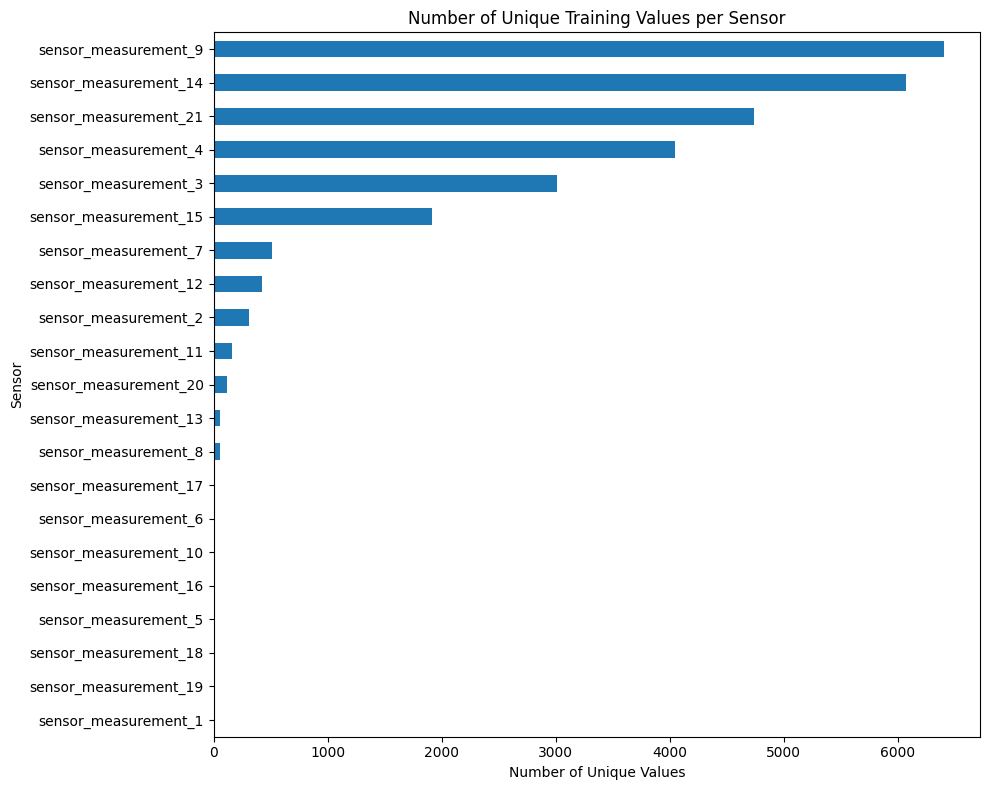

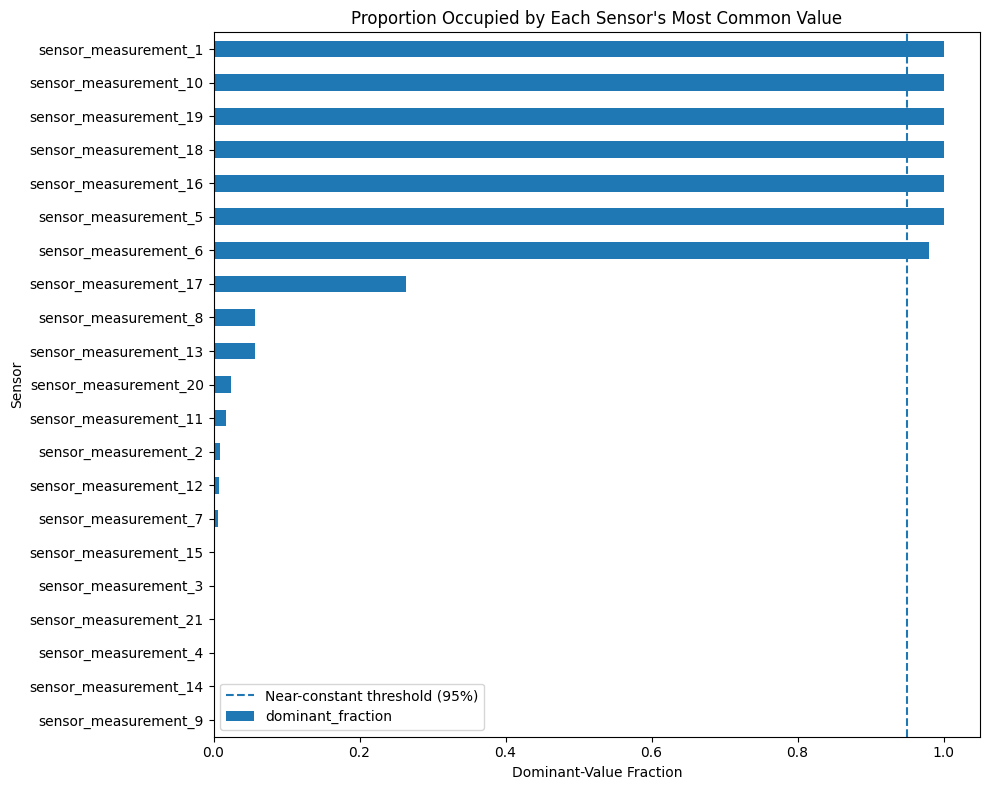

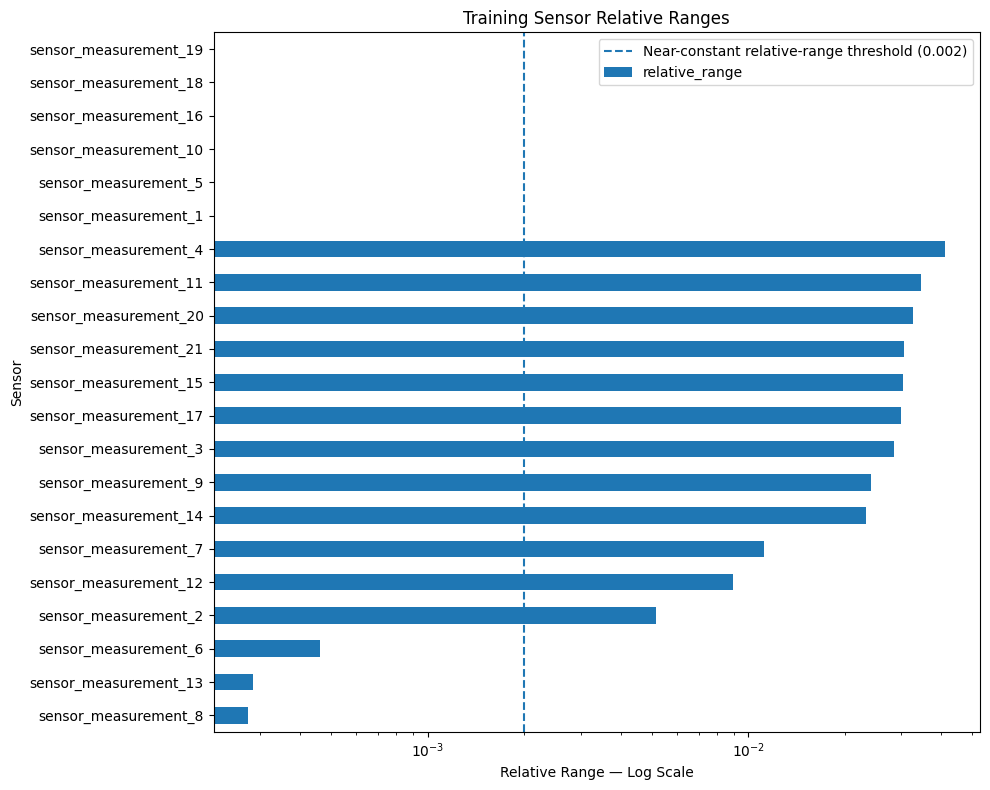


SECTION 8 SUMMARY

All 21 sensor columns were evaluated using their number of unique
values, standard deviation, variance, range, relative range, and the
proportion occupied by their most common value.

The training data contains 6 exactly constant
sensor columns:

['sensor_measurement_1', 'sensor_measurement_5', 'sensor_measurement_10', 'sensor_measurement_16', 'sensor_measurement_18', 'sensor_measurement_19']

These sensors contain no variation in the training data and therefore
cannot help a supervised model distinguish between observations.
They should be excluded from the modeling feature set.

The heuristic analysis identified 3
near-constant sensor candidates:

['sensor_measurement_6', 'sensor_measurement_8', 'sensor_measurement_13']

Near-constant sensors were flagged when at least
95% of their observations contained one
value or when their numerical range was less than or equal to
0.002 of their overall numerical scale.

Near-constant sensors will not be removed automatically

In [67]:
# ============================================================
# SECTION 8: CONSTANT AND NEAR-CONSTANT SENSORS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

# Define sensor columns if they do not already exist from Section 7.
if "sensor_cols" not in globals():
    sensor_cols = [
        f"sensor_measurement_{i}"
        for i in range(1, 22)
    ]

missing_train_sensors = [
    col for col in sensor_cols
    if col not in train_df.columns
]

missing_test_sensors = [
    col for col in sensor_cols
    if col not in test_df.columns
]

if missing_train_sensors or missing_test_sensors:
    raise ValueError(
        "Expected sensor columns are missing.\n"
        f"Missing from training: {missing_train_sensors}\n"
        f"Missing from test: {missing_test_sensors}"
    )


# These are EDA heuristics, not universal scientific thresholds.
DOMINANT_VALUE_THRESHOLD = 0.95
RELATIVE_RANGE_THRESHOLD = 0.002


# ------------------------------------------------------------
# Helper function
# ------------------------------------------------------------

def sensor_variability_report(
    df,
    columns,
    dominant_threshold=DOMINANT_VALUE_THRESHOLD,
    relative_range_threshold=RELATIVE_RANGE_THRESHOLD
):
    """
    Summarize sensor variability.

    Constant:
        Exactly one unique value.

    Near-constant candidate:
        More than one unique value, but either:
        1. At least 95% of rows contain the same value, or
        2. The total range is extremely small relative to the
           sensor's typical numerical scale.
    """

    rows = []

    for col in columns:
        series = df[col]

        value_counts = series.value_counts(
            dropna=False
        )

        unique_count = series.nunique(
            dropna=False
        )

        dominant_value = value_counts.index[0]
        dominant_count = int(value_counts.iloc[0])
        dominant_fraction = dominant_count / len(series)

        minimum = series.min()
        maximum = series.max()
        sensor_range = maximum - minimum
        mean = series.mean()
        std = series.std()

        # Use the largest meaningful magnitude as the scale.
        numerical_scale = max(
            abs(mean),
            abs(minimum),
            abs(maximum),
            np.finfo(float).eps
        )

        relative_range = (
            sensor_range / numerical_scale
        )

        is_constant = unique_count == 1

        is_near_constant = (
            not is_constant
            and (
                dominant_fraction
                >= dominant_threshold

                or relative_range
                <= relative_range_threshold
            )
        )

        rows.append({
            "sensor": col,
            "unique_count": unique_count,
            "unique_fraction": unique_count / len(series),
            "mean": mean,
            "std": std,
            "variance": series.var(),
            "minimum": minimum,
            "maximum": maximum,
            "range": sensor_range,
            "relative_range": relative_range,
            "dominant_value": dominant_value,
            "dominant_count": dominant_count,
            "dominant_fraction": dominant_fraction,
            "constant": is_constant,
            "near_constant_candidate": is_near_constant
        })

    return (
        pd.DataFrame(rows)
        .set_index("sensor")
    )


# ------------------------------------------------------------
# Create training and test variability reports
# ------------------------------------------------------------

train_sensor_report = sensor_variability_report(
    train_df,
    sensor_cols
)

test_sensor_report = sensor_variability_report(
    test_df,
    sensor_cols
)


# Combine selected train/test metrics into one comparison table.
sensor_comparison = (
    train_sensor_report.add_prefix("train_")
    .join(
        test_sensor_report.add_prefix("test_")
    )
)


# ------------------------------------------------------------
# Make feature decisions using TRAINING DATA ONLY
# ------------------------------------------------------------

constant_sensor_cols = (
    train_sensor_report
    .index[
        train_sensor_report["constant"]
    ]
    .tolist()
)

near_constant_sensor_cols = (
    train_sensor_report
    .index[
        train_sensor_report[
            "near_constant_candidate"
        ]
    ]
    .tolist()
)

variable_sensor_cols = [
    col for col in sensor_cols
    if col not in constant_sensor_cols
]

sensor_comparison["recommendation"] = "keep"

sensor_comparison.loc[
    near_constant_sensor_cols,
    "recommendation"
] = "review_near_constant"

sensor_comparison.loc[
    constant_sensor_cols,
    "recommendation"
] = "drop_constant"


# Sort the report so questionable sensors appear first.
recommendation_order = {
    "drop_constant": 0,
    "review_near_constant": 1,
    "keep": 2
}

sensor_comparison["recommendation_order"] = (
    sensor_comparison["recommendation"]
    .map(recommendation_order)
)

sensor_comparison = (
    sensor_comparison
    .sort_values(
        by=[
            "recommendation_order",
            "train_unique_count",
            "train_std"
        ]
    )
    .drop(columns="recommendation_order")
)


# ------------------------------------------------------------
# Display full sensor comparison
# ------------------------------------------------------------

display_columns = [
    "train_unique_count",
    "test_unique_count",
    "train_std",
    "test_std",
    "train_range",
    "test_range",
    "train_relative_range",
    "test_relative_range",
    "train_dominant_value",
    "train_dominant_fraction",
    "test_dominant_fraction",
    "train_constant",
    "test_constant",
    "train_near_constant_candidate",
    "test_near_constant_candidate",
    "recommendation"
]

print("=" * 80)
print("SENSOR VARIABILITY REPORT")
print("=" * 80)

display(
    sensor_comparison[display_columns]
)


# ------------------------------------------------------------
# Display sensor groups
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SECTION 8 SENSOR GROUPS")
print("=" * 80)

print(
    f"\nConstant training sensors "
    f"({len(constant_sensor_cols)}):"
)
print(constant_sensor_cols)

print(
    f"\nNear-constant training candidates "
    f"({len(near_constant_sensor_cols)}):"
)
print(near_constant_sensor_cols)

print(
    f"\nNonconstant sensors retained for now "
    f"({len(variable_sensor_cols)}):"
)
print(variable_sensor_cols)


# ------------------------------------------------------------
# Inspect value counts for questionable sensors
# ------------------------------------------------------------

sensors_to_inspect = (
    constant_sensor_cols
    + [
        col for col in near_constant_sensor_cols
        if col not in constant_sensor_cols
    ]
)

if sensors_to_inspect:
    print("\n" + "=" * 80)
    print("MOST COMMON VALUES FOR QUESTIONABLE SENSORS")
    print("=" * 80)

    for col in sensors_to_inspect:
        comparison = pd.concat(
            [
                train_df[col]
                .value_counts(dropna=False)
                .head(10)
                .rename("training_count"),

                test_df[col]
                .value_counts(dropna=False)
                .head(10)
                .rename("test_count")
            ],
            axis=1
        ).fillna(0)

        comparison["training_fraction"] = (
            comparison["training_count"]
            / len(train_df)
        )

        comparison["test_fraction"] = (
            comparison["test_count"]
            / len(test_df)
        )

        print(f"\n{col}")
        display(comparison)


# ------------------------------------------------------------
# Plot unique-value counts
# ------------------------------------------------------------

(
    train_sensor_report["unique_count"]
    .sort_values()
    .plot.barh(figsize=(10, 8))
)

plt.title(
    "Number of Unique Training Values per Sensor"
)
plt.xlabel("Number of Unique Values")
plt.ylabel("Sensor")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot dominant-value proportions
# ------------------------------------------------------------

(
    train_sensor_report["dominant_fraction"]
    .sort_values()
    .plot.barh(figsize=(10, 8))
)

plt.axvline(
    DOMINANT_VALUE_THRESHOLD,
    linestyle="--",
    label=(
        f"Near-constant threshold "
        f"({DOMINANT_VALUE_THRESHOLD:.0%})"
    )
)

plt.title(
    "Proportion Occupied by Each Sensor's Most Common Value"
)
plt.xlabel("Dominant-Value Fraction")
plt.ylabel("Sensor")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot relative ranges
# ------------------------------------------------------------

relative_ranges_for_plot = (
    train_sensor_report["relative_range"]
    .replace(0, np.nan)
    .sort_values()
)

relative_ranges_for_plot.plot.barh(
    figsize=(10, 8),
    logx=True
)

plt.axvline(
    RELATIVE_RANGE_THRESHOLD,
    linestyle="--",
    label=(
        "Near-constant relative-range threshold "
        f"({RELATIVE_RANGE_THRESHOLD})"
    )
)

plt.title(
    "Training Sensor Relative Ranges"
)
plt.xlabel("Relative Range — Log Scale")
plt.ylabel("Sensor")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Automated validation
# ------------------------------------------------------------

assert len(sensor_cols) == 21
assert train_sensor_report.shape[0] == 21
assert test_sensor_report.shape[0] == 21

assert set(constant_sensor_cols).isdisjoint(
    [
        col for col in variable_sensor_cols
    ]
)

assert all(
    train_df[col].nunique(dropna=False) == 1
    for col in constant_sensor_cols
)

assert all(
    train_df[col].nunique(dropna=False) > 1
    for col in variable_sensor_cols
)


# ------------------------------------------------------------
# Written Section 8 summary
# ------------------------------------------------------------

section_8_summary = f"""
SECTION 8 SUMMARY

All 21 sensor columns were evaluated using their number of unique
values, standard deviation, variance, range, relative range, and the
proportion occupied by their most common value.

The training data contains {len(constant_sensor_cols)} exactly constant
sensor columns:

{constant_sensor_cols}

These sensors contain no variation in the training data and therefore
cannot help a supervised model distinguish between observations.
They should be excluded from the modeling feature set.

The heuristic analysis identified {len(near_constant_sensor_cols)}
near-constant sensor candidates:

{near_constant_sensor_cols}

Near-constant sensors were flagged when at least
{DOMINANT_VALUE_THRESHOLD:.0%} of their observations contained one
value or when their numerical range was less than or equal to
{RELATIVE_RANGE_THRESHOLD} of their overall numerical scale.

Near-constant sensors will not be removed automatically. Their behavior
should be considered alongside temporal patterns, relationships with
RUL, and validation performance. Feature-removal decisions were based
only on the training data; the test data was used only as a structural
comparison.

The working nonconstant sensor list contains
{len(variable_sensor_cols)} sensors.
"""

print("\n" + "=" * 80)
print(section_8_summary.strip())
print("=" * 80)

print("\nSection 8 completed successfully.")

### Section 9: Feature Distributions

FEATURE DISTRIBUTION COMPARISON


,train_unique_count,train_mean,train_std,train_minimum,train_q1,train_median,train_q3,train_maximum,train_skewness,train_kurtosis,train_iqr_outlier_count,train_iqr_outlier_fraction,test_mean,test_std,standardized_mean_difference,test_outside_train_range_fraction,EDA_status
feature,,,,,,,,,,,,,,,,,
op_setting_1,158,-0.0000,0.0022,-0.0087,-0.0015,0.0000,0.0015,0.0087,-0.0248,-0.0091,105,0.0051,-0.0000,0.0022,-0.0011,0.0000,no_obvious_issue
op_setting_2,13,0.0000,0.0003,-0.0006,-0.0002,0.0000,0.0003,0.0006,0.0091,-1.1304,0,0.0000,0.0000,0.0003,0.0064,0.0004,no_obvious_issue
op_setting_3,1,100.0000,0.0000,100.0000,100.0000,100.0000,100.0000,100.0000,0.0000,0.0000,0,0.0000,100.0000,0.0000,NaN,0.0000,constant
sensor_measurement_1,1,518.6700,0.0000,518.6700,518.6700,518.6700,518.6700,518.6700,0.0000,0.0000,0,0.0000,518.6700,0.0000,NaN,0.0000,constant
sensor_measurement_2,310,642.6809,0.5001,641.2100,642.3250,642.6400,643.0000,644.5300,0.3165,-0.1120,128,0.0062,642.4751,0.4009,-0.4116,0.0002,possible_train_test_shift
sensor_measurement_3,3012,1590.5231,6.1311,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100,0.3089,0.0078,165,0.0080,1588.0992,5.0033,-0.3953,0.0002,possible_train_test_shift
sensor_measurement_4,4051,1408.9338,9.0006,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900,0.4432,-0.1637,120,0.0058,1404.7354,6.6883,-0.4665,0.0000,possible_train_test_shift
sensor_measurement_5,1,14.6200,0.0000,14.6200,14.6200,14.6200,14.6200,14.6200,-1.0001,-2.0002,0,0.0000,14.6200,0.0000,-0.6667,0.0000,"constant, skewed, possible_train_test_shift"
sensor_measurement_6,2,21.6098,0.0014,21.6000,21.6100,21.6100,21.6100,21.6100,-6.9168,45.8467,0,0.0000,21.6097,0.0017,-0.0738,0.0000,skewed



FEATURE GROUPS FROM DISTRIBUTION ANALYSIS

Constant raw features (7):
['op_setting_3', 'sensor_measurement_1', 'sensor_measurement_5', 'sensor_measurement_10', 'sensor_measurement_16', 'sensor_measurement_18', 'sensor_measurement_19']

Highly skewed training features (4):
['sensor_measurement_5', 'sensor_measurement_6', 'sensor_measurement_9', 'sensor_measurement_14']

Features with at least 5% IQR-flagged observations (2):
['sensor_measurement_9', 'sensor_measurement_14']

Possible train/test distribution-shift candidates (16):
['sensor_measurement_2', 'sensor_measurement_3', 'sensor_measurement_4', 'sensor_measurement_5', 'sensor_measurement_7', 'sensor_measurement_8', 'sensor_measurement_9', 'sensor_measurement_11', 'sensor_measurement_12', 'sensor_measurement_13', 'sensor_measurement_14', 'sensor_measurement_15', 'sensor_measurement_16', 'sensor_measurement_17', 'sensor_measurement_20', 'sensor_measurement_21']


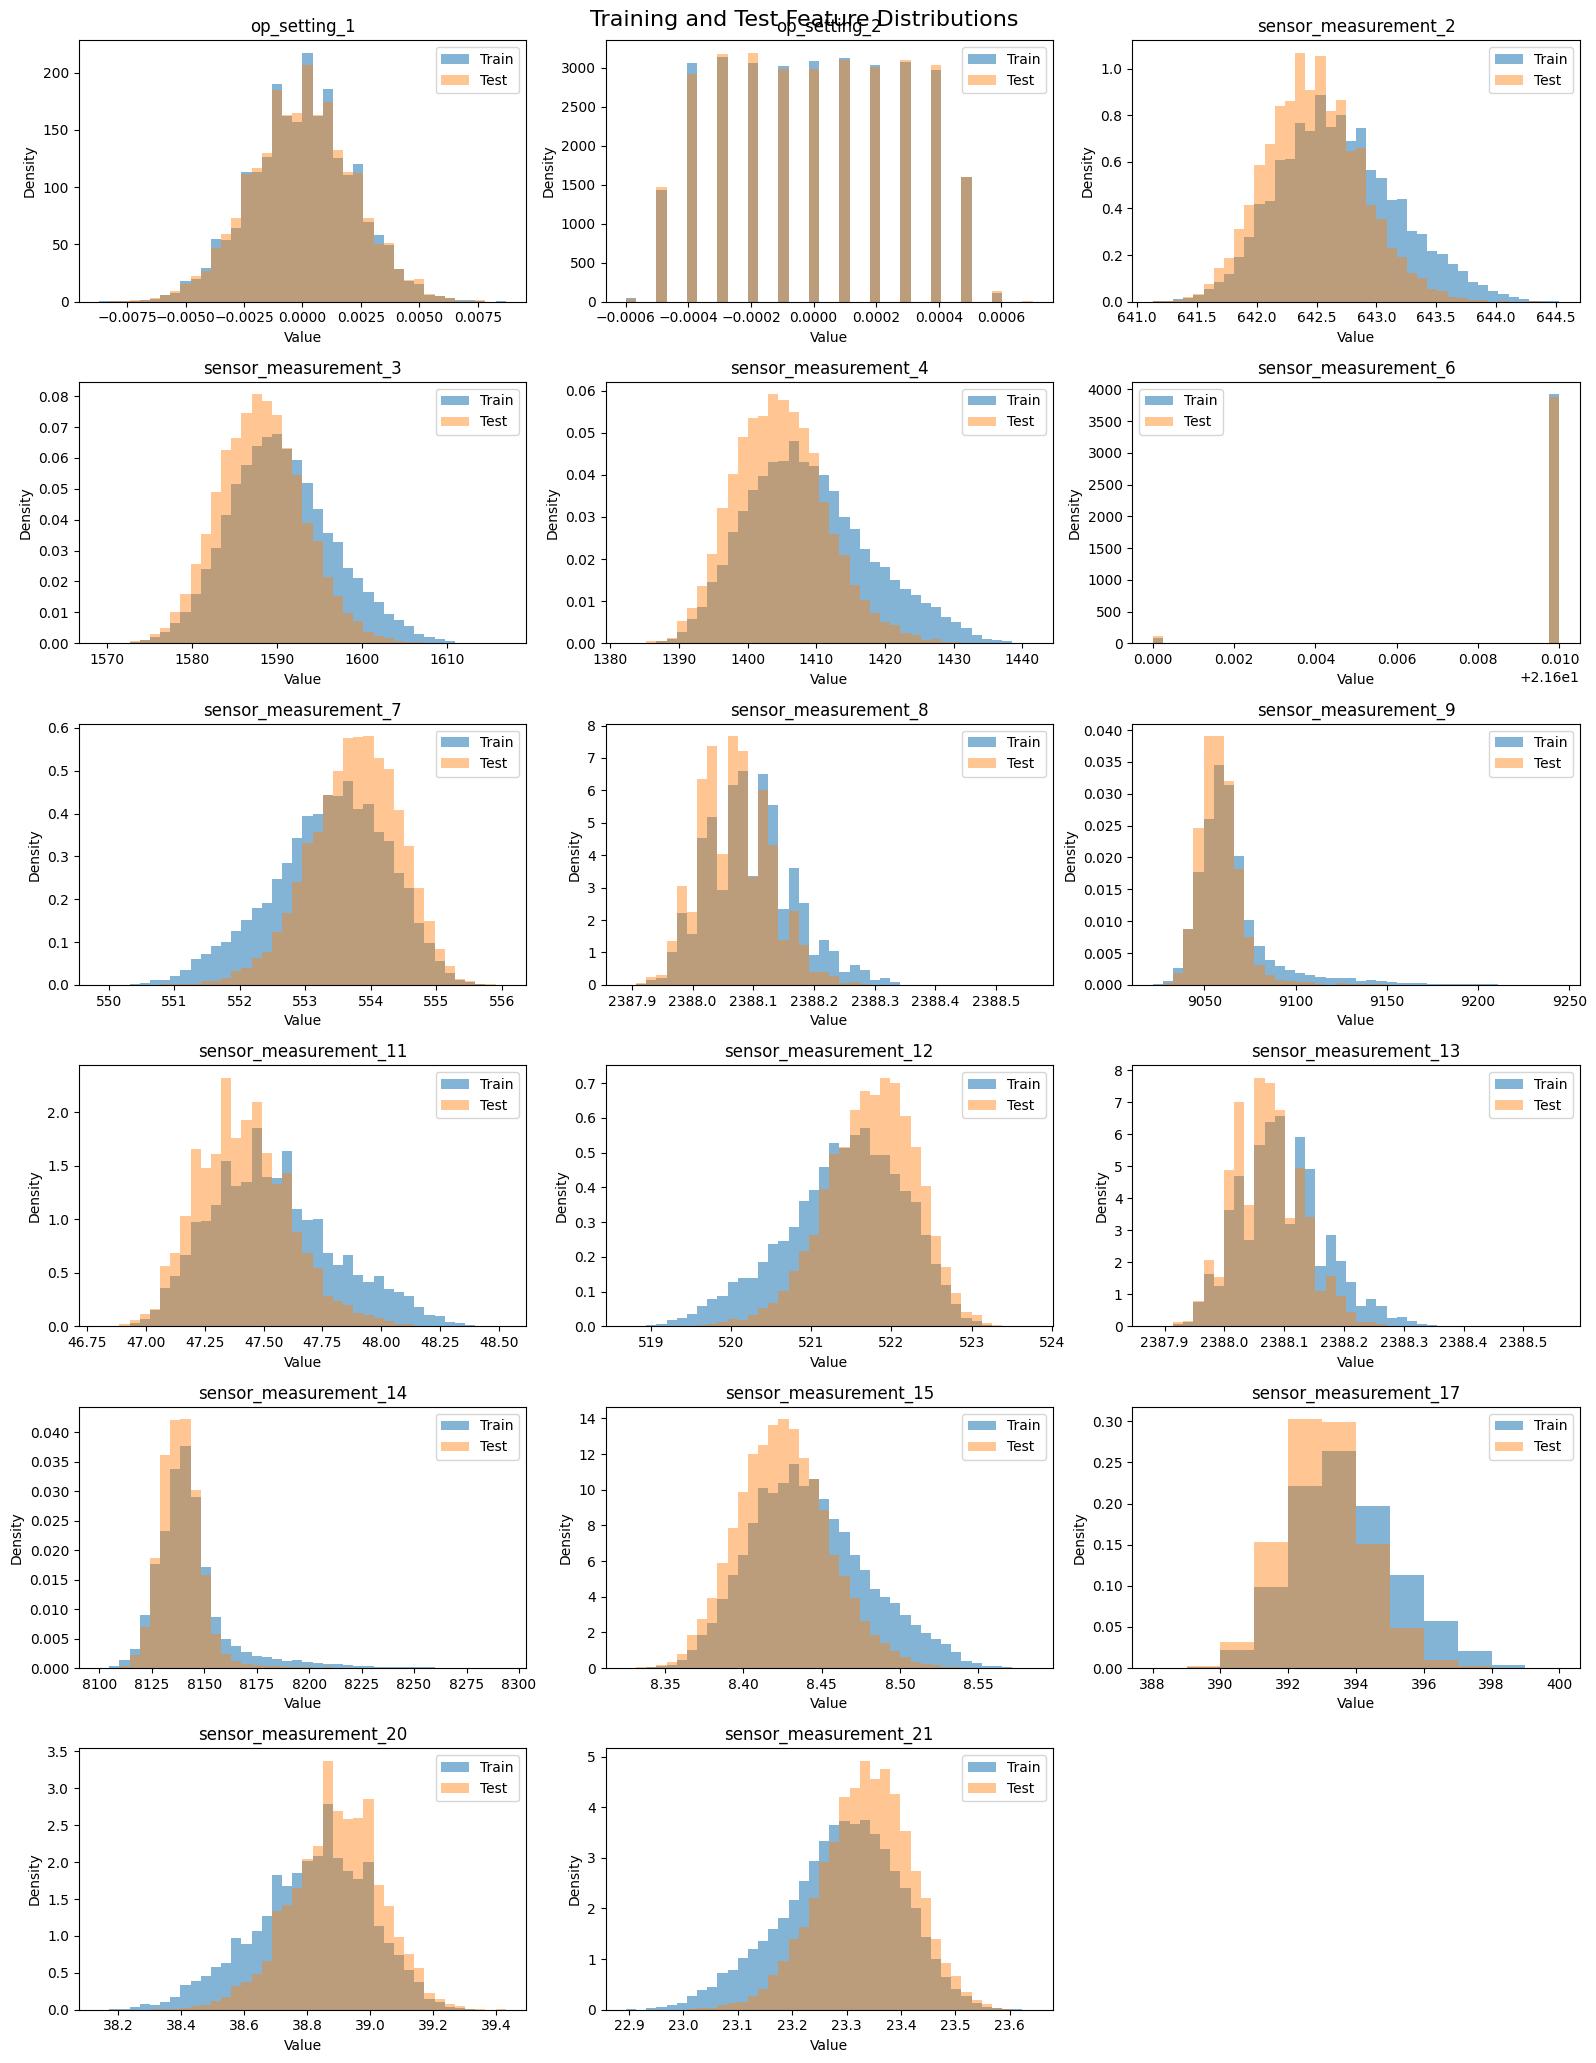

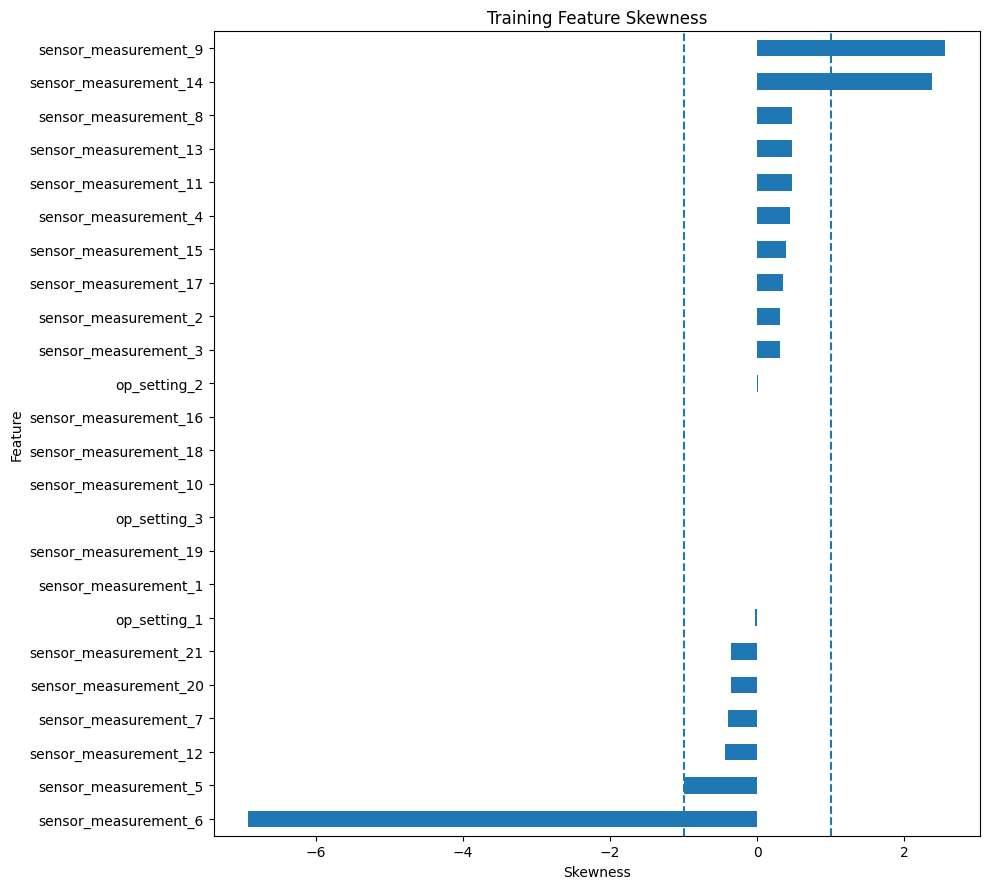

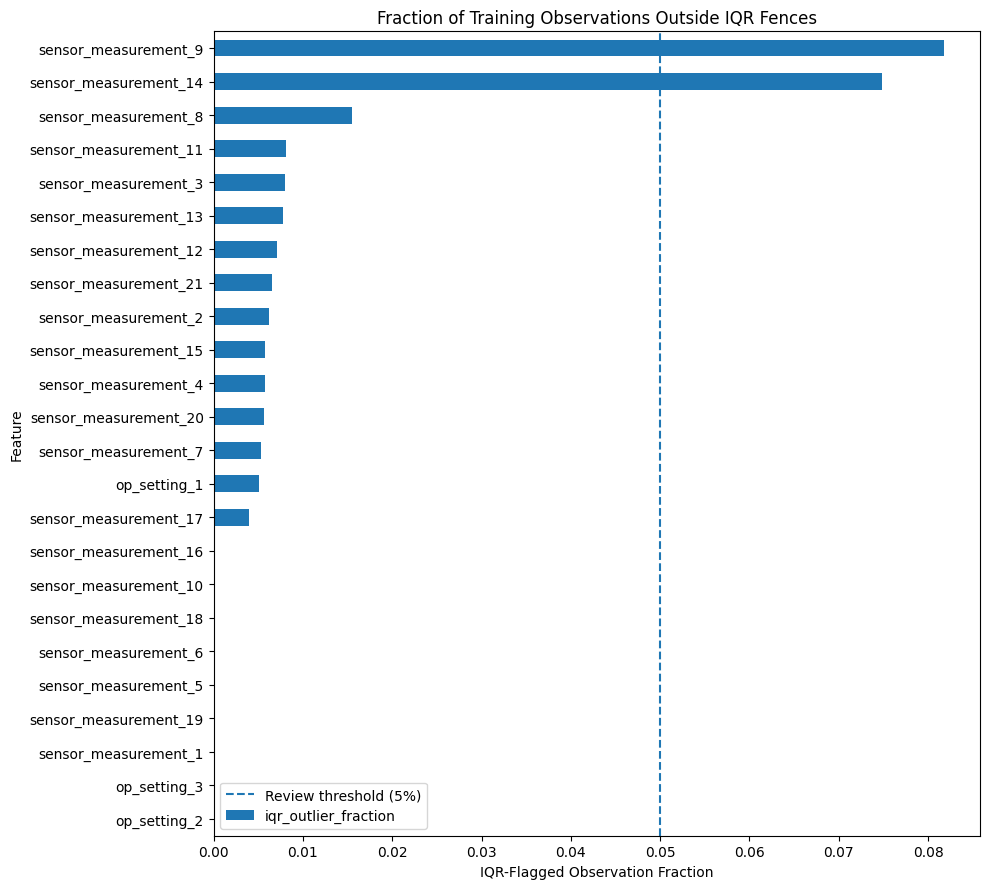

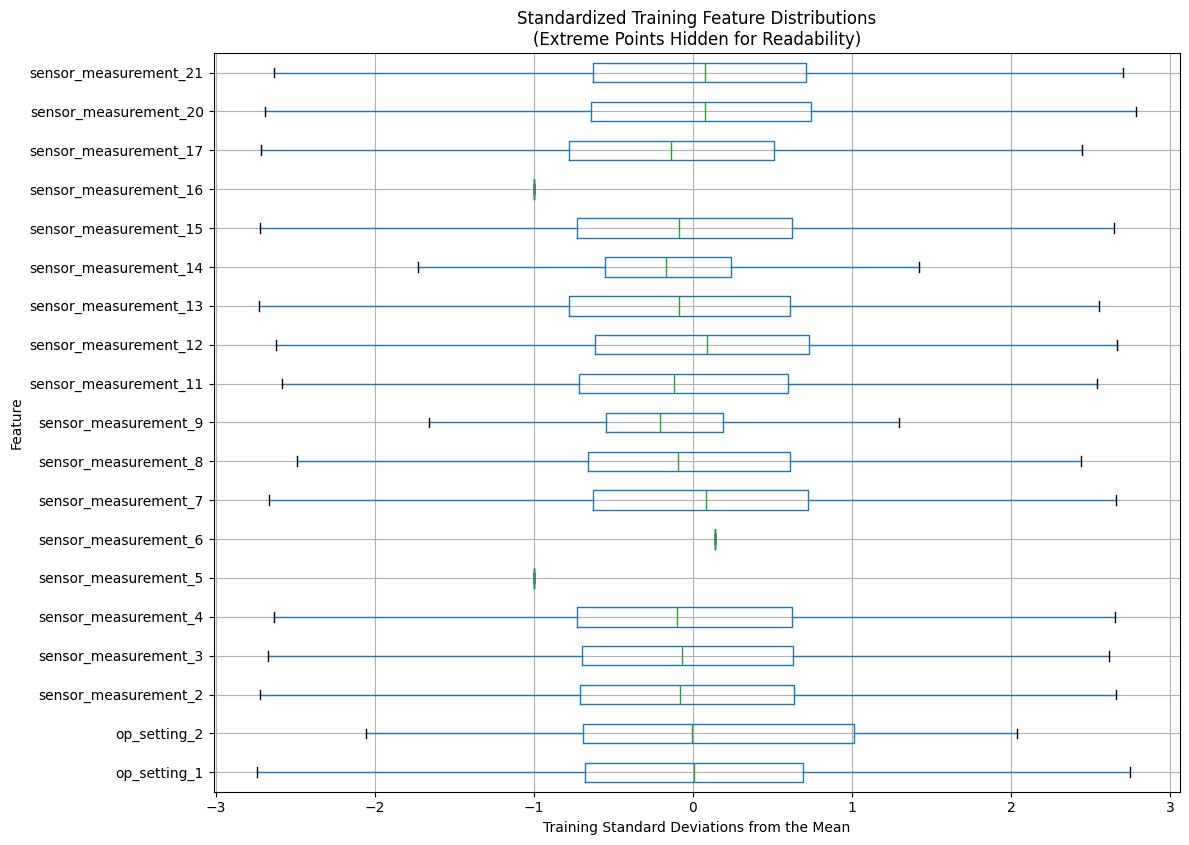


SECTION 9 SUMMARY

The distributions of all 24 raw features were
examined in the training and test datasets. The analysis included
central tendency, spread, quartiles, skewness, kurtosis, unique-value
counts, zero frequencies, IQR-based outlier flags, and train/test
distribution comparisons.

The training data contained 7 constant raw
features:

['op_setting_3', 'sensor_measurement_1', 'sensor_measurement_5', 'sensor_measurement_10', 'sensor_measurement_16', 'sensor_measurement_18', 'sensor_measurement_19']

A total of 4 features had an absolute
training skewness of at least 1.0:

['sensor_measurement_5', 'sensor_measurement_6', 'sensor_measurement_9', 'sensor_measurement_14']

A total of 2 features had at
least 5% of training observations
outside the conventional 1.5-IQR fences:

['sensor_measurement_9', 'sensor_measurement_14']

These observations are not automatically erroneous. C-MAPSS contains
time-dependent degradation trajectories, so extreme values may
represent legitimate lat

In [68]:
# ============================================================
# SECTION 9: FEATURE DISTRIBUTIONS
# ============================================================

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ------------------------------------------------------------
# 9-1: Define feature columns
# ------------------------------------------------------------

if "setting_cols" not in globals():
    setting_cols = [
        "op_setting_1",
        "op_setting_2",
        "op_setting_3"
    ]

if "sensor_cols" not in globals():
    sensor_cols = [
        f"sensor_measurement_{i}"
        for i in range(1, 22)
    ]

raw_feature_cols = setting_cols + sensor_cols

missing_train_features = [
    col for col in raw_feature_cols
    if col not in train_df.columns
]

missing_test_features = [
    col for col in raw_feature_cols
    if col not in test_df.columns
]

if missing_train_features or missing_test_features:
    raise ValueError(
        "Expected feature columns are missing.\n"
        f"Missing from training: {missing_train_features}\n"
        f"Missing from test: {missing_test_features}"
    )


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

# These thresholds are EDA heuristics, not universal rules.
ABS_SKEW_THRESHOLD = 1.0
IQR_OUTLIER_FRACTION_THRESHOLD = 0.05
STANDARDIZED_MEAN_SHIFT_THRESHOLD = 0.25
OUTSIDE_TRAIN_RANGE_THRESHOLD = 0.01


# ------------------------------------------------------------
# 9-2: Build a distribution report
# ------------------------------------------------------------

def create_distribution_report(df, columns):
    """
    Summarize feature distributions and flag statistical outliers.

    IQR outliers are observations below:

        Q1 - 1.5 * IQR

    or above:

        Q3 + 1.5 * IQR

    These are statistical flags, not automatically bad data.
    """

    rows = []

    for col in columns:
        series = df[col].dropna()

        q1 = series.quantile(0.25)
        median = series.quantile(0.50)
        q3 = series.quantile(0.75)

        iqr = q3 - q1
        lower_fence = q1 - 1.5 * iqr
        upper_fence = q3 + 1.5 * iqr

        if iqr == 0:
            iqr_outlier_mask = pd.Series(
                False,
                index=series.index
            )
        else:
            iqr_outlier_mask = (
                series.lt(lower_fence)
                | series.gt(upper_fence)
            )

        rows.append({
            "feature": col,
            "count": len(series),
            "unique_count": series.nunique(),
            "mean": series.mean(),
            "std": series.std(),
            "minimum": series.min(),
            "q1": q1,
            "median": median,
            "q3": q3,
            "maximum": series.max(),
            "range": series.max() - series.min(),
            "iqr": iqr,
            "skewness": series.skew(),
            "kurtosis": series.kurt(),
            "zero_count": int(series.eq(0).sum()),
            "zero_fraction": series.eq(0).mean(),
            "iqr_lower_fence": lower_fence,
            "iqr_upper_fence": upper_fence,
            "iqr_outlier_count":
                int(iqr_outlier_mask.sum()),
            "iqr_outlier_fraction":
                iqr_outlier_mask.mean(),
            "constant": series.nunique() == 1
        })

    return (
        pd.DataFrame(rows)
        .set_index("feature")
    )


train_distribution_report = create_distribution_report(
    train_df,
    raw_feature_cols
)

test_distribution_report = create_distribution_report(
    test_df,
    raw_feature_cols
)


# ------------------------------------------------------------
# 9-3: Compare training and test distributions
# ------------------------------------------------------------

distribution_comparison = (
    train_distribution_report
    .add_prefix("train_")
    .join(
        test_distribution_report
        .add_prefix("test_")
    )
)

train_std_safe = (
    distribution_comparison["train_std"]
    .replace(0, np.nan)
)

train_iqr_safe = (
    distribution_comparison["train_iqr"]
    .replace(0, np.nan)
)

distribution_comparison[
    "standardized_mean_difference"
] = (
    (
        distribution_comparison["test_mean"]
        - distribution_comparison["train_mean"]
    )
    / train_std_safe
)

distribution_comparison[
    "normalized_median_difference"
] = (
    (
        distribution_comparison["test_median"]
        - distribution_comparison["train_median"]
    )
    / train_iqr_safe
)


# Fraction of test observations outside the training range.
test_below_train_min_fraction = {}
test_above_train_max_fraction = {}

for col in raw_feature_cols:
    train_min = train_df[col].min()
    train_max = train_df[col].max()

    test_below_train_min_fraction[col] = (
        test_df[col].lt(train_min).mean()
    )

    test_above_train_max_fraction[col] = (
        test_df[col].gt(train_max).mean()
    )

distribution_comparison[
    "test_below_train_min_fraction"
] = pd.Series(test_below_train_min_fraction)

distribution_comparison[
    "test_above_train_max_fraction"
] = pd.Series(test_above_train_max_fraction)

distribution_comparison[
    "test_outside_train_range_fraction"
] = (
    distribution_comparison[
        "test_below_train_min_fraction"
    ]
    + distribution_comparison[
        "test_above_train_max_fraction"
    ]
)


# ------------------------------------------------------------
# 9-4: Create EDA flags
# ------------------------------------------------------------

distribution_comparison[
    "high_absolute_skew"
] = (
    distribution_comparison["train_skewness"]
    .abs()
    .ge(ABS_SKEW_THRESHOLD)
)

distribution_comparison[
    "high_iqr_outlier_fraction"
] = (
    distribution_comparison[
        "train_iqr_outlier_fraction"
    ]
    .ge(IQR_OUTLIER_FRACTION_THRESHOLD)
)

distribution_comparison[
    "possible_mean_shift"
] = (
    distribution_comparison[
        "standardized_mean_difference"
    ]
    .abs()
    .ge(STANDARDIZED_MEAN_SHIFT_THRESHOLD)
)

distribution_comparison[
    "test_range_extrapolation"
] = (
    distribution_comparison[
        "test_outside_train_range_fraction"
    ]
    .ge(OUTSIDE_TRAIN_RANGE_THRESHOLD)
)


def assign_distribution_status(row):
    concerns = []

    if row["train_constant"]:
        concerns.append("constant")

    if row["high_absolute_skew"]:
        concerns.append("skewed")

    if row["high_iqr_outlier_fraction"]:
        concerns.append("many_IQR_outliers")

    if row["possible_mean_shift"]:
        concerns.append("possible_train_test_shift")

    if row["test_range_extrapolation"]:
        concerns.append("test_outside_train_range")

    if not concerns:
        return "no_obvious_issue"

    return ", ".join(concerns)


distribution_comparison["EDA_status"] = (
    distribution_comparison.apply(
        assign_distribution_status,
        axis=1
    )
)


# ------------------------------------------------------------
# 9-5: Display the main report
# ------------------------------------------------------------

main_display_columns = [
    "train_unique_count",
    "train_mean",
    "train_std",
    "train_minimum",
    "train_q1",
    "train_median",
    "train_q3",
    "train_maximum",
    "train_skewness",
    "train_kurtosis",
    "train_iqr_outlier_count",
    "train_iqr_outlier_fraction",
    "test_mean",
    "test_std",
    "standardized_mean_difference",
    "test_outside_train_range_fraction",
    "EDA_status"
]

print("=" * 90)
print("FEATURE DISTRIBUTION COMPARISON")
print("=" * 90)

display(
    distribution_comparison[
        main_display_columns
    ].round(4)
)


# ------------------------------------------------------------
# 9-6: Create useful feature lists
# ------------------------------------------------------------

constant_feature_cols = (
    distribution_comparison.index[
        distribution_comparison["train_constant"]
    ]
    .tolist()
)

variable_feature_cols = [
    col for col in raw_feature_cols
    if col not in constant_feature_cols
]

highly_skewed_feature_cols = (
    distribution_comparison.index[
        distribution_comparison[
            "high_absolute_skew"
        ]
    ]
    .tolist()
)

high_outlier_fraction_feature_cols = (
    distribution_comparison.index[
        distribution_comparison[
            "high_iqr_outlier_fraction"
        ]
    ]
    .tolist()
)

possible_distribution_shift_cols = (
    distribution_comparison.index[
        distribution_comparison[
            "possible_mean_shift"
        ]
        | distribution_comparison[
            "test_range_extrapolation"
        ]
    ]
    .tolist()
)


print("\n" + "=" * 90)
print("FEATURE GROUPS FROM DISTRIBUTION ANALYSIS")
print("=" * 90)

print(
    f"\nConstant raw features "
    f"({len(constant_feature_cols)}):"
)
print(constant_feature_cols)

print(
    f"\nHighly skewed training features "
    f"({len(highly_skewed_feature_cols)}):"
)
print(highly_skewed_feature_cols)

print(
    f"\nFeatures with at least "
    f"{IQR_OUTLIER_FRACTION_THRESHOLD:.0%} "
    "IQR-flagged observations "
    f"({len(high_outlier_fraction_feature_cols)}):"
)
print(high_outlier_fraction_feature_cols)

print(
    "\nPossible train/test distribution-shift "
    f"candidates ({len(possible_distribution_shift_cols)}):"
)
print(possible_distribution_shift_cols)


# ------------------------------------------------------------
# 9-7: Plot train/test histograms
# ------------------------------------------------------------

plot_feature_cols = [
    col for col in raw_feature_cols
    if (
        train_df[col].nunique() > 1
        or test_df[col].nunique() > 1
    )
]

number_of_plot_columns = 3
number_of_plot_rows = math.ceil(
    len(plot_feature_cols)
    / number_of_plot_columns
)

fig, axes = plt.subplots(
    number_of_plot_rows,
    number_of_plot_columns,
    figsize=(
        16,
        number_of_plot_rows * 3.5
    )
)

axes = np.asarray(axes).reshape(-1)

for ax, col in zip(axes, plot_feature_cols):
    combined_values = pd.concat(
        [
            train_df[col],
            test_df[col]
        ],
        ignore_index=True
    ).dropna()

    if combined_values.nunique() <= 1:
        bins = 1
    else:
        bin_edges = np.histogram_bin_edges(
            combined_values,
            bins="auto"
        )

        # Prevent overly dense plots.
        if len(bin_edges) > 41:
            bin_edges = np.linspace(
                combined_values.min(),
                combined_values.max(),
                41
            )

        bins = bin_edges

    ax.hist(
        train_df[col],
        bins=bins,
        density=True,
        alpha=0.55,
        label="Train"
    )

    ax.hist(
        test_df[col],
        bins=bins,
        density=True,
        alpha=0.45,
        label="Test"
    )

    ax.set_title(col)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.legend()

for unused_ax in axes[len(plot_feature_cols):]:
    unused_ax.remove()

fig.suptitle(
    "Training and Test Feature Distributions",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9-8: Plot training skewness
# ------------------------------------------------------------

training_skewness = (
    train_distribution_report["skewness"]
    .dropna()
    .sort_values()
)

plt.figure(figsize=(10, 9))

training_skewness.plot.barh()

plt.axvline(
    -ABS_SKEW_THRESHOLD,
    linestyle="--"
)

plt.axvline(
    ABS_SKEW_THRESHOLD,
    linestyle="--"
)

plt.title("Training Feature Skewness")
plt.xlabel("Skewness")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9-9: Plot IQR outlier fractions
# ------------------------------------------------------------

training_outlier_fractions = (
    train_distribution_report[
        "iqr_outlier_fraction"
    ]
    .sort_values()
)

plt.figure(figsize=(10, 9))

training_outlier_fractions.plot.barh()

plt.axvline(
    IQR_OUTLIER_FRACTION_THRESHOLD,
    linestyle="--",
    label=(
        "Review threshold "
        f"({IQR_OUTLIER_FRACTION_THRESHOLD:.0%})"
    )
)

plt.title(
    "Fraction of Training Observations Outside IQR Fences"
)
plt.xlabel("IQR-Flagged Observation Fraction")
plt.ylabel("Feature")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9-10: Standardized boxplots
# ------------------------------------------------------------

nonconstant_train_features = [
    col for col in raw_feature_cols
    if train_df[col].std() > 0
]

standardized_train_features = (
    train_df[nonconstant_train_features]
    - train_df[nonconstant_train_features].mean()
) / train_df[nonconstant_train_features].std()

plt.figure(
    figsize=(
        12,
        max(8, len(nonconstant_train_features) * 0.45)
    )
)

standardized_train_features.boxplot(
    vert=False,
    showfliers=False
)

plt.title(
    "Standardized Training Feature Distributions\n"
    "(Extreme Points Hidden for Readability)"
)
plt.xlabel("Training Standard Deviations from the Mean")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9-11: Validate the generated reports
# ------------------------------------------------------------

assert len(raw_feature_cols) == 24
assert train_distribution_report.shape[0] == 24
assert test_distribution_report.shape[0] == 24

assert (
    train_distribution_report.index.tolist()
    == raw_feature_cols
)

assert (
    test_distribution_report.index.tolist()
    == raw_feature_cols
)

assert (
    train_distribution_report["count"]
    .eq(len(train_df))
    .all()
)

assert (
    test_distribution_report["count"]
    .eq(len(test_df))
    .all()
)

assert (
    train_distribution_report[
        "iqr_outlier_fraction"
    ]
    .between(0, 1)
    .all()
)

assert (
    test_distribution_report[
        "iqr_outlier_fraction"
    ]
    .between(0, 1)
    .all()
)


# ------------------------------------------------------------
# 9-12: Written Section 9 summary
# ------------------------------------------------------------

section_9_summary = f"""
SECTION 9 SUMMARY

The distributions of all {len(raw_feature_cols)} raw features were
examined in the training and test datasets. The analysis included
central tendency, spread, quartiles, skewness, kurtosis, unique-value
counts, zero frequencies, IQR-based outlier flags, and train/test
distribution comparisons.

The training data contained {len(constant_feature_cols)} constant raw
features:

{constant_feature_cols}

A total of {len(highly_skewed_feature_cols)} features had an absolute
training skewness of at least {ABS_SKEW_THRESHOLD}:

{highly_skewed_feature_cols}

A total of {len(high_outlier_fraction_feature_cols)} features had at
least {IQR_OUTLIER_FRACTION_THRESHOLD:.0%} of training observations
outside the conventional 1.5-IQR fences:

{high_outlier_fraction_feature_cols}

These observations are not automatically erroneous. C-MAPSS contains
time-dependent degradation trajectories, so extreme values may
represent legitimate late-life behavior rather than data corruption.

A total of {len(possible_distribution_shift_cols)} features were
flagged for possible train/test distribution differences based on
standardized mean differences or test observations extending outside
the training range:

{possible_distribution_shift_cols}

No values were removed, clipped, transformed, or imputed during this
section. Skewness, IQR outliers, and train/test differences were treated
as EDA findings that may influence later preprocessing and modeling
experiments.

Feature behavior over time within individual engines will be examined
in Section 10.
"""

print("\n" + "=" * 90)
print(section_9_summary.strip())
print("=" * 90)

print("\nSection 9 completed successfully.")

### Section 10: Sensor Behavior Over Time for Individual Engines

SECTION 10 SENSOR SETUP
Nonconstant sensors analyzed: 15
['sensor_measurement_2', 'sensor_measurement_3', 'sensor_measurement_4', 'sensor_measurement_6', 'sensor_measurement_7', 'sensor_measurement_8', 'sensor_measurement_9', 'sensor_measurement_11', 'sensor_measurement_12', 'sensor_measurement_13', 'sensor_measurement_14', 'sensor_measurement_15', 'sensor_measurement_17', 'sensor_measurement_20', 'sensor_measurement_21']

Constant sensors excluded from trajectory analysis: 6
['sensor_measurement_1', 'sensor_measurement_5', 'sensor_measurement_10', 'sensor_measurement_16', 'sensor_measurement_18', 'sensor_measurement_19']

ENGINE SEQUENCE-LENGTH SUMMARY


,sequence_length
count,100.000000
mean,206.310000
std,46.342749
min,128.000000
25%,177.000000
50%,199.000000
75%,229.250000
max,362.000000



REPRESENTATIVE ENGINES


,unit_no,sequence_length,initial_rul,final_rul
representative_group,,,,
Shortest-lived,39,128,127,0
Median-lived,26,199,198,0
Longest-lived,69,362,361,0



AGGREGATED SENSOR TREND SUMMARY


,engines_analyzed,median_cycle_correlation,median_absolute_cycle_correlation,median_spearman_correlation,strong_positive_fraction,strong_negative_fraction,direction_agreement,median_standardized_early_late_change,median_absolute_standardized_change,median_standardized_linear_change,median_positive_step_fraction,median_negative_step_fraction,behavior_class
sensor,,,,,,,,,,,,,
sensor_measurement_11,100,0.8163,0.8163,0.8190,1.00,0.00,1.0000,2.3352,2.3352,2.8033,0.4975,0.4725,generally_increasing
sensor_measurement_12,100,-0.8106,0.8106,-0.8075,0.00,1.00,1.0000,-2.3238,2.3238,-2.7905,0.4834,0.5079,generally_decreasing
sensor_measurement_4,100,0.7904,0.7904,0.7840,1.00,0.00,1.0000,2.2658,2.2658,2.7161,0.5081,0.4907,generally_increasing
sensor_measurement_7,100,-0.7831,0.7831,-0.7742,0.00,1.00,1.0000,-2.2282,2.2282,-2.6891,0.4806,0.5116,generally_decreasing
sensor_measurement_14,100,0.6703,0.7814,0.6634,0.55,0.26,0.6000,1.9056,2.2588,2.3053,0.5032,0.4921,mixed_nonlinear_or_noisy
sensor_measurement_8,100,0.7776,0.7776,0.7684,0.81,0.00,1.0000,2.1850,2.1850,2.6737,0.4621,0.4472,generally_increasing
sensor_measurement_13,100,0.7742,0.7742,0.7620,0.83,0.00,1.0000,2.2072,2.2072,2.6617,0.4589,0.4478,generally_increasing
sensor_measurement_9,100,0.7466,0.7535,0.7392,0.59,0.14,0.7100,2.1221,2.1848,2.5724,0.5077,0.4915,mixed_nonlinear_or_noisy
sensor_measurement_15,100,0.7350,0.7350,0.7210,1.00,0.00,1.0000,2.0990,2.0990,2.5291,0.5074,0.4910,generally_increasing



Generally increasing sensors:
['sensor_measurement_11', 'sensor_measurement_4', 'sensor_measurement_8', 'sensor_measurement_13', 'sensor_measurement_15', 'sensor_measurement_2', 'sensor_measurement_17', 'sensor_measurement_3']

Generally decreasing sensors:
['sensor_measurement_12', 'sensor_measurement_7', 'sensor_measurement_21', 'sensor_measurement_20']

Weak or inconsistent sensors:
['sensor_measurement_6']

Mixed, nonlinear, or noisy sensors:
['sensor_measurement_14', 'sensor_measurement_9']

REPRESENTATIVE-ENGINE TREND METRICS


,engine_group,unit_no,sensor,pearson_cycle_correlation,spearman_cycle_correlation,standardized_early_to_late_change,standardized_linear_change,positive_step_fraction,negative_step_fraction
1027,Longest-lived,69,sensor_measurement_11,0.8485,0.8626,2.4438,2.9270,0.4903,0.4792
1028,Longest-lived,69,sensor_measurement_12,-0.8348,-0.8325,-2.3522,-2.8800,0.4765,0.5125
1029,Longest-lived,69,sensor_measurement_13,0.8479,0.8549,2.4539,2.9252,0.4488,0.4183
1030,Longest-lived,69,sensor_measurement_14,-0.5623,-0.5506,-1.5678,-1.9396,0.4903,0.5097
1031,Longest-lived,69,sensor_measurement_15,0.7579,0.7436,2.1382,2.6146,0.4792,0.5180
1032,Longest-lived,69,sensor_measurement_17,0.6919,0.6803,2.0945,2.3871,0.3629,0.3546
1020,Longest-lived,69,sensor_measurement_2,0.6912,0.6749,1.9486,2.3844,0.4737,0.5208
1033,Longest-lived,69,sensor_measurement_20,-0.7428,-0.7326,-2.1500,-2.5625,0.4792,0.4958
1034,Longest-lived,69,sensor_measurement_21,-0.7463,-0.7316,-2.2080,-2.5746,0.4986,0.5014
1021,Longest-lived,69,sensor_measurement_3,0.6178,0.5982,1.7325,2.1313,0.5180,0.4792


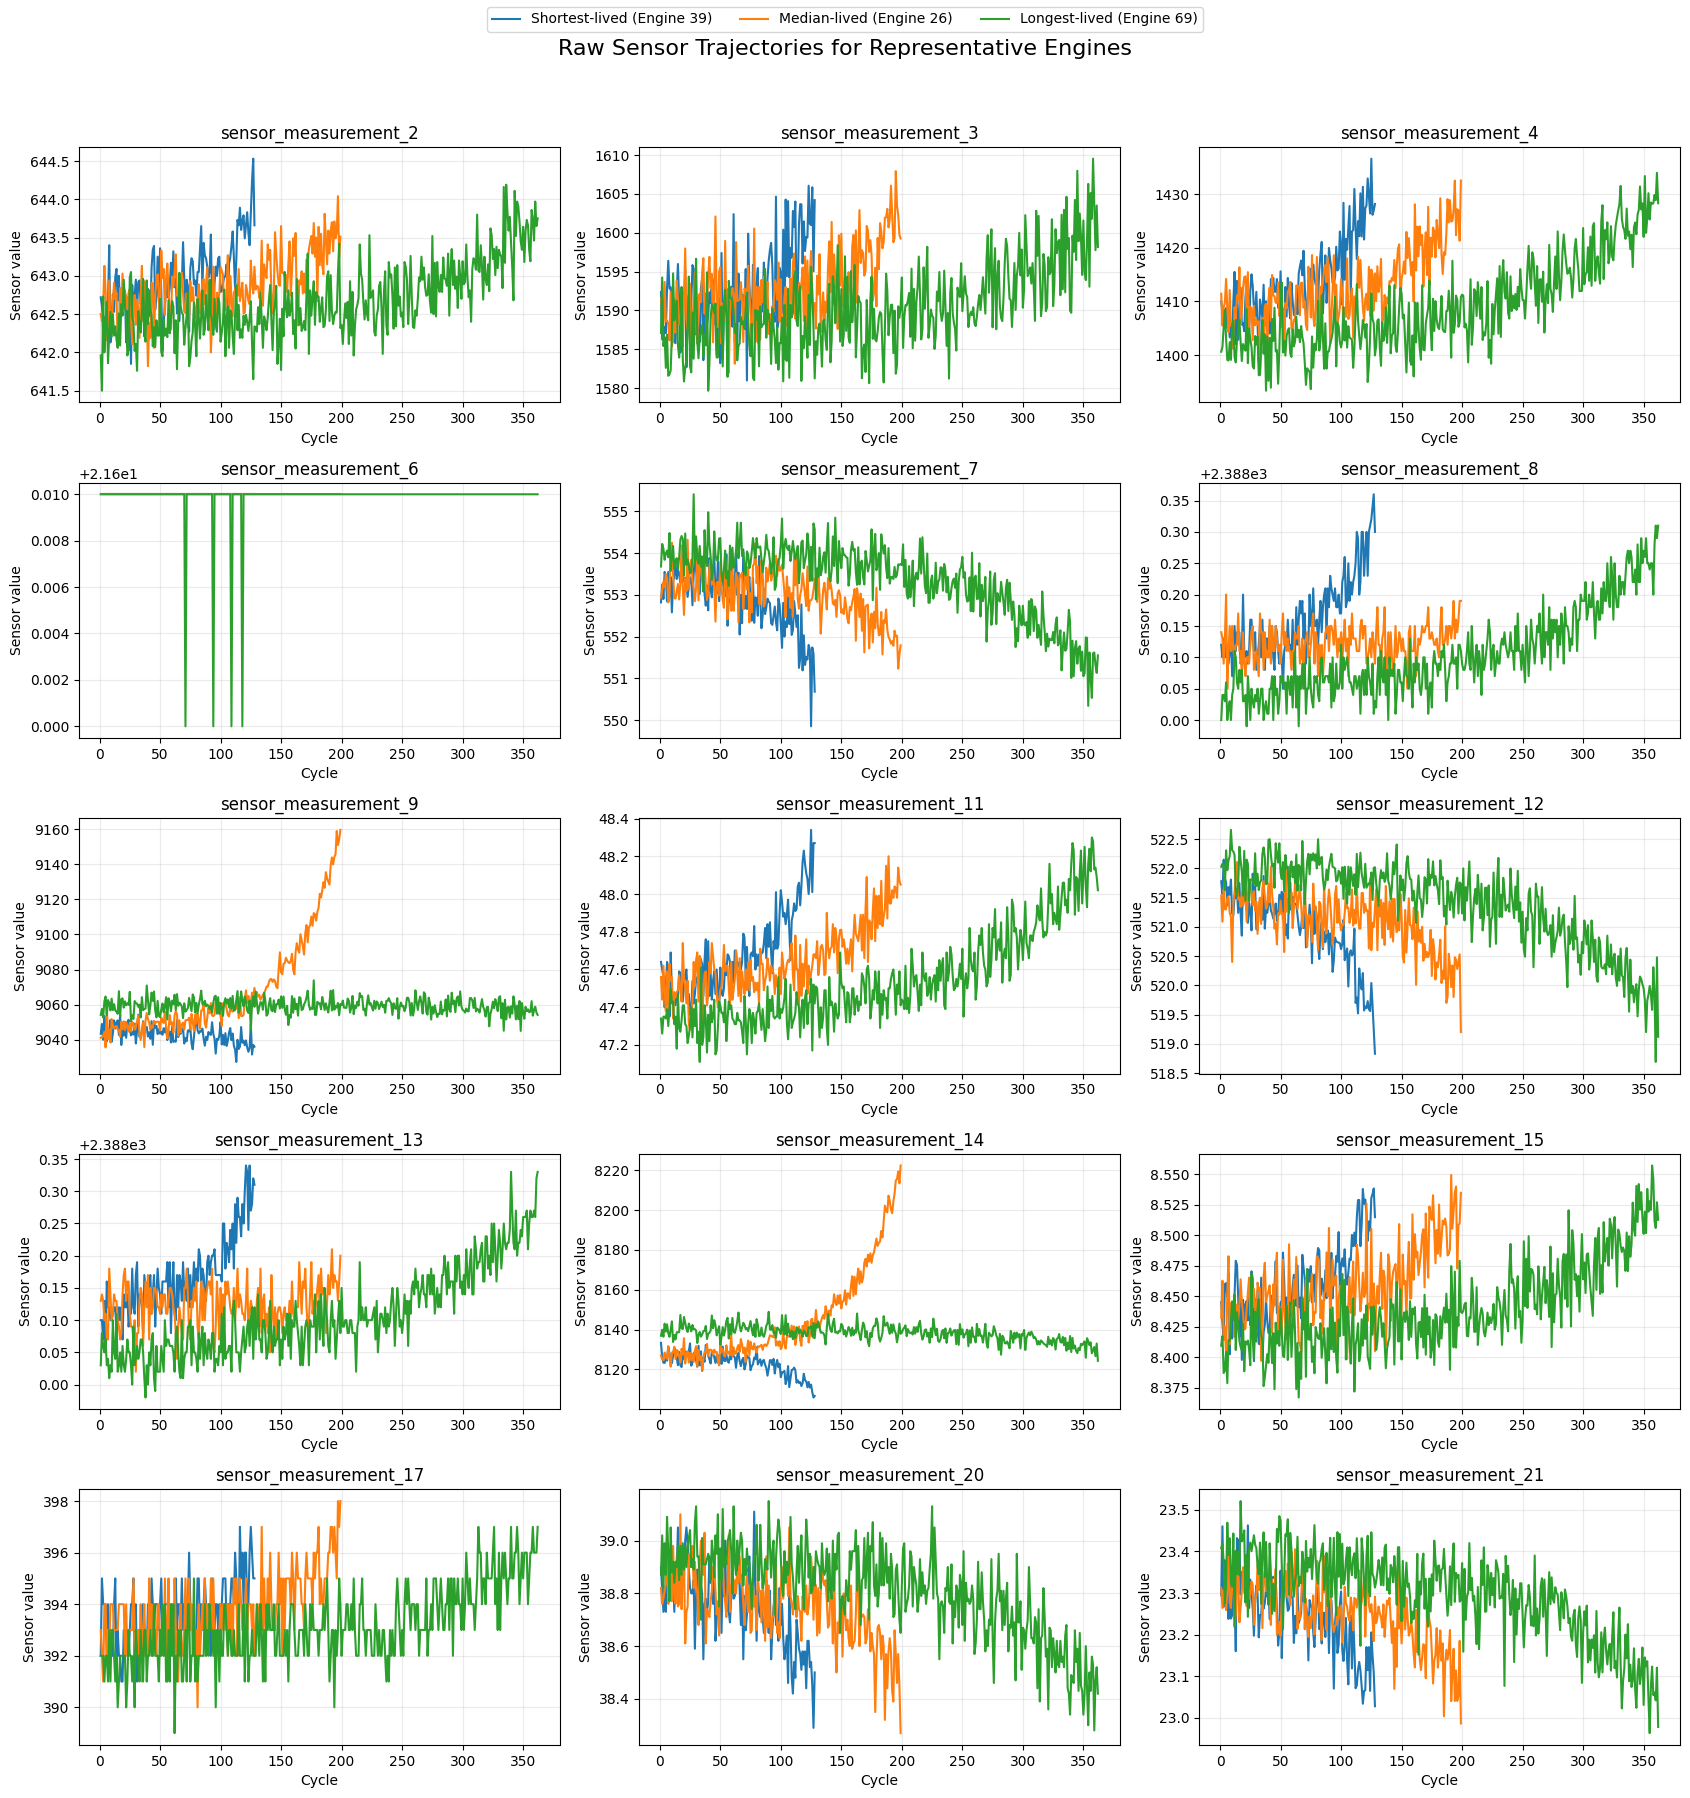

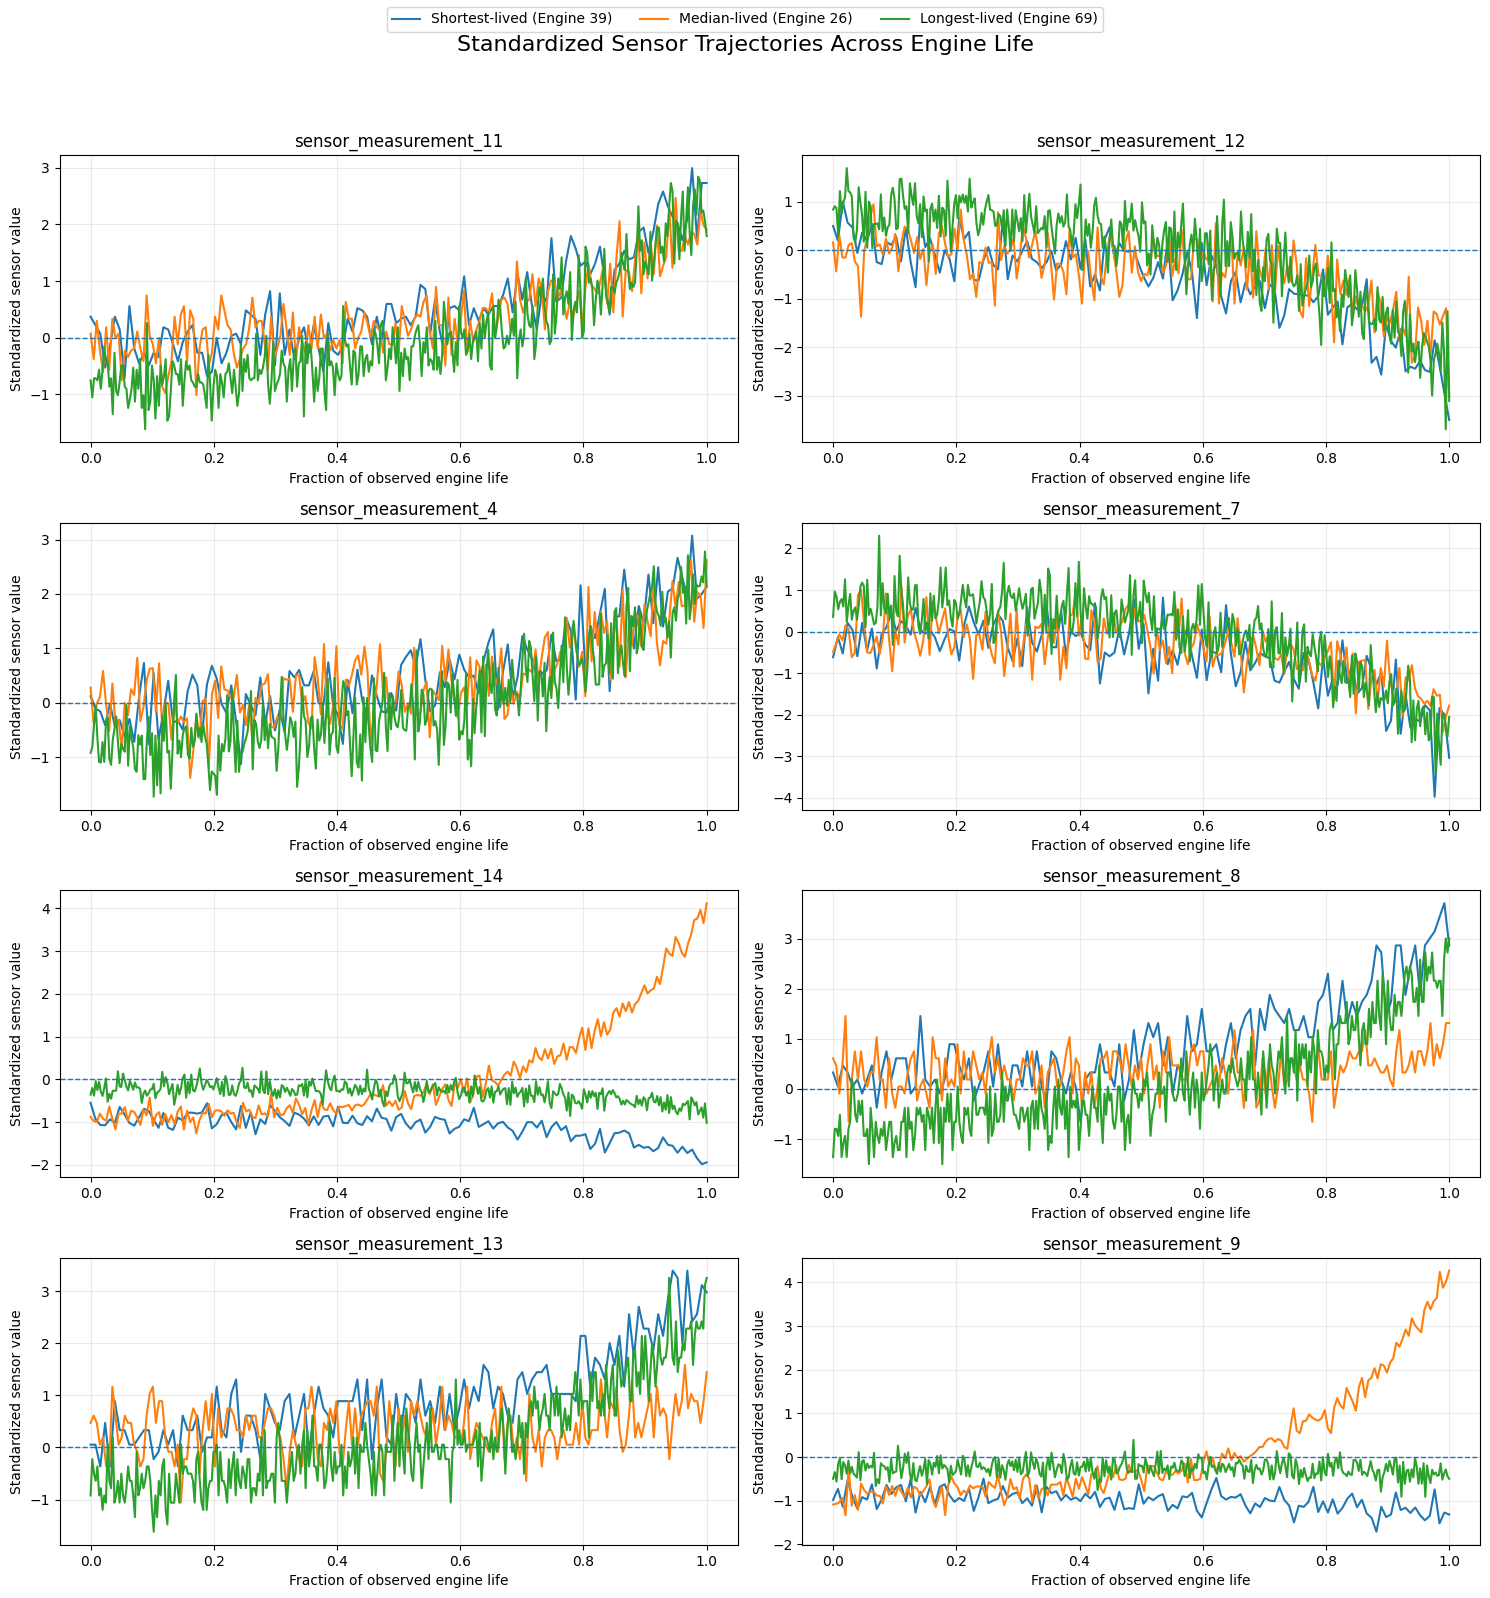

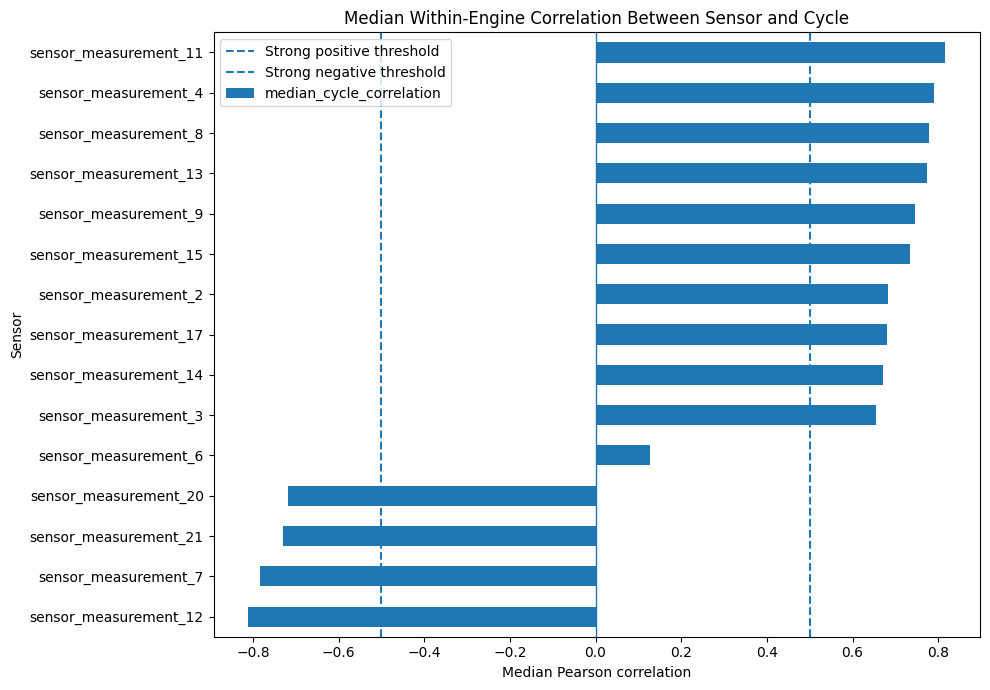

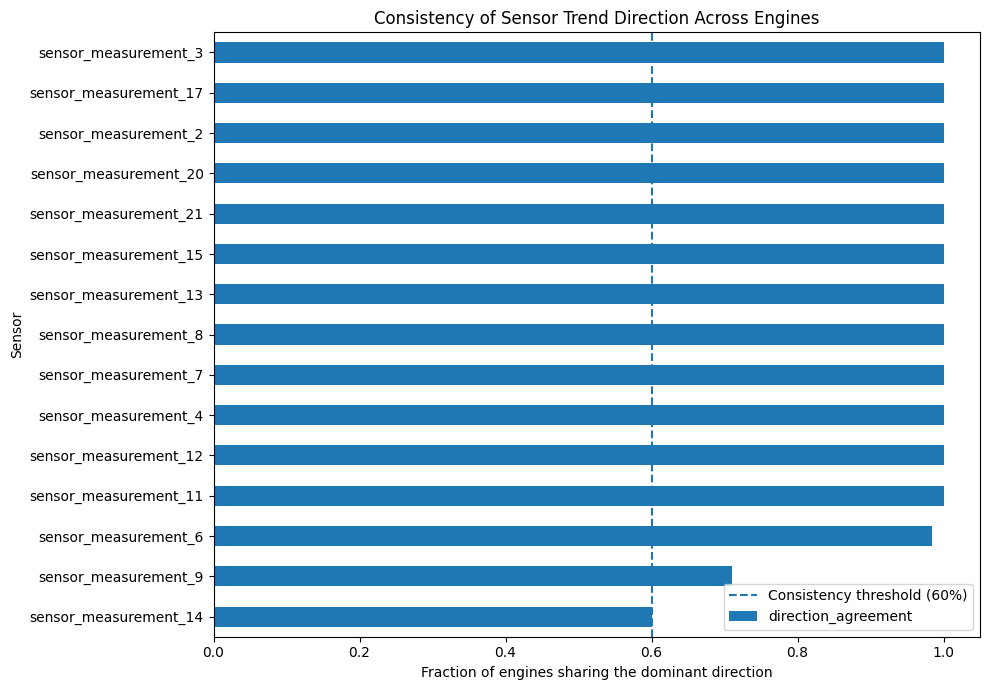


SECTION 10 SUMMARY

Sensor behavior over time was examined within each individual training
engine. Exactly constant sensors were excluded because they cannot
display temporal degradation behavior.

A total of 15 nonconstant sensors were analyzed
across 100 complete run-to-failure engine
sequences.

The representative trajectory plots included:

                      unit_no  sequence_length  initial_rul  final_rul
representative_group                                                  
Shortest-lived             39              128          127          0
Median-lived               26              199          198          0
Longest-lived              69              362          361          0

Sensors classified as generally increasing:

['sensor_measurement_11', 'sensor_measurement_4', 'sensor_measurement_8', 'sensor_measurement_13', 'sensor_measurement_15', 'sensor_measurement_2', 'sensor_measurement_17', 'sensor_measurement_3']

Sensors classified as generally decreasing:

['sensor

In [69]:
# ============================================================
# SECTION 10: SENSOR BEHAVIOR OVER TIME FOR INDIVIDUAL ENGINES
# ============================================================

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ------------------------------------------------------------
# 10-1: Define and validate sensor columns
# ------------------------------------------------------------

if "sensor_cols" not in globals():
    sensor_cols = [
        f"sensor_measurement_{i}"
        for i in range(1, 22)
    ]

required_columns = [
    "unit_no",
    "cycles",
    "rul"
] + sensor_cols

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        "The following required training columns are missing:\n"
        f"{missing_columns}"
    )


# Analyze only sensors that vary somewhere in the training data.
analysis_sensor_cols = [
    col for col in sensor_cols
    if train_df[col].nunique(dropna=False) > 1
]

constant_sensor_cols_section_10 = [
    col for col in sensor_cols
    if train_df[col].nunique(dropna=False) == 1
]

print("=" * 90)
print("SECTION 10 SENSOR SETUP")
print("=" * 90)

print(
    f"Nonconstant sensors analyzed: "
    f"{len(analysis_sensor_cols)}"
)
print(analysis_sensor_cols)

print(
    f"\nConstant sensors excluded from trajectory analysis: "
    f"{len(constant_sensor_cols_section_10)}"
)
print(constant_sensor_cols_section_10)


# ------------------------------------------------------------
# 10-2: Calculate engine sequence lengths
# ------------------------------------------------------------

sequence_lengths_section_10 = (
    train_df
    .groupby("unit_no")
    .size()
    .sort_values()
    .rename("sequence_length")
)

sequence_length_summary_section_10 = (
    sequence_lengths_section_10
    .describe()
    .to_frame()
)

print("\n" + "=" * 90)
print("ENGINE SEQUENCE-LENGTH SUMMARY")
print("=" * 90)

display(sequence_length_summary_section_10)


# ------------------------------------------------------------
# 10-3: Select representative engines
# ------------------------------------------------------------

selection_targets = {
    "Shortest-lived": sequence_lengths_section_10.min(),
    "Median-lived": sequence_lengths_section_10.median(),
    "Longest-lived": sequence_lengths_section_10.max()
}

selected_engine_ids = []
selected_engine_records = []

for label, target_length in selection_targets.items():

    candidate_units = (
        sequence_lengths_section_10
        .sub(target_length)
        .abs()
        .sort_values()
        .index
        .tolist()
    )

    selected_unit = next(
        unit
        for unit in candidate_units
        if unit not in selected_engine_ids
    )

    selected_engine_ids.append(selected_unit)

    selected_engine_records.append({
        "representative_group": label,
        "unit_no": selected_unit,
        "sequence_length":
            int(sequence_lengths_section_10.loc[selected_unit]),
        "initial_rul":
            int(
                train_df.loc[
                    train_df["unit_no"].eq(selected_unit),
                    "rul"
                ].max()
            ),
        "final_rul":
            int(
                train_df.loc[
                    train_df["unit_no"].eq(selected_unit),
                    "rul"
                ].min()
            )
    })

selected_engine_summary = (
    pd.DataFrame(selected_engine_records)
    .set_index("representative_group")
)

selected_engine_label_lookup = {
    row["unit_no"]: label
    for label, row in selected_engine_summary.iterrows()
}

print("\n" + "=" * 90)
print("REPRESENTATIVE ENGINES")
print("=" * 90)

display(selected_engine_summary)


# ------------------------------------------------------------
# 10-4: Calculate sensor trends within every engine
# ------------------------------------------------------------

trend_rows = []

for unit_no, engine_df in train_df.groupby("unit_no"):

    engine_df = (
        engine_df
        .sort_values("cycles")
        .reset_index(drop=True)
    )

    cycles = engine_df["cycles"].astype(float)
    number_of_cycles = len(engine_df)
    cycle_span = cycles.iloc[-1] - cycles.iloc[0]

    # Compare the first and last 20% of each engine's life.
    comparison_window = max(
        5,
        int(np.ceil(number_of_cycles * 0.20))
    )

    comparison_window = min(
        comparison_window,
        max(1, number_of_cycles // 2)
    )

    for sensor in analysis_sensor_cols:

        values = engine_df[sensor].astype(float)

        sensor_std = values.std()
        differences = values.diff().dropna()

        if values.nunique() > 1:
            pearson_cycle_correlation = values.corr(cycles)

            spearman_cycle_correlation = (
                values.rank(method="average")
                .corr(
                    cycles.rank(method="average")
                )
            )

            linear_slope = np.polyfit(
                cycles,
                values,
                deg=1
            )[0]

        else:
            pearson_cycle_correlation = np.nan
            spearman_cycle_correlation = np.nan
            linear_slope = 0.0

        early_mean = values.iloc[
            :comparison_window
        ].mean()

        late_mean = values.iloc[
            -comparison_window:
        ].mean()

        early_to_late_change = (
            late_mean - early_mean
        )

        if sensor_std > 0:
            standardized_early_to_late_change = (
                early_to_late_change / sensor_std
            )

            standardized_linear_change = (
                linear_slope * cycle_span / sensor_std
            )

            standardized_first_to_last_change = (
                (
                    values.iloc[-1]
                    - values.iloc[0]
                )
                / sensor_std
            )

        else:
            standardized_early_to_late_change = 0.0
            standardized_linear_change = 0.0
            standardized_first_to_last_change = 0.0

        trend_rows.append({
            "unit_no": unit_no,
            "sensor": sensor,
            "sequence_length": number_of_cycles,
            "sensor_mean": values.mean(),
            "sensor_std": sensor_std,
            "first_value": values.iloc[0],
            "last_value": values.iloc[-1],
            "early_mean": early_mean,
            "late_mean": late_mean,
            "early_to_late_change":
                early_to_late_change,
            "standardized_early_to_late_change":
                standardized_early_to_late_change,
            "standardized_first_to_last_change":
                standardized_first_to_last_change,
            "linear_slope_per_cycle": linear_slope,
            "standardized_linear_change":
                standardized_linear_change,
            "pearson_cycle_correlation":
                pearson_cycle_correlation,
            "spearman_cycle_correlation":
                spearman_cycle_correlation,
            "positive_step_fraction":
                differences.gt(0).mean(),
            "negative_step_fraction":
                differences.lt(0).mean(),
            "unchanged_step_fraction":
                differences.eq(0).mean()
        })

sensor_engine_trend_report = pd.DataFrame(
    trend_rows
)


# ------------------------------------------------------------
# 10-5: Aggregate trends across all engines
# ------------------------------------------------------------

STRONG_CORRELATION_THRESHOLD = 0.50
CONSISTENCY_THRESHOLD = 0.60

sensor_summary_rows = []

for sensor in analysis_sensor_cols:

    sensor_rows = sensor_engine_trend_report.loc[
        sensor_engine_trend_report["sensor"].eq(sensor)
    ]

    valid_correlations = (
        sensor_rows["pearson_cycle_correlation"]
        .dropna()
    )

    if len(valid_correlations) > 0:

        strong_positive_fraction = (
            valid_correlations
            .ge(STRONG_CORRELATION_THRESHOLD)
            .mean()
        )

        strong_negative_fraction = (
            valid_correlations
            .le(-STRONG_CORRELATION_THRESHOLD)
            .mean()
        )

        positive_direction_fraction = (
            valid_correlations.gt(0).mean()
        )

        negative_direction_fraction = (
            valid_correlations.lt(0).mean()
        )

        direction_agreement = max(
            positive_direction_fraction,
            negative_direction_fraction
        )

    else:
        strong_positive_fraction = np.nan
        strong_negative_fraction = np.nan
        direction_agreement = np.nan

    sensor_summary_rows.append({
        "sensor": sensor,
        "engines_analyzed":
            sensor_rows["unit_no"].nunique(),
        "median_cycle_correlation":
            sensor_rows[
                "pearson_cycle_correlation"
            ].median(),
        "median_absolute_cycle_correlation":
            sensor_rows[
                "pearson_cycle_correlation"
            ].abs().median(),
        "median_spearman_correlation":
            sensor_rows[
                "spearman_cycle_correlation"
            ].median(),
        "strong_positive_fraction":
            strong_positive_fraction,
        "strong_negative_fraction":
            strong_negative_fraction,
        "direction_agreement":
            direction_agreement,
        "median_standardized_early_late_change":
            sensor_rows[
                "standardized_early_to_late_change"
            ].median(),
        "median_absolute_standardized_change":
            sensor_rows[
                "standardized_early_to_late_change"
            ].abs().median(),
        "median_standardized_linear_change":
            sensor_rows[
                "standardized_linear_change"
            ].median(),
        "median_positive_step_fraction":
            sensor_rows[
                "positive_step_fraction"
            ].median(),
        "median_negative_step_fraction":
            sensor_rows[
                "negative_step_fraction"
            ].median()
    })

sensor_trend_summary = (
    pd.DataFrame(sensor_summary_rows)
    .set_index("sensor")
)


# ------------------------------------------------------------
# 10-6: Assign an overall behavior classification
# ------------------------------------------------------------

def classify_sensor_behavior(row):

    if (
        row["strong_positive_fraction"]
        >= CONSISTENCY_THRESHOLD
        and row["median_cycle_correlation"] > 0
    ):
        return "generally_increasing"

    if (
        row["strong_negative_fraction"]
        >= CONSISTENCY_THRESHOLD
        and row["median_cycle_correlation"] < 0
    ):
        return "generally_decreasing"

    if (
        row["median_absolute_cycle_correlation"] < 0.20
        and row[
            "median_absolute_standardized_change"
        ] < 0.50
    ):
        return "weak_or_inconsistent"

    return "mixed_nonlinear_or_noisy"


sensor_trend_summary["behavior_class"] = (
    sensor_trend_summary.apply(
        classify_sensor_behavior,
        axis=1
    )
)

sensor_trend_summary = (
    sensor_trend_summary
    .sort_values(
        by="median_absolute_cycle_correlation",
        ascending=False
    )
)


# ------------------------------------------------------------
# 10-7: Create reusable sensor groups
# ------------------------------------------------------------

generally_increasing_sensor_cols = (
    sensor_trend_summary.index[
        sensor_trend_summary[
            "behavior_class"
        ].eq("generally_increasing")
    ]
    .tolist()
)

generally_decreasing_sensor_cols = (
    sensor_trend_summary.index[
        sensor_trend_summary[
            "behavior_class"
        ].eq("generally_decreasing")
    ]
    .tolist()
)

weak_or_inconsistent_sensor_cols = (
    sensor_trend_summary.index[
        sensor_trend_summary[
            "behavior_class"
        ].eq("weak_or_inconsistent")
    ]
    .tolist()
)

mixed_or_nonlinear_sensor_cols = (
    sensor_trend_summary.index[
        sensor_trend_summary[
            "behavior_class"
        ].eq("mixed_nonlinear_or_noisy")
    ]
    .tolist()
)


print("\n" + "=" * 90)
print("AGGREGATED SENSOR TREND SUMMARY")
print("=" * 90)

display(
    sensor_trend_summary.round(4)
)

print("\nGenerally increasing sensors:")
print(generally_increasing_sensor_cols)

print("\nGenerally decreasing sensors:")
print(generally_decreasing_sensor_cols)

print("\nWeak or inconsistent sensors:")
print(weak_or_inconsistent_sensor_cols)

print("\nMixed, nonlinear, or noisy sensors:")
print(mixed_or_nonlinear_sensor_cols)


# ------------------------------------------------------------
# 10-8: Inspect representative-engine trend metrics
# ------------------------------------------------------------

representative_engine_trends = (
    sensor_engine_trend_report.loc[
        sensor_engine_trend_report[
            "unit_no"
        ].isin(selected_engine_ids)
    ]
    .copy()
)

representative_engine_trends[
    "engine_group"
] = representative_engine_trends[
    "unit_no"
].map(selected_engine_label_lookup)

representative_engine_trends = (
    representative_engine_trends[
        [
            "engine_group",
            "unit_no",
            "sensor",
            "pearson_cycle_correlation",
            "spearman_cycle_correlation",
            "standardized_early_to_late_change",
            "standardized_linear_change",
            "positive_step_fraction",
            "negative_step_fraction"
        ]
    ]
    .sort_values(
        [
            "engine_group",
            "sensor"
        ]
    )
)

print("\n" + "=" * 90)
print("REPRESENTATIVE-ENGINE TREND METRICS")
print("=" * 90)

display(
    representative_engine_trends.round(4)
)


# ------------------------------------------------------------
# 10-9: Plot raw sensor trajectories
# ------------------------------------------------------------

number_of_plot_columns = 3
number_of_plot_rows = math.ceil(
    len(analysis_sensor_cols)
    / number_of_plot_columns
)

fig, axes = plt.subplots(
    number_of_plot_rows,
    number_of_plot_columns,
    figsize=(
        17,
        number_of_plot_rows * 3.6
    )
)

axes = np.asarray(axes).reshape(-1)

for ax, sensor in zip(
    axes,
    analysis_sensor_cols
):

    for unit_no in selected_engine_ids:

        engine_df = (
            train_df.loc[
                train_df["unit_no"].eq(unit_no)
            ]
            .sort_values("cycles")
        )

        label = (
            f"{selected_engine_label_lookup[unit_no]} "
            f"(Engine {unit_no})"
        )

        ax.plot(
            engine_df["cycles"],
            engine_df[sensor],
            label=label
        )

    ax.set_title(sensor)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Sensor value")
    ax.grid(alpha=0.25)

for unused_ax in axes[
    len(analysis_sensor_cols):
]:
    unused_ax.remove()

legend_handles, legend_labels = (
    axes[0].get_legend_handles_labels()
)

fig.legend(
    legend_handles,
    legend_labels,
    loc="upper center",
    ncol=len(selected_engine_ids)
)

fig.suptitle(
    "Raw Sensor Trajectories for Representative Engines",
    fontsize=16
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()


# ------------------------------------------------------------
# 10-10: Plot standardized trajectories against life fraction
# ------------------------------------------------------------

# Select the sensors with the strongest typical relationships
# with cycle number.
TOP_SENSOR_COUNT = min(
    8,
    len(analysis_sensor_cols)
)

top_trending_sensor_cols = (
    sensor_trend_summary
    .head(TOP_SENSOR_COUNT)
    .index
    .tolist()
)

training_sensor_means = (
    train_df[analysis_sensor_cols]
    .mean()
)

training_sensor_stds = (
    train_df[analysis_sensor_cols]
    .std()
    .replace(0, np.nan)
)

standardized_plot_columns = 2
standardized_plot_rows = math.ceil(
    len(top_trending_sensor_cols)
    / standardized_plot_columns
)

fig, axes = plt.subplots(
    standardized_plot_rows,
    standardized_plot_columns,
    figsize=(
        15,
        standardized_plot_rows * 4
    )
)

axes = np.asarray(axes).reshape(-1)

for ax, sensor in zip(
    axes,
    top_trending_sensor_cols
):

    for unit_no in selected_engine_ids:

        engine_df = (
            train_df.loc[
                train_df["unit_no"].eq(unit_no)
            ]
            .sort_values("cycles")
            .copy()
        )

        cycle_min = engine_df["cycles"].min()
        cycle_max = engine_df["cycles"].max()

        if cycle_max > cycle_min:
            life_fraction = (
                engine_df["cycles"] - cycle_min
            ) / (
                cycle_max - cycle_min
            )
        else:
            life_fraction = pd.Series(
                0,
                index=engine_df.index
            )

        standardized_values = (
            engine_df[sensor]
            - training_sensor_means[sensor]
        ) / training_sensor_stds[sensor]

        label = (
            f"{selected_engine_label_lookup[unit_no]} "
            f"(Engine {unit_no})"
        )

        ax.plot(
            life_fraction,
            standardized_values,
            label=label
        )

    ax.set_title(sensor)
    ax.set_xlabel("Fraction of observed engine life")
    ax.set_ylabel("Standardized sensor value")
    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )
    ax.grid(alpha=0.25)

for unused_ax in axes[
    len(top_trending_sensor_cols):
]:
    unused_ax.remove()

legend_handles, legend_labels = (
    axes[0].get_legend_handles_labels()
)

fig.legend(
    legend_handles,
    legend_labels,
    loc="upper center",
    ncol=len(selected_engine_ids)
)

fig.suptitle(
    "Standardized Sensor Trajectories Across Engine Life",
    fontsize=16
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()


# ------------------------------------------------------------
# 10-11: Plot median sensor correlation with cycle
# ------------------------------------------------------------

correlation_plot_data = (
    sensor_trend_summary[
        "median_cycle_correlation"
    ]
    .sort_values()
)

plt.figure(
    figsize=(
        10,
        max(7, len(correlation_plot_data) * 0.45)
    )
)

correlation_plot_data.plot.barh()

plt.axvline(
    0,
    linewidth=1
)

plt.axvline(
    STRONG_CORRELATION_THRESHOLD,
    linestyle="--",
    label="Strong positive threshold"
)

plt.axvline(
    -STRONG_CORRELATION_THRESHOLD,
    linestyle="--",
    label="Strong negative threshold"
)

plt.title(
    "Median Within-Engine Correlation Between Sensor and Cycle"
)
plt.xlabel("Median Pearson correlation")
plt.ylabel("Sensor")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10-12: Plot direction consistency across engines
# ------------------------------------------------------------

direction_consistency_plot = (
    sensor_trend_summary[
        "direction_agreement"
    ]
    .sort_values()
)

plt.figure(
    figsize=(
        10,
        max(7, len(direction_consistency_plot) * 0.45)
    )
)

direction_consistency_plot.plot.barh()

plt.axvline(
    CONSISTENCY_THRESHOLD,
    linestyle="--",
    label=(
        f"Consistency threshold "
        f"({CONSISTENCY_THRESHOLD:.0%})"
    )
)

plt.title(
    "Consistency of Sensor Trend Direction Across Engines"
)
plt.xlabel(
    "Fraction of engines sharing the dominant direction"
)
plt.ylabel("Sensor")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10-13: Automated validation
# ------------------------------------------------------------

expected_trend_rows = (
    train_df["unit_no"].nunique()
    * len(analysis_sensor_cols)
)

assert len(sensor_cols) == 21

assert set(analysis_sensor_cols).isdisjoint(
    constant_sensor_cols_section_10
)

assert len(sensor_engine_trend_report) == (
    expected_trend_rows
)

assert (
    sensor_engine_trend_report[
        "unit_no"
    ].nunique()
    == train_df["unit_no"].nunique()
)

assert (
    sensor_trend_summary.index.nunique()
    == len(analysis_sensor_cols)
)

assert set(selected_engine_ids).issubset(
    set(train_df["unit_no"].unique())
)

valid_correlations = (
    sensor_engine_trend_report[
        "pearson_cycle_correlation"
    ]
    .dropna()
)

assert valid_correlations.between(
    -1,
    1
).all()


# ------------------------------------------------------------
# 10-14: Written Section 10 summary
# ------------------------------------------------------------

section_10_summary = f"""
SECTION 10 SUMMARY

Sensor behavior over time was examined within each individual training
engine. Exactly constant sensors were excluded because they cannot
display temporal degradation behavior.

A total of {len(analysis_sensor_cols)} nonconstant sensors were analyzed
across {train_df["unit_no"].nunique()} complete run-to-failure engine
sequences.

The representative trajectory plots included:

{selected_engine_summary.to_string()}

Sensors classified as generally increasing:

{generally_increasing_sensor_cols}

Sensors classified as generally decreasing:

{generally_decreasing_sensor_cols}

Sensors with weak or inconsistent temporal behavior:

{weak_or_inconsistent_sensor_cols}

Sensors showing mixed, nonlinear, or noisy behavior:

{mixed_or_nonlinear_sensor_cols}

The classifications use within-engine correlations, early-versus-late
changes, linear slopes, and consistency across engines. They are EDA
descriptions rather than final feature-selection decisions.

A weak linear correlation does not prove that a sensor lacks predictive
value. A sensor may remain stable during early life and change sharply
near failure, behave nonlinearly, interact with other measurements, or
become useful after rolling-window and change-based feature engineering.

No sensors were removed, smoothed, transformed, or otherwise modified
during this section.
"""

print("\n" + "=" * 90)
print(section_10_summary.strip())
print("=" * 90)

print("\nSection 10 completed successfully.")

### Section 11: Operating Conditions and Regimes

OPERATING-SETTING DISTRIBUTION REPORT


,train_count,train_exact_unique_count,train_mean,train_std,train_minimum,train_q1,train_median,train_q3,train_maximum,train_range,...,test_maximum,test_range,test_relative_range,test_unique_after_rounding_6,test_unique_after_rounding_4,test_unique_after_rounding_3,test_unique_after_rounding_2,test_below_train_min_fraction,test_above_train_max_fraction,test_outside_train_range_fraction
setting,,,,,,,,,,,,,,,,,,,,,
op_setting_1,20631,158,-0.000009,0.002187,-0.0087,-0.0015,0.0,0.0015,0.0087,0.0174,...,0.0078,0.0160,1.951220,150,150,17,3,0.0,0.000000,0.000000
op_setting_2,20631,13,0.000002,0.000293,-0.0006,-0.0002,0.0,0.0003,0.0006,0.0012,...,0.0007,0.0013,1.857143,14,14,3,1,0.0,0.000382,0.000382
op_setting_3,20631,1,100.000000,0.000000,100.0000,100.0000,100.0,100.0000,100.0000,0.0000,...,100.0000,0.0000,0.000000,1,1,1,1,0.0,0.000000,0.000000



OPERATING-SETTING COMBINATIONS


,training,test
Exact setting combinations,1423,1344
Setting combinations after rounding to 2 decimals,3,3



Rounded training combinations (2 decimal places):


...

,observed_cycles,unique_regimes,first_regime,last_regime,switches_regime
unit_no,,,,,
1,192,2,1,1,True
2,287,3,1,1,True
3,179,3,1,1,True
4,189,2,1,1,True
5,269,3,1,1,True
6,188,2,1,1,True
7,259,3,1,1,True
8,150,3,1,1,True
9,201,2,1,1,True



Engines that switch operating regime: 99

OPERATING-SETTING CORRELATIONS
Training correlations:


,op_setting_1,op_setting_2,op_setting_3
op_setting_1,1.0000,0.0117,NaN
op_setting_2,0.0117,1.0000,NaN
op_setting_3,NaN,NaN,NaN


Test correlations:


,op_setting_1,op_setting_2,op_setting_3
op_setting_1,1.0000,-0.0077,NaN
op_setting_2,-0.0077,1.0000,NaN
op_setting_3,NaN,NaN,NaN


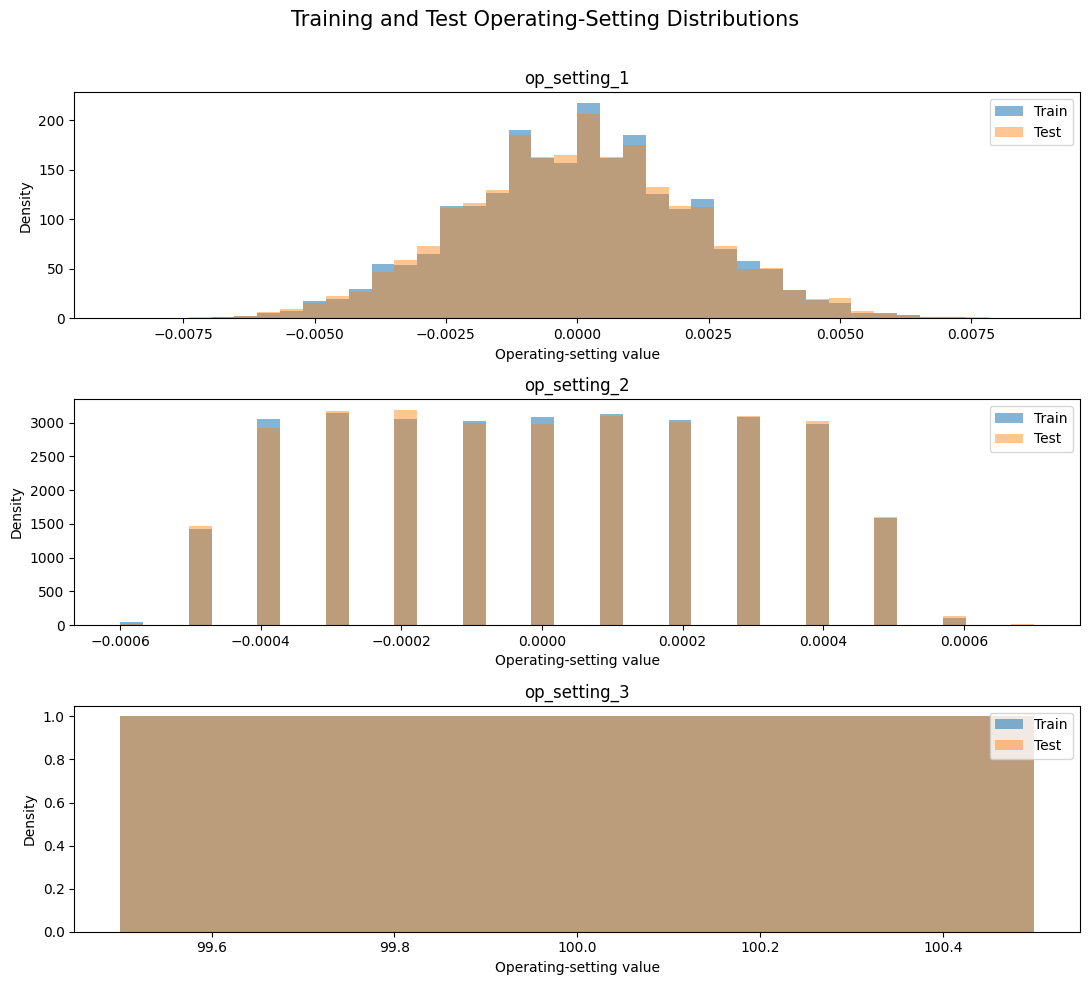

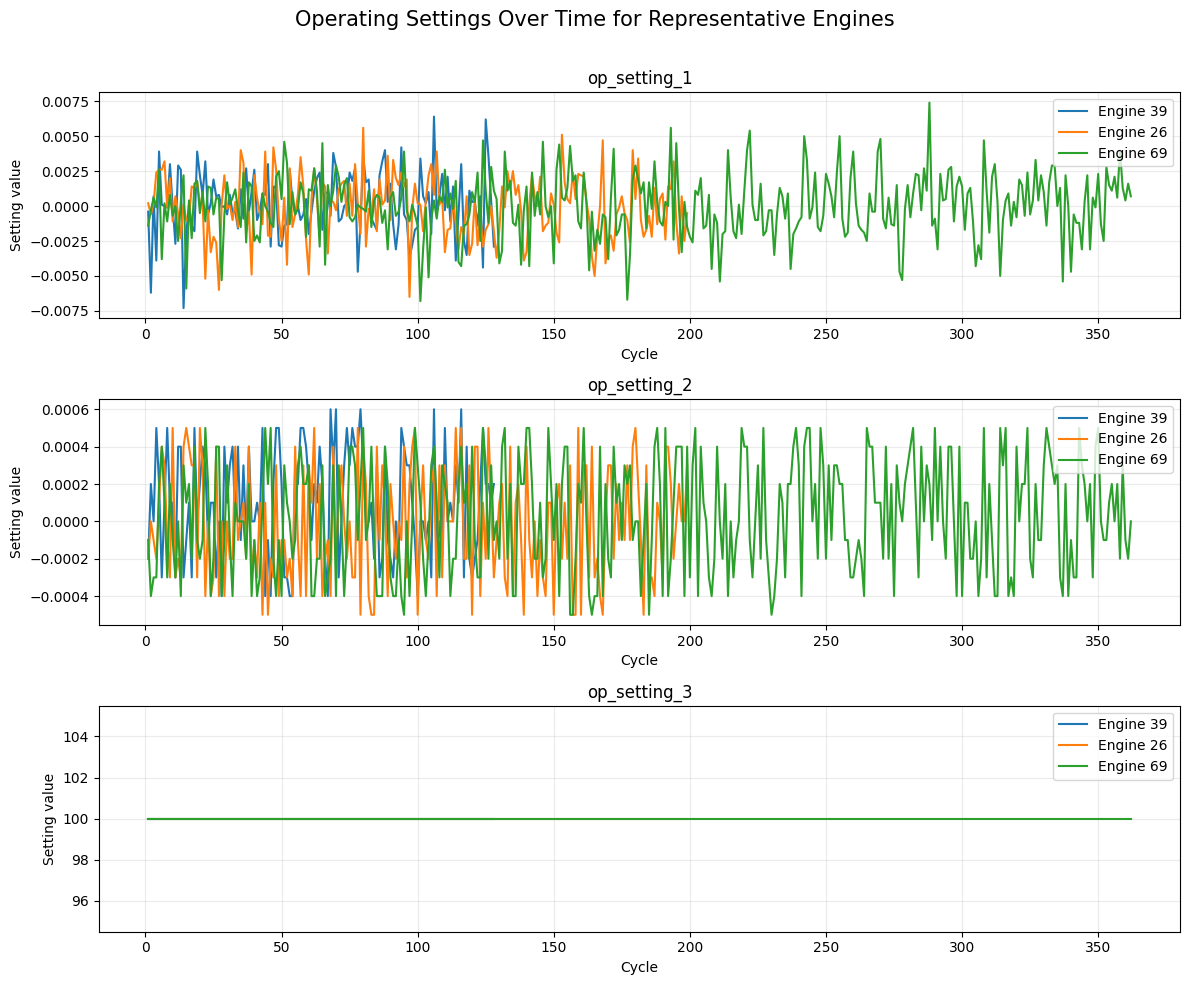

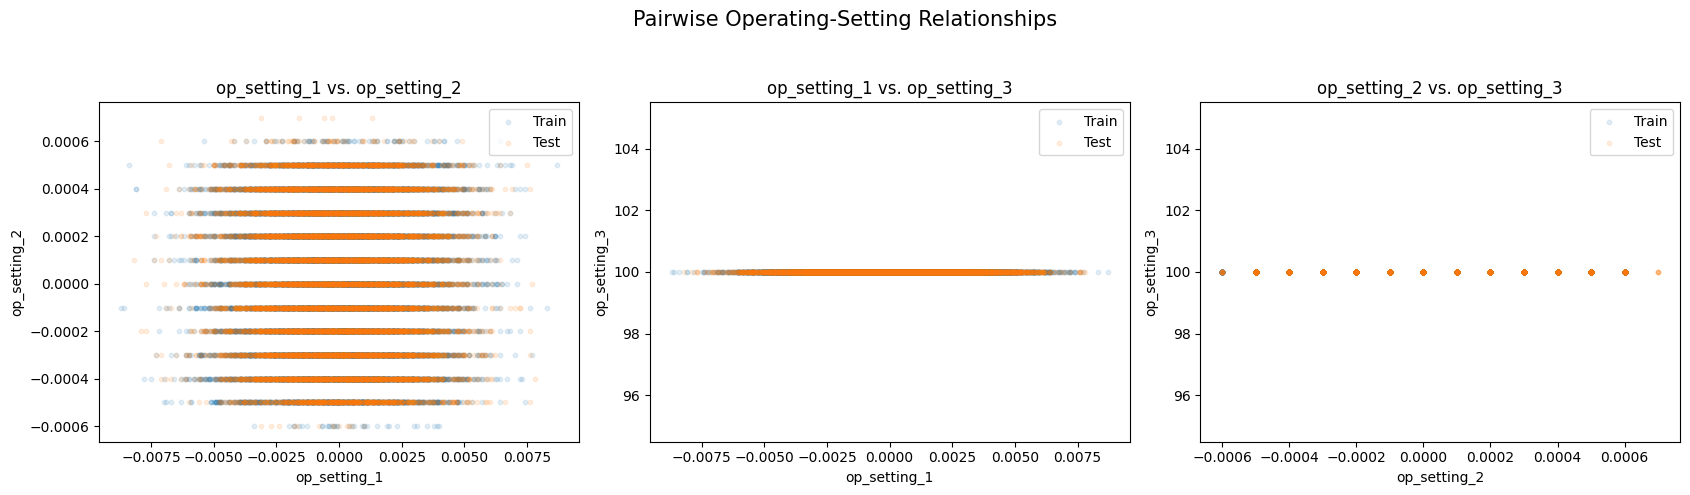


SECTION 11 SUMMARY

The three operating-setting variables were examined in the training
and test datasets using exact unique-value counts, rounded unique-value
counts, descriptive statistics, within-engine variation, between-engine
variation, temporal plots, and pairwise relationships.

Training practical regime count:
3

Test practical regime count:
3

After rounding the operating settings to 2 decimal places, more than one setting combination remains. These combinations should be investigated before deciding whether they represent genuine operating regimes.

The number of training engines observed to switch between practical
operating regimes was:

99

All test regimes were represented in the training data:

True

Because FD001 supports a single practical operating condition, a
clustering algorithm was not forced to divide the data into artificial
regimes. Regime-specific normalization is therefore not required for
the initial FD001 baseline.

The operating-setting columns may still

In [70]:
# ============================================================
# SECTION 11: OPERATING CONDITIONS AND REGIMES
# ============================================================

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ------------------------------------------------------------
# 11-1: Define and validate operating-setting columns
# ------------------------------------------------------------

setting_cols = [
    "op_setting_1",
    "op_setting_2",
    "op_setting_3"
]

required_columns = [
    "unit_no",
    "cycles"
] + setting_cols

missing_train_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

missing_test_columns = [
    col for col in required_columns
    if col not in test_df.columns
]

if missing_train_columns or missing_test_columns:
    raise ValueError(
        "Required operating-condition columns are missing.\n"
        f"Missing from training: {missing_train_columns}\n"
        f"Missing from test: {missing_test_columns}"
    )

non_numeric_train_settings = [
    col for col in setting_cols
    if not pd.api.types.is_numeric_dtype(train_df[col])
]

non_numeric_test_settings = [
    col for col in setting_cols
    if not pd.api.types.is_numeric_dtype(test_df[col])
]

if non_numeric_train_settings or non_numeric_test_settings:
    raise TypeError(
        "All operating-setting columns must be numeric.\n"
        f"Non-numeric training settings: {non_numeric_train_settings}\n"
        f"Non-numeric test settings: {non_numeric_test_settings}"
    )


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

# FD001 is expected to contain one operating condition.
#
# Exact floating-point values may still differ slightly because the
# operating settings contain small numerical fluctuations. Rounding
# is used only to identify practically distinct operating regimes.
REGIME_ROUND_DECIMALS = 2


# ------------------------------------------------------------
# 11-2: Summarize each operating-setting distribution
# ------------------------------------------------------------

def create_setting_report(df, columns):
    rows = []

    for col in columns:
        series = df[col]

        minimum = series.min()
        maximum = series.max()
        value_range = maximum - minimum
        mean = series.mean()

        numerical_scale = max(
            abs(mean),
            abs(minimum),
            abs(maximum),
            np.finfo(float).eps
        )

        rows.append({
            "setting": col,
            "count": series.count(),
            "exact_unique_count":
                series.nunique(dropna=False),
            "mean": mean,
            "std": series.std(),
            "minimum": minimum,
            "q1": series.quantile(0.25),
            "median": series.median(),
            "q3": series.quantile(0.75),
            "maximum": maximum,
            "range": value_range,
            "relative_range":
                value_range / numerical_scale,
            "unique_after_rounding_6":
                series.round(6).nunique(),
            "unique_after_rounding_4":
                series.round(4).nunique(),
            "unique_after_rounding_3":
                series.round(3).nunique(),
            "unique_after_rounding_2":
                series.round(2).nunique()
        })

    return (
        pd.DataFrame(rows)
        .set_index("setting")
    )


train_setting_report = create_setting_report(
    train_df,
    setting_cols
)

test_setting_report = create_setting_report(
    test_df,
    setting_cols
)

operating_setting_comparison = (
    train_setting_report
    .add_prefix("train_")
    .join(
        test_setting_report.add_prefix("test_")
    )
)


# ------------------------------------------------------------
# 11-3: Compare test values with the training ranges
# ------------------------------------------------------------

for col in setting_cols:
    train_minimum = train_df[col].min()
    train_maximum = train_df[col].max()

    operating_setting_comparison.loc[
        col,
        "test_below_train_min_fraction"
    ] = test_df[col].lt(train_minimum).mean()

    operating_setting_comparison.loc[
        col,
        "test_above_train_max_fraction"
    ] = test_df[col].gt(train_maximum).mean()

operating_setting_comparison[
    "test_outside_train_range_fraction"
] = (
    operating_setting_comparison[
        "test_below_train_min_fraction"
    ]
    + operating_setting_comparison[
        "test_above_train_max_fraction"
    ]
)


print("=" * 90)
print("OPERATING-SETTING DISTRIBUTION REPORT")
print("=" * 90)

display(
    operating_setting_comparison.round(8)
)


# ------------------------------------------------------------
# 11-4: Examine exact and rounded setting combinations
# ------------------------------------------------------------

train_exact_setting_combinations = (
    train_df[setting_cols]
    .drop_duplicates()
    .sort_values(setting_cols)
    .reset_index(drop=True)
)

test_exact_setting_combinations = (
    test_df[setting_cols]
    .drop_duplicates()
    .sort_values(setting_cols)
    .reset_index(drop=True)
)

train_rounded_settings = (
    train_df[setting_cols]
    .round(REGIME_ROUND_DECIMALS)
)

test_rounded_settings = (
    test_df[setting_cols]
    .round(REGIME_ROUND_DECIMALS)
)

train_rounded_setting_combinations = (
    train_rounded_settings
    .drop_duplicates()
    .sort_values(setting_cols)
    .reset_index(drop=True)
)

test_rounded_setting_combinations = (
    test_rounded_settings
    .drop_duplicates()
    .sort_values(setting_cols)
    .reset_index(drop=True)
)


setting_combination_summary = pd.DataFrame({
    "training": [
        len(train_exact_setting_combinations),
        len(train_rounded_setting_combinations)
    ],
    "test": [
        len(test_exact_setting_combinations),
        len(test_rounded_setting_combinations)
    ]
}, index=[
    "Exact setting combinations",
    (
        "Setting combinations after rounding "
        f"to {REGIME_ROUND_DECIMALS} decimals"
    )
])

print("\n" + "=" * 90)
print("OPERATING-SETTING COMBINATIONS")
print("=" * 90)

display(setting_combination_summary)

print(
    f"\nRounded training combinations "
    f"({REGIME_ROUND_DECIMALS} decimal places):"
)
display(train_rounded_setting_combinations)

print(
    f"Rounded test combinations "
    f"({REGIME_ROUND_DECIMALS} decimal places):"
)
display(test_rounded_setting_combinations)


# ------------------------------------------------------------
# 11-5: Assign descriptive operating-regime labels
# ------------------------------------------------------------

# Combine train and test before factorization so the same rounded
# setting combination always receives the same regime number.
combined_rounded_settings = pd.concat(
    [
        train_rounded_settings,
        test_rounded_settings
    ],
    axis=0,
    ignore_index=True
)

combined_regime_keys = pd.MultiIndex.from_frame(
    combined_rounded_settings
)

combined_regime_codes, unique_regime_keys = pd.factorize(
    combined_regime_keys,
    sort=True
)

train_regime_labels = pd.Series(
    combined_regime_codes[:len(train_df)],
    index=train_df.index,
    name="operating_regime"
)

test_regime_labels = pd.Series(
    combined_regime_codes[len(train_df):],
    index=test_df.index,
    name="operating_regime"
)

regime_definition_table = (
    unique_regime_keys
    .to_frame(index=False)
)

regime_definition_table.insert(
    0,
    "operating_regime",
    range(len(regime_definition_table))
)

train_regime_counts = (
    train_regime_labels
    .value_counts()
    .sort_index()
    .rename("training_rows")
)

test_regime_counts = (
    test_regime_labels
    .value_counts()
    .sort_index()
    .rename("test_rows")
)

regime_count_table = pd.concat(
    [
        train_regime_counts,
        test_regime_counts
    ],
    axis=1
).fillna(0)

regime_count_table["training_fraction"] = (
    regime_count_table["training_rows"]
    / len(train_df)
)

regime_count_table["test_fraction"] = (
    regime_count_table["test_rows"]
    / len(test_df)
)


print("\n" + "=" * 90)
print("DESCRIPTIVE OPERATING REGIMES")
print("=" * 90)

display(regime_definition_table)
display(regime_count_table)


# ------------------------------------------------------------
# 11-6: Determine whether the data supports multiple regimes
# ------------------------------------------------------------

number_of_train_regimes = (
    train_regime_labels.nunique()
)

number_of_test_regimes = (
    test_regime_labels.nunique()
)

train_regime_set = set(
    train_regime_labels.unique()
)

test_regime_set = set(
    test_regime_labels.unique()
)

test_regimes_seen_in_training = (
    test_regime_set.issubset(train_regime_set)
)

single_train_regime_supported = (
    number_of_train_regimes == 1
)

single_test_regime_supported = (
    number_of_test_regimes == 1
)

single_operating_condition_supported = (
    single_train_regime_supported
    and single_test_regime_supported
)


regime_conclusion = pd.Series({
    "rounding_decimals":
        REGIME_ROUND_DECIMALS,
    "number_of_training_regimes":
        number_of_train_regimes,
    "number_of_test_regimes":
        number_of_test_regimes,
    "all_test_regimes_seen_in_training":
        test_regimes_seen_in_training,
    "single_operating_condition_supported":
        single_operating_condition_supported
})

print("\n" + "=" * 90)
print("REGIME CONCLUSION")
print("=" * 90)

display(regime_conclusion.to_frame("result"))


# ------------------------------------------------------------
# 11-7: Examine variation within and between engines
# ------------------------------------------------------------

engine_setting_rows = []

for unit_no, engine_df in train_df.groupby("unit_no"):
    for setting in setting_cols:
        values = engine_df[setting]

        engine_setting_rows.append({
            "unit_no": unit_no,
            "setting": setting,
            "sequence_length": len(engine_df),
            "engine_mean": values.mean(),
            "engine_std": values.std(),
            "engine_minimum": values.min(),
            "engine_maximum": values.max(),
            "engine_range":
                values.max() - values.min()
        })

engine_setting_report = pd.DataFrame(
    engine_setting_rows
)

engine_setting_summary_rows = []

for setting in setting_cols:
    setting_rows = engine_setting_report.loc[
        engine_setting_report["setting"].eq(setting)
    ]

    engine_setting_summary_rows.append({
        "setting": setting,
        "median_within_engine_std":
            setting_rows["engine_std"].median(),
        "maximum_within_engine_std":
            setting_rows["engine_std"].max(),
        "median_within_engine_range":
            setting_rows["engine_range"].median(),
        "maximum_within_engine_range":
            setting_rows["engine_range"].max(),
        "minimum_engine_mean":
            setting_rows["engine_mean"].min(),
        "maximum_engine_mean":
            setting_rows["engine_mean"].max(),
        "range_of_engine_means":
            (
                setting_rows["engine_mean"].max()
                - setting_rows["engine_mean"].min()
            )
    })

engine_setting_summary = (
    pd.DataFrame(engine_setting_summary_rows)
    .set_index("setting")
)

print("\n" + "=" * 90)
print("WITHIN-ENGINE AND BETWEEN-ENGINE SETTING VARIATION")
print("=" * 90)

display(engine_setting_summary.round(8))


# ------------------------------------------------------------
# 11-8: Check whether engines switch regimes
# ------------------------------------------------------------

train_regime_frame = train_df[
    ["unit_no", "cycles"]
].copy()

train_regime_frame[
    "operating_regime"
] = train_regime_labels

engine_regime_summary = (
    train_regime_frame
    .groupby("unit_no")
    .agg(
        observed_cycles=("cycles", "size"),
        unique_regimes=("operating_regime", "nunique"),
        first_regime=("operating_regime", "first"),
        last_regime=("operating_regime", "last")
    )
)

engine_regime_summary[
    "switches_regime"
] = (
    engine_regime_summary["unique_regimes"]
    .gt(1)
)

number_of_engines_switching_regime = int(
    engine_regime_summary[
        "switches_regime"
    ].sum()
)

print("\n" + "=" * 90)
print("REGIME CONSISTENCY WITHIN ENGINES")
print("=" * 90)

display(engine_regime_summary.head(10))

print(
    "\nEngines that switch operating regime:",
    number_of_engines_switching_regime
)


# ------------------------------------------------------------
# 11-9: Operating-setting correlations
# ------------------------------------------------------------

train_setting_correlations = (
    train_df[setting_cols]
    .corr()
)

test_setting_correlations = (
    test_df[setting_cols]
    .corr()
)

print("\n" + "=" * 90)
print("OPERATING-SETTING CORRELATIONS")
print("=" * 90)

print("Training correlations:")
display(train_setting_correlations.round(4))

print("Test correlations:")
display(test_setting_correlations.round(4))


# ------------------------------------------------------------
# 11-10: Plot train/test operating-setting distributions
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(setting_cols),
    1,
    figsize=(11, 10)
)

axes = np.asarray(axes).reshape(-1)

for ax, setting in zip(
    axes,
    setting_cols
):
    combined_values = pd.concat(
        [
            train_df[setting],
            test_df[setting]
        ],
        ignore_index=True
    )

    if combined_values.nunique() <= 1:
        bins = 1
    else:
        bin_edges = np.histogram_bin_edges(
            combined_values,
            bins="auto"
        )

        if len(bin_edges) > 41:
            bin_edges = np.linspace(
                combined_values.min(),
                combined_values.max(),
                41
            )

        bins = bin_edges

    ax.hist(
        train_df[setting],
        bins=bins,
        density=True,
        alpha=0.55,
        label="Train"
    )

    ax.hist(
        test_df[setting],
        bins=bins,
        density=True,
        alpha=0.45,
        label="Test"
    )

    ax.set_title(setting)
    ax.set_xlabel("Operating-setting value")
    ax.set_ylabel("Density")
    ax.legend()

fig.suptitle(
    "Training and Test Operating-Setting Distributions",
    fontsize=15
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.show()


# ------------------------------------------------------------
# 11-11: Plot operating settings over time
# ------------------------------------------------------------

# Reuse representative engines from Section 10 when available.
if (
    "selected_engine_ids" in globals()
    and len(selected_engine_ids) > 0
):
    operating_condition_engine_ids = (
        selected_engine_ids
    )
else:
    sequence_lengths_section_11 = (
        train_df
        .groupby("unit_no")
        .size()
        .sort_values()
    )

    target_lengths = [
        sequence_lengths_section_11.min(),
        sequence_lengths_section_11.median(),
        sequence_lengths_section_11.max()
    ]

    operating_condition_engine_ids = []

    for target_length in target_lengths:
        candidates = (
            sequence_lengths_section_11
            .sub(target_length)
            .abs()
            .sort_values()
            .index
            .tolist()
        )

        selected_unit = next(
            unit
            for unit in candidates
            if unit not in operating_condition_engine_ids
        )

        operating_condition_engine_ids.append(
            selected_unit
        )


fig, axes = plt.subplots(
    len(setting_cols),
    1,
    figsize=(12, 10)
)

axes = np.asarray(axes).reshape(-1)

for ax, setting in zip(
    axes,
    setting_cols
):
    for unit_no in operating_condition_engine_ids:
        engine_df = (
            train_df.loc[
                train_df["unit_no"].eq(unit_no)
            ]
            .sort_values("cycles")
        )

        ax.plot(
            engine_df["cycles"],
            engine_df[setting],
            label=f"Engine {unit_no}"
        )

    ax.set_title(setting)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Setting value")
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle(
    "Operating Settings Over Time for Representative Engines",
    fontsize=15
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.show()


# ------------------------------------------------------------
# 11-12: Plot pairwise operating-setting relationships
# ------------------------------------------------------------

setting_pairs = [
    (setting_cols[0], setting_cols[1]),
    (setting_cols[0], setting_cols[2]),
    (setting_cols[1], setting_cols[2])
]

fig, axes = plt.subplots(
    1,
    len(setting_pairs),
    figsize=(17, 5)
)

axes = np.asarray(axes).reshape(-1)

for ax, (x_setting, y_setting) in zip(
    axes,
    setting_pairs
):
    ax.scatter(
        train_df[x_setting],
        train_df[y_setting],
        alpha=0.12,
        s=10,
        label="Train"
    )

    ax.scatter(
        test_df[x_setting],
        test_df[y_setting],
        alpha=0.12,
        s=10,
        label="Test"
    )

    ax.set_xlabel(x_setting)
    ax.set_ylabel(y_setting)
    ax.set_title(
        f"{x_setting} vs. {y_setting}"
    )
    ax.legend()

fig.suptitle(
    "Pairwise Operating-Setting Relationships",
    fontsize=15
)

plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)

plt.show()


# ------------------------------------------------------------
# 11-13: Automated validation
# ------------------------------------------------------------

assert len(setting_cols) == 3

assert train_df[setting_cols].notna().all().all()
assert test_df[setting_cols].notna().all().all()

assert all(
    pd.api.types.is_numeric_dtype(train_df[col])
    for col in setting_cols
)

assert all(
    pd.api.types.is_numeric_dtype(test_df[col])
    for col in setting_cols
)

assert len(train_regime_labels) == len(train_df)
assert len(test_regime_labels) == len(test_df)

assert train_regime_labels.notna().all()
assert test_regime_labels.notna().all()

assert train_regime_labels.ge(0).all()
assert test_regime_labels.ge(0).all()

assert test_regimes_seen_in_training

assert (
    engine_regime_summary.index.nunique()
    == train_df["unit_no"].nunique()
)


# ------------------------------------------------------------
# 11-14: Written Section 11 summary
# ------------------------------------------------------------

if single_operating_condition_supported:
    operating_condition_interpretation = (
        "After rounding the three operating settings to "
        f"{REGIME_ROUND_DECIMALS} decimal places, both the training "
        "and test data contain one practical operating regime. The "
        "small exact-value differences are therefore interpreted as "
        "minor numerical variation rather than distinct operating "
        "conditions."
    )
else:
    operating_condition_interpretation = (
        "After rounding the operating settings to "
        f"{REGIME_ROUND_DECIMALS} decimal places, more than one "
        "setting combination remains. These combinations should be "
        "investigated before deciding whether they represent genuine "
        "operating regimes."
    )


section_11_summary = f"""
SECTION 11 SUMMARY

The three operating-setting variables were examined in the training
and test datasets using exact unique-value counts, rounded unique-value
counts, descriptive statistics, within-engine variation, between-engine
variation, temporal plots, and pairwise relationships.

Training practical regime count:
{number_of_train_regimes}

Test practical regime count:
{number_of_test_regimes}

{operating_condition_interpretation}

The number of training engines observed to switch between practical
operating regimes was:

{number_of_engines_switching_regime}

All test regimes were represented in the training data:

{test_regimes_seen_in_training}

Because FD001 supports a single practical operating condition, a
clustering algorithm was not forced to divide the data into artificial
regimes. Regime-specific normalization is therefore not required for
the initial FD001 baseline.

The operating-setting columns may still be retained during initial
modeling experiments, although their limited variation means that
their predictive contribution may be small. Their usefulness should
ultimately be evaluated through validation rather than assumed from
EDA alone.

No rows or features were altered during this section.
"""

print("\n" + "=" * 90)
print(section_11_summary.strip())
print("=" * 90)

if not single_operating_condition_supported:
    print(
        "\nWARNING: More than one practical operating regime was found. "
        "Inspect the rounded combinations and consider whether the "
        "rounding precision should be changed."
    )

print("\nSection 11 completed successfully.")

### Section 12: Explore the Target Distribution

TRAINING TARGET SUMMARY


,value
row_count,20631.0000
engine_count,100.0000
missing_count,0.0000
negative_count,0.0000
unique_values,362.0000
minimum,0.0000
q01,2.0000
q05,10.0000
q10,20.0000
q25,51.0000



EXACT RUL FREQUENCIES

Lowest RUL values:


,row_count,row_fraction,engine_fraction,expected_from_sequence_lengths,frequency_matches_engine_lengths
rul,,,,,
0,100,0.004847,1.0,100,True
1,100,0.004847,1.0,100,True
2,100,0.004847,1.0,100,True
3,100,0.004847,1.0,100,True
4,100,0.004847,1.0,100,True
5,100,0.004847,1.0,100,True
6,100,0.004847,1.0,100,True
7,100,0.004847,1.0,100,True
8,100,0.004847,1.0,100,True


Highest RUL values:


...

,value
ordinary_total_row_weight,20631.0
engine_balanced_total_weight,100.0
minimum_engine_total_weight,1.0
maximum_engine_total_weight,1.0



EXPLORATORY RUL-CAP COMPARISON


,uncapped_maximum,capped_maximum,uncapped_unique_values,capped_unique_values,rows_strictly_above_cap,fraction_strictly_above_cap,rows_on_capped_plateau,fraction_on_capped_plateau,uncapped_mean,capped_mean,mean_reduction,maximum_information_removed
cap,,,,,,,,,,,,
100,361,100,362,101,10531,0.5104,10631,0.5153,107.8079,75.5223,32.2856,261
125,361,125,362,126,8031,0.3893,8131,0.3941,107.8079,86.8293,20.9786,236
130,361,130,362,131,7534,0.3652,7633,0.3700,107.8079,88.7273,19.0806,231
150,361,150,362,151,5607,0.2718,5700,0.2763,107.8079,95.1344,12.6735,211



TEST ENDPOINT RUL LABEL SUMMARY


,value
source,test_endpoint_summary['endpoint_rul']
label_count,100
missing_count,0
unique_values,71
minimum,7
q25,32.75
median,86.0
mean,75.52
q75,112.25
maximum,145


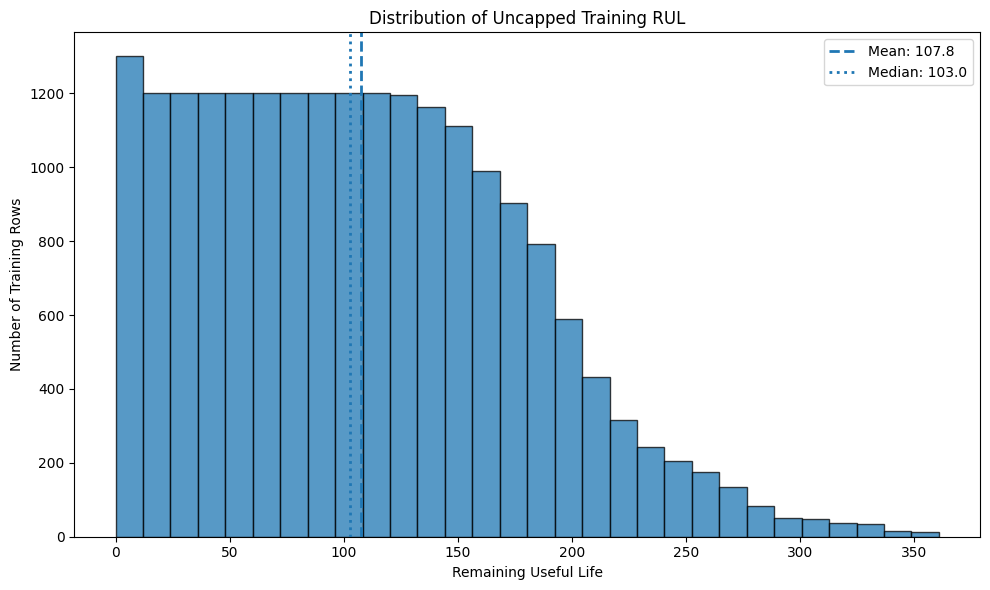

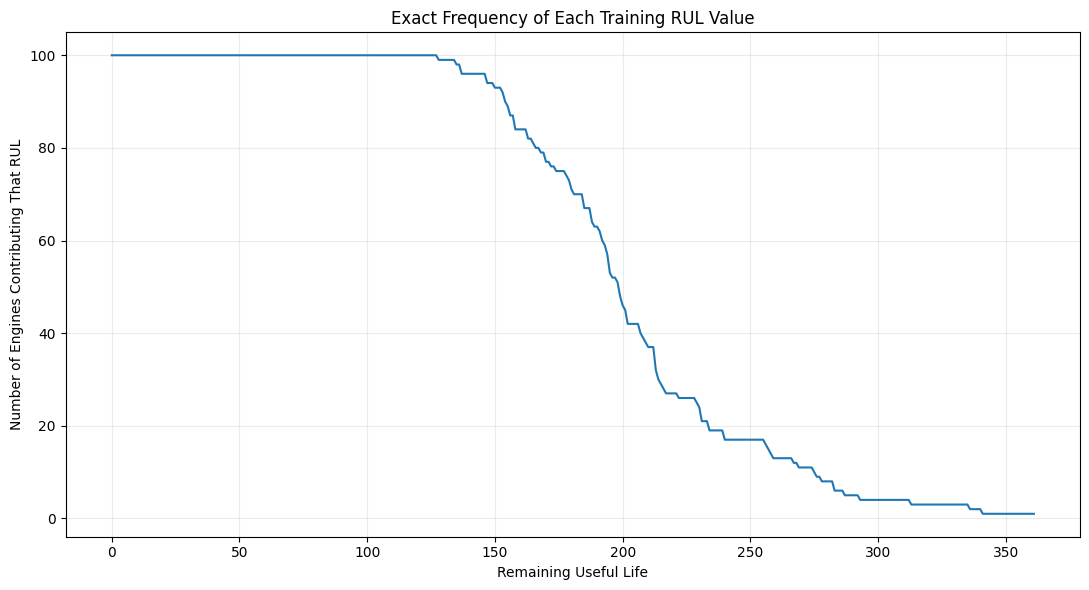

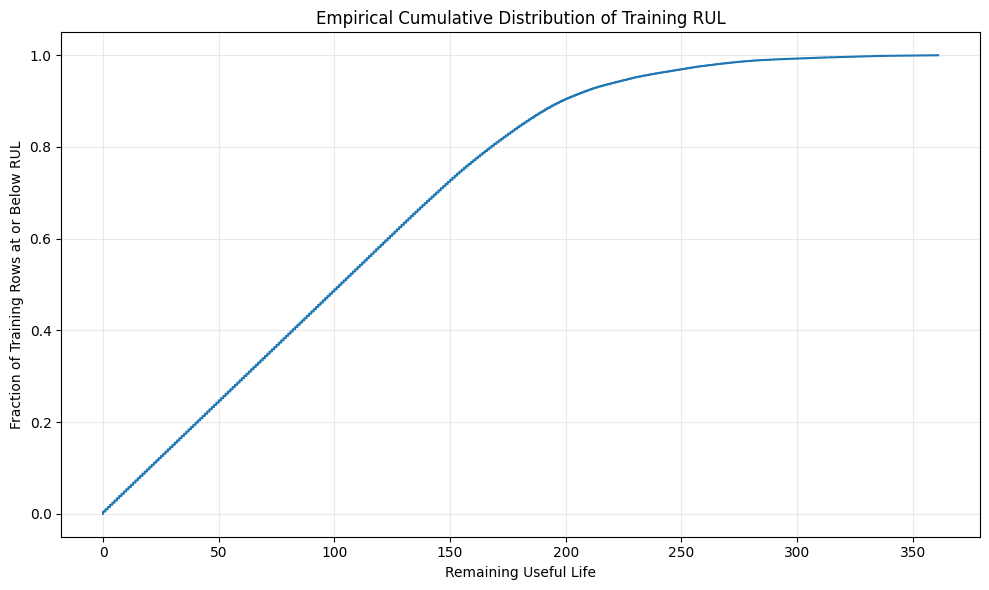

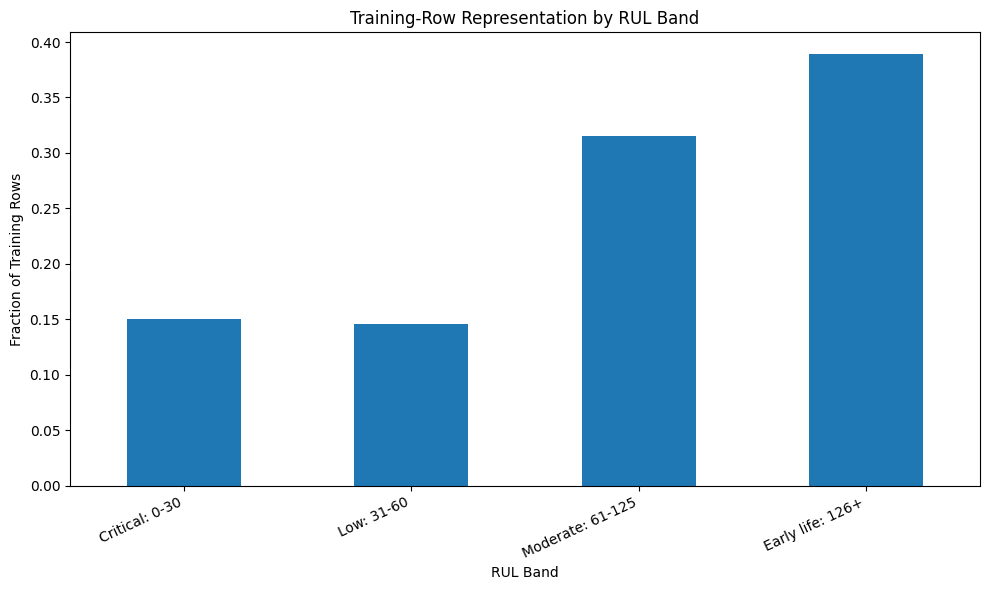

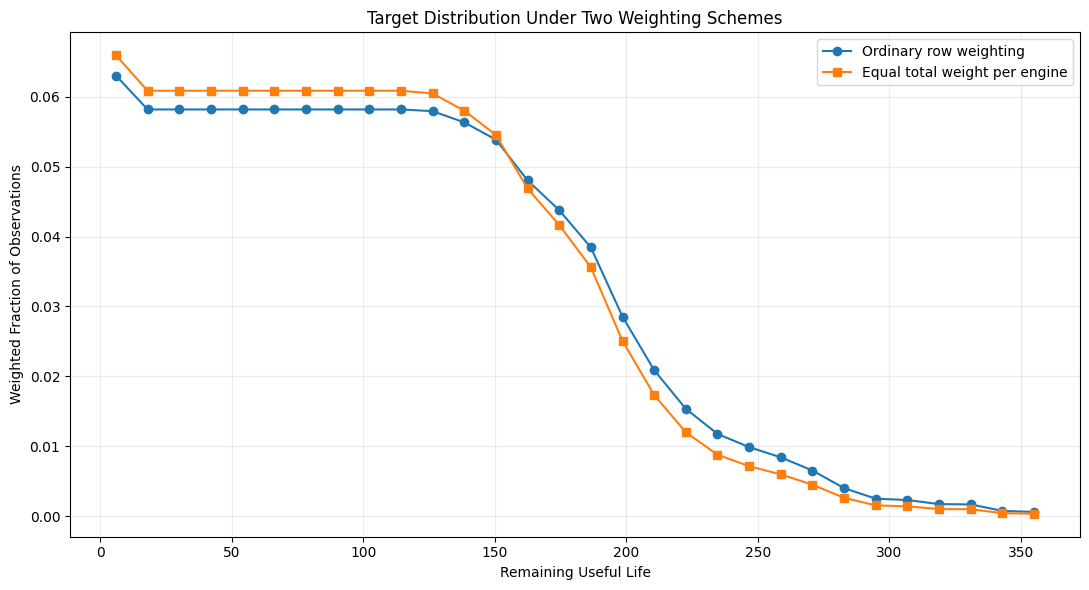

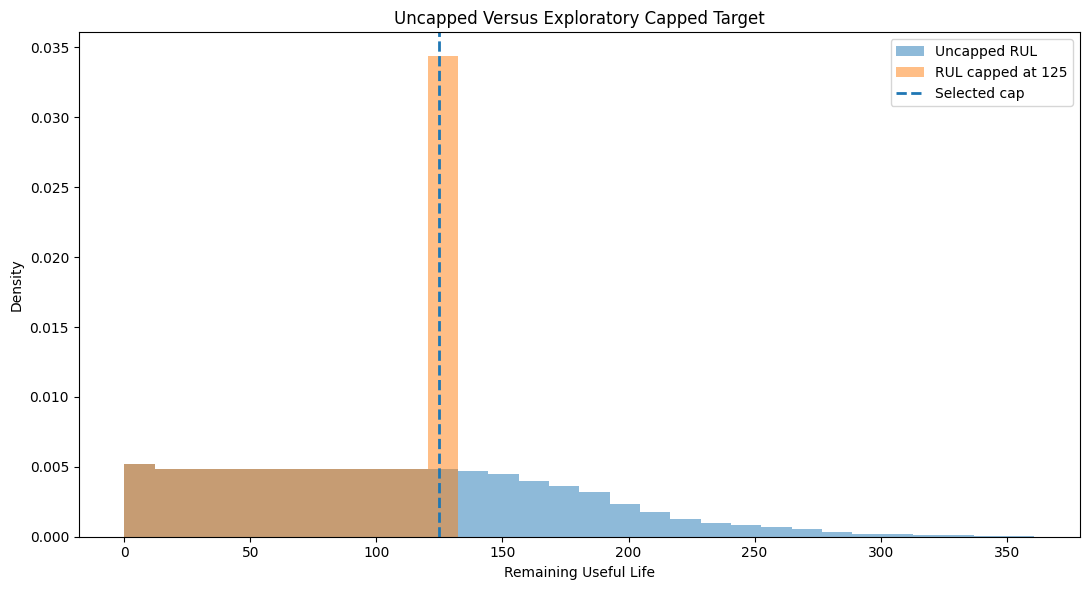

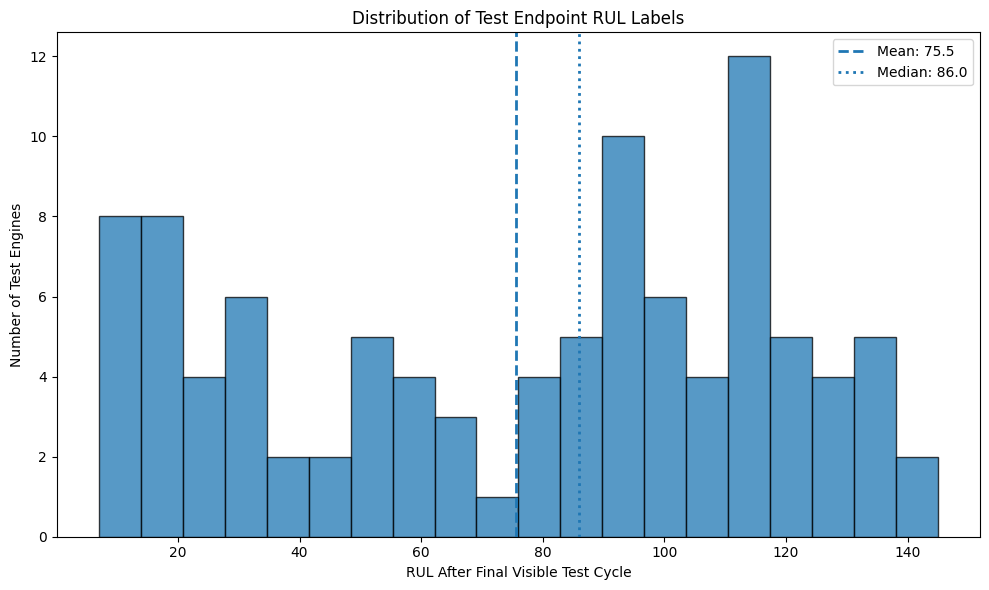


SECTION 12 SUMMARY

The uncapped training target contains 20,631 row-level RUL
observations from 100 engines. RUL ranges
from 0 to 361, with a mean of
107.81 and a median of 103.00.

The exact frequency of an RUL value is determined by the number of
engines whose sequence is long enough to reach that value. Low RUL
values are represented by every engine, while very high RUL values are
contributed only by the longest-lived engines.

Engine lifetimes are unequal. Under ordinary row-level model training,
longer-lived engines contribute more observations and therefore exert
more influence on the loss function. Individual engines account for
between 0.6204% and
1.7546% of all training rows. An
engine-balanced weighting scheme was constructed for comparison, but
no weighting decision was applied to the dataset.

Several possible RUL caps were evaluated without altering the original
target. With a cap of 125,
39.41% of training rows would lie on the capped
plateau. Capping would reduce the n

In [71]:
# ============================================================
# SECTION 12: EXPLORE THE TARGET DISTRIBUTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ------------------------------------------------------------
# 12-1: Validate the target column
# ------------------------------------------------------------

TARGET_COL = "rul"

required_columns = [
    "unit_no",
    "cycles",
    TARGET_COL
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        "Required target-analysis columns are missing:\n"
        f"{missing_columns}"
    )

target = train_df[TARGET_COL].copy()

if not pd.api.types.is_numeric_dtype(target):
    raise TypeError(
        f"{TARGET_COL!r} must be numeric."
    )

if target.isna().any():
    raise ValueError(
        f"{TARGET_COL!r} contains missing values."
    )

if target.lt(0).any():
    raise ValueError(
        f"{TARGET_COL!r} contains negative values."
    )


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

# These are exploratory target regions, not final business rules.
RUL_BINS = [
    -1,
    30,
    60,
    125,
    np.inf
]

RUL_BAND_LABELS = [
    "Critical: 0-30",
    "Low: 31-60",
    "Moderate: 61-125",
    "Early life: 126+"
]

# Candidate caps are evaluated without changing the original target.
RUL_CAP_CANDIDATES = [
    100,
    125,
    130,
    150
]

SELECTED_CAP_FOR_VISUALIZATION = 125


# ------------------------------------------------------------
# 12-2: Overall target summary
# ------------------------------------------------------------

target_summary = pd.Series({
    "row_count": len(target),
    "engine_count":
        train_df["unit_no"].nunique(),
    "missing_count":
        int(target.isna().sum()),
    "negative_count":
        int(target.lt(0).sum()),
    "unique_values":
        target.nunique(),
    "minimum":
        target.min(),
    "q01":
        target.quantile(0.01),
    "q05":
        target.quantile(0.05),
    "q10":
        target.quantile(0.10),
    "q25":
        target.quantile(0.25),
    "median":
        target.median(),
    "mean":
        target.mean(),
    "q75":
        target.quantile(0.75),
    "q90":
        target.quantile(0.90),
    "q95":
        target.quantile(0.95),
    "q99":
        target.quantile(0.99),
    "maximum":
        target.max(),
    "standard_deviation":
        target.std(),
    "variance":
        target.var(),
    "skewness":
        target.skew(),
    "kurtosis":
        target.kurt()
}, name="value")

print("=" * 90)
print("TRAINING TARGET SUMMARY")
print("=" * 90)

display(
    target_summary
    .to_frame()
    .round(4)
)


# ------------------------------------------------------------
# 12-3: Exact RUL frequencies
# ------------------------------------------------------------

exact_rul_frequency = (
    target
    .value_counts()
    .sort_index()
    .rename("row_count")
    .to_frame()
)

exact_rul_frequency.index.name = "rul"

exact_rul_frequency["row_fraction"] = (
    exact_rul_frequency["row_count"]
    / len(train_df)
)

# Because each engine contributes each exact RUL at most once,
# the exact row count is also the number of engines reaching
# that RUL value.
exact_rul_frequency["engine_fraction"] = (
    exact_rul_frequency["row_count"]
    / train_df["unit_no"].nunique()
)

sequence_lengths_section_12 = (
    train_df
    .groupby("unit_no")
    .size()
    .rename("sequence_length")
)

expected_rul_frequency = pd.Series(
    {
        rul_value:
            int(
                sequence_lengths_section_12
                .ge(rul_value + 1)
                .sum()
            )
        for rul_value
        in exact_rul_frequency.index
    },
    name="expected_from_sequence_lengths"
)

exact_rul_frequency = (
    exact_rul_frequency
    .join(expected_rul_frequency)
)

exact_rul_frequency["frequency_matches_engine_lengths"] = (
    exact_rul_frequency["row_count"]
    .eq(
        exact_rul_frequency[
            "expected_from_sequence_lengths"
        ]
    )
)

print("\n" + "=" * 90)
print("EXACT RUL FREQUENCIES")
print("=" * 90)

print("\nLowest RUL values:")
display(exact_rul_frequency.head(15))

print("Highest RUL values:")
display(exact_rul_frequency.tail(15))


# ------------------------------------------------------------
# 12-4: Explore target bands
# ------------------------------------------------------------

target_band_frame = train_df[
    [
        "unit_no",
        TARGET_COL
    ]
].copy()

target_band_frame["rul_band"] = pd.cut(
    target_band_frame[TARGET_COL],
    bins=RUL_BINS,
    labels=RUL_BAND_LABELS
)

target_band_report = (
    target_band_frame
    .groupby(
        "rul_band",
        observed=False
    )
    .agg(
        row_count=(TARGET_COL, "size"),
        unique_engines=("unit_no", "nunique"),
        minimum_rul=(TARGET_COL, "min"),
        maximum_rul=(TARGET_COL, "max"),
        mean_rul=(TARGET_COL, "mean")
    )
)

target_band_report["row_fraction"] = (
    target_band_report["row_count"]
    / len(train_df)
)

target_band_report["engine_fraction"] = (
    target_band_report["unique_engines"]
    / train_df["unit_no"].nunique()
)

print("\n" + "=" * 90)
print("TARGET-BAND REPRESENTATION")
print("=" * 90)

display(
    target_band_report.round(4)
)


# ------------------------------------------------------------
# 12-5: Target representation by engine lifetime
# ------------------------------------------------------------

engine_target_summary = (
    train_df
    .groupby("unit_no")
    .agg(
        sequence_length=("cycles", "size"),
        minimum_rul=(TARGET_COL, "min"),
        maximum_rul=(TARGET_COL, "max"),
        mean_rul=(TARGET_COL, "mean"),
        median_rul=(TARGET_COL, "median")
    )
)

engine_target_summary[
    "fraction_of_training_rows"
] = (
    engine_target_summary["sequence_length"]
    / len(train_df)
)

engine_lifetime_summary = (
    engine_target_summary
    .describe()
    .T
)

print("\n" + "=" * 90)
print("ENGINE-LEVEL TARGET REPRESENTATION")
print("=" * 90)

display(
    engine_lifetime_summary.round(4)
)

print(
    "\nShortest-lived engines:"
)

display(
    engine_target_summary
    .sort_values("sequence_length")
    .head(10)
)

print(
    "Longest-lived engines:"
)

display(
    engine_target_summary
    .sort_values(
        "sequence_length",
        ascending=False
    )
    .head(10)
)


# ------------------------------------------------------------
# 12-6: Compare row-level and engine-balanced weighting
# ------------------------------------------------------------

# In ordinary row-level training, long-lived engines contribute more
# observations and therefore more total loss.
#
# These weights make every engine contribute a total weight of 1.
engine_length_lookup = (
    sequence_lengths_section_12
)

engine_balancing_weights = (
    train_df["unit_no"]
    .map(engine_length_lookup)
    .rpow(-1)
)

# The expression above is equivalent to:
engine_balancing_weights = (
    1
    / train_df["unit_no"]
      .map(engine_length_lookup)
)

engine_weight_check = (
    pd.DataFrame({
        "unit_no": train_df["unit_no"],
        "weight": engine_balancing_weights
    })
    .groupby("unit_no")["weight"]
    .sum()
)

engine_weighting_summary = pd.Series({
    "ordinary_total_row_weight":
        float(len(train_df)),
    "engine_balanced_total_weight":
        float(engine_balancing_weights.sum()),
    "minimum_engine_total_weight":
        float(engine_weight_check.min()),
    "maximum_engine_total_weight":
        float(engine_weight_check.max())
}, name="value")

print("\n" + "=" * 90)
print("ROW-LEVEL VERSUS ENGINE-BALANCED WEIGHTING")
print("=" * 90)

display(
    engine_weighting_summary
    .to_frame()
    .round(6)
)


# ------------------------------------------------------------
# 12-7: Evaluate possible capped targets
# ------------------------------------------------------------

cap_rows = []

for cap in RUL_CAP_CANDIDATES:
    capped_target = target.clip(
        upper=cap
    )

    rows_above_cap = target.gt(cap)
    rows_at_or_above_cap = target.ge(cap)

    cap_rows.append({
        "cap": cap,
        "uncapped_maximum":
            target.max(),
        "capped_maximum":
            capped_target.max(),
        "uncapped_unique_values":
            target.nunique(),
        "capped_unique_values":
            capped_target.nunique(),
        "rows_strictly_above_cap":
            int(rows_above_cap.sum()),
        "fraction_strictly_above_cap":
            rows_above_cap.mean(),
        "rows_on_capped_plateau":
            int(rows_at_or_above_cap.sum()),
        "fraction_on_capped_plateau":
            rows_at_or_above_cap.mean(),
        "uncapped_mean":
            target.mean(),
        "capped_mean":
            capped_target.mean(),
        "mean_reduction":
            target.mean()
            - capped_target.mean(),
        "maximum_information_removed":
            target.max() - cap
    })

cap_comparison = (
    pd.DataFrame(cap_rows)
    .set_index("cap")
)

print("\n" + "=" * 90)
print("EXPLORATORY RUL-CAP COMPARISON")
print("=" * 90)

display(
    cap_comparison.round(4)
)


# Create temporary target variants without modifying train_df.
target_variant_df = pd.DataFrame({
    "uncapped_rul": target
})

for cap in RUL_CAP_CANDIDATES:
    target_variant_df[
        f"rul_capped_{cap}"
    ] = target.clip(upper=cap)


# ------------------------------------------------------------
# 12-8: Locate test endpoint RUL labels when available
# ------------------------------------------------------------

test_endpoint_target = None
test_endpoint_source = None

if (
    "test_endpoint_summary" in globals()
    and isinstance(
        test_endpoint_summary,
        pd.DataFrame
    )
    and "endpoint_rul"
        in test_endpoint_summary.columns
):
    test_endpoint_target = (
        test_endpoint_summary[
            "endpoint_rul"
        ]
        .dropna()
        .copy()
    )

    test_endpoint_source = (
        "test_endpoint_summary['endpoint_rul']"
    )

elif (
    "engine_rul_table" in globals()
    and isinstance(
        engine_rul_table,
        pd.DataFrame
    )
    and "endpoint_rul"
        in engine_rul_table.columns
):
    test_endpoint_target = (
        engine_rul_table[
            "endpoint_rul"
        ]
        .dropna()
        .copy()
    )

    test_endpoint_source = (
        "engine_rul_table['endpoint_rul']"
    )

elif (
    "rul_df" in globals()
    and isinstance(rul_df, pd.DataFrame)
):
    if "rul" in rul_df.columns:
        test_endpoint_target = (
            rul_df["rul"]
            .dropna()
            .copy()
        )

        test_endpoint_source = (
            "rul_df['rul']"
        )


if test_endpoint_target is not None:

    test_endpoint_target_summary = pd.Series({
        "source":
            test_endpoint_source,
        "label_count":
            len(test_endpoint_target),
        "missing_count":
            int(
                test_endpoint_target
                .isna()
                .sum()
            ),
        "unique_values":
            test_endpoint_target.nunique(),
        "minimum":
            test_endpoint_target.min(),
        "q25":
            test_endpoint_target.quantile(0.25),
        "median":
            test_endpoint_target.median(),
        "mean":
            test_endpoint_target.mean(),
        "q75":
            test_endpoint_target.quantile(0.75),
        "maximum":
            test_endpoint_target.max(),
        "standard_deviation":
            test_endpoint_target.std(),
        "skewness":
            test_endpoint_target.skew()
    }, name="value")

    print("\n" + "=" * 90)
    print("TEST ENDPOINT RUL LABEL SUMMARY")
    print("=" * 90)

    display(
        test_endpoint_target_summary
        .to_frame()
    )

else:
    test_endpoint_target_summary = None

    print("\nNo test endpoint target object was detected.")


# ------------------------------------------------------------
# 12-9: Plot uncapped target histogram
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.hist(
    target,
    bins=30,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    target.mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean: {target.mean():.1f}"
)

plt.axvline(
    target.median(),
    linestyle=":",
    linewidth=2,
    label=f"Median: {target.median():.1f}"
)

plt.title(
    "Distribution of Uncapped Training RUL"
)

plt.xlabel(
    "Remaining Useful Life"
)

plt.ylabel(
    "Number of Training Rows"
)

plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12-10: Plot exact target frequency
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.plot(
    exact_rul_frequency.index,
    exact_rul_frequency["row_count"]
)

plt.title(
    "Exact Frequency of Each Training RUL Value"
)

plt.xlabel(
    "Remaining Useful Life"
)

plt.ylabel(
    "Number of Engines Contributing That RUL"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12-11: Plot the empirical cumulative distribution
# ------------------------------------------------------------

sorted_target = np.sort(
    target.to_numpy()
)

cumulative_probability = (
    np.arange(
        1,
        len(sorted_target) + 1
    )
    / len(sorted_target)
)

plt.figure(figsize=(10, 6))

plt.plot(
    sorted_target,
    cumulative_probability
)

plt.title(
    "Empirical Cumulative Distribution of Training RUL"
)

plt.xlabel(
    "Remaining Useful Life"
)

plt.ylabel(
    "Fraction of Training Rows at or Below RUL"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12-12: Plot target-band proportions
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

target_band_report[
    "row_fraction"
].plot.bar()

plt.title(
    "Training-Row Representation by RUL Band"
)

plt.xlabel(
    "RUL Band"
)

plt.ylabel(
    "Fraction of Training Rows"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12-13: Plot ordinary versus engine-balanced distributions
# ------------------------------------------------------------

shared_bin_edges = np.linspace(
    target.min(),
    target.max(),
    31
)

ordinary_histogram, _ = np.histogram(
    target,
    bins=shared_bin_edges
)

balanced_histogram, _ = np.histogram(
    target,
    bins=shared_bin_edges,
    weights=engine_balancing_weights
)

ordinary_histogram = (
    ordinary_histogram
    / ordinary_histogram.sum()
)

balanced_histogram = (
    balanced_histogram
    / balanced_histogram.sum()
)

bin_centers = (
    shared_bin_edges[:-1]
    + shared_bin_edges[1:]
) / 2

plt.figure(figsize=(11, 6))

plt.plot(
    bin_centers,
    ordinary_histogram,
    marker="o",
    label="Ordinary row weighting"
)

plt.plot(
    bin_centers,
    balanced_histogram,
    marker="s",
    label="Equal total weight per engine"
)

plt.title(
    "Target Distribution Under Two Weighting Schemes"
)

plt.xlabel(
    "Remaining Useful Life"
)

plt.ylabel(
    "Weighted Fraction of Observations"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12-14: Visualize uncapped and selected capped target
# ------------------------------------------------------------

selected_capped_target = target.clip(
    upper=SELECTED_CAP_FOR_VISUALIZATION
)

shared_cap_bins = np.linspace(
    0,
    target.max(),
    31
)

plt.figure(figsize=(11, 6))

plt.hist(
    target,
    bins=shared_cap_bins,
    density=True,
    alpha=0.50,
    label="Uncapped RUL"
)

plt.hist(
    selected_capped_target,
    bins=shared_cap_bins,
    density=True,
    alpha=0.50,
    label=(
        "RUL capped at "
        f"{SELECTED_CAP_FOR_VISUALIZATION}"
    )
)

plt.axvline(
    SELECTED_CAP_FOR_VISUALIZATION,
    linestyle="--",
    linewidth=2,
    label="Selected cap"
)

plt.title(
    "Uncapped Versus Exploratory Capped Target"
)

plt.xlabel(
    "Remaining Useful Life"
)

plt.ylabel(
    "Density"
)

plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12-15: Plot test endpoint-label distribution separately
# ------------------------------------------------------------

if test_endpoint_target is not None:

    plt.figure(figsize=(10, 6))

    plt.hist(
        test_endpoint_target,
        bins=20,
        edgecolor="black",
        alpha=0.75
    )

    plt.axvline(
        test_endpoint_target.mean(),
        linestyle="--",
        linewidth=2,
        label=(
            "Mean: "
            f"{test_endpoint_target.mean():.1f}"
        )
    )

    plt.axvline(
        test_endpoint_target.median(),
        linestyle=":",
        linewidth=2,
        label=(
            "Median: "
            f"{test_endpoint_target.median():.1f}"
        )
    )

    plt.title(
        "Distribution of Test Endpoint RUL Labels"
    )

    plt.xlabel(
        "RUL After Final Visible Test Cycle"
    )

    plt.ylabel(
        "Number of Test Engines"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 12-16: Automated validation
# ------------------------------------------------------------

assert target.notna().all()
assert target.ge(0).all()

assert target.min() == 0

assert (
    exact_rul_frequency[
        "frequency_matches_engine_lengths"
    ]
    .all()
)

assert (
    engine_weight_check
    .sub(1)
    .abs()
    .lt(1e-10)
    .all()
)

assert (
    target_band_report[
        "row_count"
    ].sum()
    == len(train_df)
)

assert np.isclose(
    target_band_report[
        "row_fraction"
    ].sum(),
    1
)

for cap in RUL_CAP_CANDIDATES:
    capped_col = f"rul_capped_{cap}"

    assert (
        target_variant_df[capped_col]
        .le(cap)
        .all()
    )

    assert (
        target_variant_df[capped_col]
        .le(
            target_variant_df[
                "uncapped_rul"
            ]
        )
        .all()
    )

if "final_cycle" in train_df.columns:

    target_construction_check = (
        train_df[TARGET_COL]
        .eq(
            train_df["final_cycle"]
            - train_df["cycles"]
        )
    )

    assert target_construction_check.all()

if test_endpoint_target is not None:

    assert test_endpoint_target.notna().all()
    assert test_endpoint_target.ge(0).all()

    if "test_df" in globals():
        assert (
            len(test_endpoint_target)
            == test_df["unit_no"].nunique()
        )


# ------------------------------------------------------------
# 12-17: Written Section 12 summary
# ------------------------------------------------------------

largest_engine_row_fraction = (
    engine_target_summary[
        "fraction_of_training_rows"
    ]
    .max()
)

smallest_engine_row_fraction = (
    engine_target_summary[
        "fraction_of_training_rows"
    ]
    .min()
)

selected_cap_fraction = (
    cap_comparison.loc[
        SELECTED_CAP_FOR_VISUALIZATION,
        "fraction_on_capped_plateau"
    ]
)

if test_endpoint_target is not None:
    endpoint_summary_text = f"""
The test endpoint-label file contains {len(test_endpoint_target)}
labels: one label for each test engine. These labels describe RUL after
the final visible test cycle and are therefore not directly comparable
to the row-level training-target distribution, which contains one RUL
value for every observed training cycle.
"""
else:
    endpoint_summary_text = """
A test endpoint-label object was not detected in the current notebook
namespace, so only the training target was summarized.
"""


section_12_summary = f"""
SECTION 12 SUMMARY

The uncapped training target contains {len(target):,} row-level RUL
observations from {train_df["unit_no"].nunique()} engines. RUL ranges
from {target.min()} to {target.max()}, with a mean of
{target.mean():.2f} and a median of {target.median():.2f}.

The exact frequency of an RUL value is determined by the number of
engines whose sequence is long enough to reach that value. Low RUL
values are represented by every engine, while very high RUL values are
contributed only by the longest-lived engines.

Engine lifetimes are unequal. Under ordinary row-level model training,
longer-lived engines contribute more observations and therefore exert
more influence on the loss function. Individual engines account for
between {smallest_engine_row_fraction:.4%} and
{largest_engine_row_fraction:.4%} of all training rows. An
engine-balanced weighting scheme was constructed for comparison, but
no weighting decision was applied to the dataset.

Several possible RUL caps were evaluated without altering the original
target. With a cap of {SELECTED_CAP_FOR_VISUALIZATION},
{selected_cap_fraction:.2%} of training rows would lie on the capped
plateau. Capping would reduce the need to distinguish precise RUL
values during early healthy operation, but it would also discard
target information.

{endpoint_summary_text.strip()}

The initial modeling target remains uncapped RUL. Capped targets,
engine-balanced sample weights, and RUL-region-specific evaluation
should be treated as separate validation experiments rather than
permanent EDA transformations.
"""

print("\n" + "=" * 90)
print(section_12_summary.strip())
print("=" * 90)

print("\nSection 12 completed successfully.")

### Section 13: Leakage Risk Review

In [72]:
# ============================================================
# SECTION 13: LEAKAGE RISK REVIEW
# ============================================================

import re
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit
)


# ------------------------------------------------------------
# 13-1: Define known column roles
# ------------------------------------------------------------

TARGET_COL = "rul"
GROUP_COL = "unit_no"
TIME_COL = "cycles"

if "setting_cols" not in globals():
    setting_cols = [
        "op_setting_1",
        "op_setting_2",
        "op_setting_3"
    ]

if "sensor_cols" not in globals():
    sensor_cols = [
        f"sensor_measurement_{i}"
        for i in range(1, 22)
    ]

if "constant_sensor_cols" not in globals():
    constant_sensor_cols = [
        col for col in sensor_cols
        if train_df[col].nunique(dropna=False) == 1
    ]

required_train_columns = [
    GROUP_COL,
    TIME_COL,
    TARGET_COL
] + setting_cols + sensor_cols

missing_train_columns = [
    col for col in required_train_columns
    if col not in train_df.columns
]

required_test_columns = [
    GROUP_COL,
    TIME_COL
] + setting_cols + sensor_cols

missing_test_columns = [
    col for col in required_test_columns
    if col not in test_df.columns
]

if missing_train_columns or missing_test_columns:
    raise ValueError(
        "Expected columns are missing.\n"
        f"Missing from training: {missing_train_columns}\n"
        f"Missing from test: {missing_test_columns}"
    )


# Columns that are known to be unavailable during real inference.
known_direct_leakage_cols = [
    TARGET_COL,
    "final_cycle"
]

# Columns used for bookkeeping or splitting, not prediction.
identifier_only_cols = [
    GROUP_COL
]

# Features available at the current prediction cycle.
inference_available_cols = (
    [TIME_COL]
    + setting_cols
    + sensor_cols
)


# ------------------------------------------------------------
# 13-2: Classify every training column by role
# ------------------------------------------------------------

def classify_column_role(column):
    if column == TARGET_COL:
        return "target"

    if column == GROUP_COL:
        return "group_identifier_only"

    if column == TIME_COL:
        return "available_at_prediction_time"

    if column in setting_cols:
        return "operating_setting"

    if column in sensor_cols:
        return "sensor_measurement"

    if column == "final_cycle":
        return "future_derived_direct_leakage"

    return "unknown_review_required"


column_role_report = pd.DataFrame({
    "column": train_df.columns
})

column_role_report["role"] = (
    column_role_report["column"]
    .map(classify_column_role)
)

column_role_report["present_in_test"] = (
    column_role_report["column"]
    .isin(test_df.columns)
)

column_role_report["allowed_as_model_input"] = (
    column_role_report["role"]
    .isin([
        "available_at_prediction_time",
        "operating_setting",
        "sensor_measurement"
    ])
)

print("=" * 95)
print("TRAINING COLUMN ROLE REPORT")
print("=" * 95)

display(column_role_report)


# ------------------------------------------------------------
# 13-3: Search column names for possible leakage indicators
# ------------------------------------------------------------

leakage_name_pattern = re.compile(
    r"("
    r"rul|"
    r"remaining|"
    r"target|"
    r"label|"
    r"final|"
    r"failure|"
    r"future|"
    r"endpoint|"
    r"time_to_failure|"
    r"max_cycle|"
    r"sequence_length|"
    r"life_fraction|"
    r"next_|"
    r"lead"
    r")",
    flags=re.IGNORECASE
)

name_flagged_train_columns = [
    col for col in train_df.columns
    if leakage_name_pattern.search(col)
]

name_flagged_test_columns = [
    col for col in test_df.columns
    if leakage_name_pattern.search(col)
]

name_flag_report = pd.DataFrame({
    "column": sorted(
        set(
            name_flagged_train_columns
            + name_flagged_test_columns
        )
    )
})

if not name_flag_report.empty:
    name_flag_report["present_in_train"] = (
        name_flag_report["column"]
        .isin(train_df.columns)
    )

    name_flag_report["present_in_test"] = (
        name_flag_report["column"]
        .isin(test_df.columns)
    )

    name_flag_report["known_role"] = (
        name_flag_report["column"]
        .map(classify_column_role)
    )

print("\n" + "=" * 95)
print("COLUMNS FLAGGED BY LEAKAGE-RELATED NAMES")
print("=" * 95)

if name_flag_report.empty:
    print("No column names were flagged.")
else:
    display(name_flag_report)


# ------------------------------------------------------------
# 13-4: Demonstrate why final_cycle is direct leakage
# ------------------------------------------------------------

final_cycle_reconstructs_target = None

if "final_cycle" in train_df.columns:
    reconstructed_rul = (
        train_df["final_cycle"]
        - train_df[TIME_COL]
    )

    final_cycle_reconstructs_target = bool(
        reconstructed_rul
        .eq(train_df[TARGET_COL])
        .all()
    )

    target_reconstruction_report = pd.Series({
        "formula":
            "final_cycle - cycles",
        "matches_rul_for_every_row":
            final_cycle_reconstructs_target,
        "mismatched_rows":
            int(
                reconstructed_rul
                .ne(train_df[TARGET_COL])
                .sum()
            )
    })

    print("\n" + "=" * 95)
    print("DIRECT TARGET RECONSTRUCTION CHECK")
    print("=" * 95)

    display(
        target_reconstruction_report
        .to_frame("result")
    )


# ------------------------------------------------------------
# 13-5: Define leakage-safe model feature sets
# ------------------------------------------------------------

leakage_safe_feature_cols = [
    col for col in inference_available_cols
    if (
        col in train_df.columns
        and col in test_df.columns
    )
]

# Optional baseline list that also removes exactly constant sensors.
# Constant-feature removal is a modeling choice, not a leakage rule.
baseline_feature_cols = [
    col for col in leakage_safe_feature_cols
    if col not in constant_sensor_cols
]

X_leakage_safe = (
    train_df[leakage_safe_feature_cols]
    .copy()
)

X_baseline = (
    train_df[baseline_feature_cols]
    .copy()
)

y_regression = (
    train_df[TARGET_COL]
    .copy()
)

engine_groups = (
    train_df[GROUP_COL]
    .copy()
)

X_test_leakage_safe = (
    test_df[leakage_safe_feature_cols]
    .copy()
)

X_test_baseline = (
    test_df[baseline_feature_cols]
    .copy()
)


feature_set_report = pd.DataFrame({
    "feature_set": [
        "Leakage-safe raw features",
        "Baseline after constant-sensor removal"
    ],
    "feature_count": [
        len(leakage_safe_feature_cols),
        len(baseline_feature_cols)
    ],
    "features": [
        leakage_safe_feature_cols,
        baseline_feature_cols
    ]
})

print("\n" + "=" * 95)
print("LEAKAGE-SAFE FEATURE SETS")
print("=" * 95)

display(feature_set_report)

print("Training leakage-safe shape:",
      X_leakage_safe.shape)

print("Training baseline shape:",
      X_baseline.shape)

print("Target shape:",
      y_regression.shape)

print("Grouping Series shape:",
      engine_groups.shape)

print("Test baseline shape:",
      X_test_baseline.shape)


# ------------------------------------------------------------
# 13-6: Verify train/test feature alignment
# ------------------------------------------------------------

safe_feature_names_match = (
    X_leakage_safe.columns.tolist()
    == X_test_leakage_safe.columns.tolist()
)

safe_feature_dtypes_match = (
    X_leakage_safe.dtypes
    .astype(str)
    .equals(
        X_test_leakage_safe.dtypes
        .astype(str)
    )
)

baseline_feature_names_match = (
    X_baseline.columns.tolist()
    == X_test_baseline.columns.tolist()
)

schema_audit = pd.Series({
    "leakage_safe_feature_names_match":
        safe_feature_names_match,
    "leakage_safe_feature_dtypes_match":
        safe_feature_dtypes_match,
    "baseline_feature_names_match":
        baseline_feature_names_match,
    "target_present_in_test_features":
        TARGET_COL in X_test_leakage_safe.columns,
    "final_cycle_present_in_safe_features":
        "final_cycle" in X_leakage_safe.columns,
    "unit_no_present_in_safe_features":
        GROUP_COL in X_leakage_safe.columns
})

print("\n" + "=" * 95)
print("TRAIN/TEST FEATURE-SCHEMA AUDIT")
print("=" * 95)

display(schema_audit.to_frame("result"))


# ------------------------------------------------------------
# 13-7: Search for exact or near-perfect target proxies
# ------------------------------------------------------------

proxy_rows = []

numeric_train_columns = (
    train_df
    .select_dtypes(include=np.number)
    .columns
)

for col in numeric_train_columns:
    if col == TARGET_COL:
        continue

    feature = train_df[col]

    exact_match = feature.eq(
        train_df[TARGET_COL]
    ).all()

    exact_negative_match = feature.eq(
        -train_df[TARGET_COL]
    ).all()

    if (
        feature.nunique() > 1
        and train_df[TARGET_COL].nunique() > 1
    ):
        target_correlation = feature.corr(
            train_df[TARGET_COL]
        )
    else:
        target_correlation = np.nan

    proxy_rows.append({
        "column": col,
        "exactly_equals_target":
            bool(exact_match),
        "exactly_equals_negative_target":
            bool(exact_negative_match),
        "correlation_with_target":
            target_correlation,
        "absolute_correlation":
            (
                abs(target_correlation)
                if pd.notna(target_correlation)
                else np.nan
            ),
        "in_model_feature_set":
            col in leakage_safe_feature_cols
    })

target_proxy_report = (
    pd.DataFrame(proxy_rows)
    .set_index("column")
    .sort_values(
        "absolute_correlation",
        ascending=False
    )
)

perfect_target_proxy_cols = (
    target_proxy_report.index[
        target_proxy_report[
            "exactly_equals_target"
        ]
        | target_proxy_report[
            "exactly_equals_negative_target"
        ]
    ]
    .tolist()
)

near_perfect_model_proxy_cols = (
    target_proxy_report.index[
        target_proxy_report[
            "in_model_feature_set"
        ]
        & target_proxy_report[
            "absolute_correlation"
        ].ge(0.999999)
    ]
    .tolist()
)

print("\n" + "=" * 95)
print("NUMERIC TARGET-PROXY REVIEW")
print("=" * 95)

display(
    target_proxy_report[
        [
            "exactly_equals_target",
            "exactly_equals_negative_target",
            "correlation_with_target",
            "in_model_feature_set"
        ]
    ]
    .head(15)
    .round(6)
)

print("Exact target-proxy columns:",
      perfect_target_proxy_cols)

print("Near-perfect proxies inside the model feature set:",
      near_perfect_model_proxy_cols)


# ------------------------------------------------------------
# 13-8: Demonstrate row-level split leakage
# ------------------------------------------------------------

all_row_indices = np.arange(
    len(train_df)
)

row_train_idx, row_validation_idx = (
    train_test_split(
        all_row_indices,
        test_size=0.20,
        random_state=42
    )
)

row_split_train_engines = set(
    train_df.iloc[row_train_idx][GROUP_COL]
)

row_split_validation_engines = set(
    train_df.iloc[row_validation_idx][GROUP_COL]
)

row_split_engine_overlap = (
    row_split_train_engines
    & row_split_validation_engines
)


group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

group_train_idx, group_validation_idx = next(
    group_splitter.split(
        X_leakage_safe,
        y_regression,
        groups=engine_groups
    )
)

group_split_train_engines = set(
    train_df.iloc[group_train_idx][GROUP_COL]
)

group_split_validation_engines = set(
    train_df.iloc[group_validation_idx][GROUP_COL]
)

group_split_engine_overlap = (
    group_split_train_engines
    & group_split_validation_engines
)


split_leakage_comparison = pd.DataFrame({
    "random_row_split": {
        "training_rows":
            len(row_train_idx),
        "validation_rows":
            len(row_validation_idx),
        "training_engines":
            len(row_split_train_engines),
        "validation_engines":
            len(row_split_validation_engines),
        "engines_in_both_partitions":
            len(row_split_engine_overlap),
        "leakage_risk":
            len(row_split_engine_overlap) > 0
    },
    "grouped_engine_split": {
        "training_rows":
            len(group_train_idx),
        "validation_rows":
            len(group_validation_idx),
        "training_engines":
            len(group_split_train_engines),
        "validation_engines":
            len(group_split_validation_engines),
        "engines_in_both_partitions":
            len(group_split_engine_overlap),
        "leakage_risk":
            len(group_split_engine_overlap) > 0
    }
}).T

print("\n" + "=" * 95)
print("RANDOM ROW SPLIT VERSUS GROUPED ENGINE SPLIT")
print("=" * 95)

display(split_leakage_comparison)


# ------------------------------------------------------------
# 13-9: Inspect engineered columns for temporal leakage risk
# ------------------------------------------------------------

raw_known_columns = set(
    [GROUP_COL, TIME_COL, TARGET_COL, "final_cycle"]
    + setting_cols
    + sensor_cols
)

engineered_train_columns = [
    col for col in train_df.columns
    if col not in raw_known_columns
]

temporal_feature_pattern = re.compile(
    r"("
    r"rolling|"
    r"moving|"
    r"lag|"
    r"lead|"
    r"diff|"
    r"delta|"
    r"slope|"
    r"trend|"
    r"ewm|"
    r"expanding|"
    r"window|"
    r"future|"
    r"next"
    r")",
    flags=re.IGNORECASE
)

temporally_named_columns = [
    col for col in train_df.columns
    if temporal_feature_pattern.search(col)
]

engineered_column_report = pd.DataFrame({
    "column": sorted(
        set(
            engineered_train_columns
            + temporally_named_columns
        )
    )
})

if not engineered_column_report.empty:
    engineered_column_report[
        "not_part_of_known_raw_schema"
    ] = (
        engineered_column_report["column"]
        .isin(engineered_train_columns)
    )

    engineered_column_report[
        "temporal_name_detected"
    ] = (
        engineered_column_report["column"]
        .isin(temporally_named_columns)
    )

    engineered_column_report[
        "requires_manual_causality_review"
    ] = True

print("\n" + "=" * 95)
print("ENGINEERED/TEMPORAL COLUMN REVIEW")
print("=" * 95)

if engineered_column_report.empty:
    print(
        "No additional engineered or temporally named "
        "columns were detected."
    )
else:
    display(engineered_column_report)


# ------------------------------------------------------------
# 13-10: Review test-label isolation
# ------------------------------------------------------------

possible_test_label_objects = [
    name
    for name in [
        "rul_df",
        "test_rul_df",
        "engine_rul_table",
        "test_endpoint_summary",
        "test_endpoint_target"
    ]
    if name in globals()
]

test_target_like_columns = [
    col for col in test_df.columns
    if leakage_name_pattern.search(col)
]

test_label_isolation_report = pd.Series({
    "test_label_objects_detected":
        possible_test_label_objects,
    "target_like_columns_inside_test_df":
        test_target_like_columns,
    "test_df_contains_rul":
        TARGET_COL in test_df.columns,
    "test_df_contains_final_cycle":
        "final_cycle" in test_df.columns,
    "test_labels_are_separate_from_test_features":
        len(test_target_like_columns) == 0
})

print("\n" + "=" * 95)
print("TEST-LABEL ISOLATION REVIEW")
print("=" * 95)

display(
    test_label_isolation_report
    .to_frame("result")
)


# ------------------------------------------------------------
# 13-11: Create the leakage-prevention checklist
# ------------------------------------------------------------

leakage_prevention_checklist = pd.DataFrame([
    {
        "risk_area": "Target included as feature",
        "unsafe_example": "Using rul inside X",
        "required_control":
            "Remove the target before model fitting",
        "current_status":
            TARGET_COL not in X_leakage_safe.columns
    },
    {
        "risk_area": "Future failure-cycle information",
        "unsafe_example":
            "Using final_cycle, sequence length, or failure cycle",
        "required_control":
            "Exclude all full-lifecycle quantities",
        "current_status":
            "final_cycle" not in X_leakage_safe.columns
    },
    {
        "risk_area": "Engine identifier memorization",
        "unsafe_example":
            "Using unit_no as a numeric feature",
        "required_control":
            "Use unit_no only as the grouping variable",
        "current_status":
            GROUP_COL not in X_leakage_safe.columns
    },
    {
        "risk_area": "Same engine in train and validation",
        "unsafe_example":
            "Random train_test_split across rows",
        "required_control":
            "Split entire engines with GroupShuffleSplit or GroupKFold",
        "current_status":
            len(group_split_engine_overlap) == 0
    },
    {
        "risk_area": "Preprocessing fitted before splitting",
        "unsafe_example":
            "Fitting a scaler using all engines",
        "required_control":
            "Fit preprocessing only on each training fold",
        "current_status":
            "Must be enforced during modeling"
    },
    {
        "risk_area": "Future-aware rolling features",
        "unsafe_example":
            "Centered windows, negative shifts, or forward-looking means",
        "required_control":
            "Use current and historical cycles only",
        "current_status":
            "Must be enforced during feature engineering"
    },
    {
        "risk_area": "Whole-engine aggregate features",
        "unsafe_example":
            "Using an engine's eventual max, mean, or final measurement",
        "required_control":
            "Use expanding or rolling history available by that cycle",
        "current_status":
            "Must be enforced during feature engineering"
    },
    {
        "risk_area": "Test labels used for model selection",
        "unsafe_example":
            "Choosing features or hyperparameters from test endpoint RMSE",
        "required_control":
            "Reserve test endpoint labels for final evaluation",
        "current_status":
            len(test_target_like_columns) == 0
    }
])

print("\n" + "=" * 95)
print("LEAKAGE-PREVENTION CHECKLIST")
print("=" * 95)

display(leakage_prevention_checklist)


# ------------------------------------------------------------
# 13-12: Consolidated audit report
# ------------------------------------------------------------

leakage_audit_report = pd.Series({
    "target_excluded_from_features":
        TARGET_COL not in X_leakage_safe.columns,
    "final_cycle_excluded_from_features":
        "final_cycle" not in X_leakage_safe.columns,
    "unit_no_excluded_from_features":
        GROUP_COL not in X_leakage_safe.columns,
    "current_cycle_retained":
        TIME_COL in X_leakage_safe.columns,
    "safe_train_test_columns_match":
        safe_feature_names_match,
    "safe_train_test_dtypes_match":
        safe_feature_dtypes_match,
    "exact_target_proxy_count":
        len(perfect_target_proxy_cols),
    "near_perfect_model_proxy_count":
        len(near_perfect_model_proxy_cols),
    "random_row_split_engine_overlap":
        len(row_split_engine_overlap),
    "grouped_split_engine_overlap":
        len(group_split_engine_overlap),
    "test_target_like_column_count":
        len(test_target_like_columns),
    "final_cycle_reconstructs_target":
        final_cycle_reconstructs_target
})

print("\n" + "=" * 95)
print("CONSOLIDATED LEAKAGE AUDIT")
print("=" * 95)

display(
    leakage_audit_report
    .to_frame("result")
)


# ------------------------------------------------------------
# 13-13: Automated assertions
# ------------------------------------------------------------

assert TARGET_COL not in leakage_safe_feature_cols
assert "final_cycle" not in leakage_safe_feature_cols
assert GROUP_COL not in leakage_safe_feature_cols

assert TIME_COL in leakage_safe_feature_cols

assert len(X_leakage_safe) == len(y_regression)
assert len(X_leakage_safe) == len(engine_groups)

assert safe_feature_names_match
assert safe_feature_dtypes_match
assert baseline_feature_names_match

assert set(X_leakage_safe.columns).issubset(
    test_df.columns
)

assert len(group_split_engine_overlap) == 0

assert TARGET_COL not in test_df.columns
assert "final_cycle" not in test_df.columns

assert len(near_perfect_model_proxy_cols) == 0

if "final_cycle" in train_df.columns:
    assert final_cycle_reconstructs_target


# ------------------------------------------------------------
# 13-14: Written Section 13 summary
# ------------------------------------------------------------

section_13_summary = f"""
SECTION 13 SUMMARY

The dataset and proposed model-input columns were reviewed for direct,
indirect, temporal, split-related, and preprocessing-related leakage.

The RUL target and final_cycle columns were excluded from the model
feature set. final_cycle is direct leakage because subtracting the
current cycle from final_cycle reconstructs RUL exactly:

final_cycle - cycles = rul

The unit_no column was also excluded from the predictive features.
It is retained only as the grouping variable used to keep complete
engine sequences together during model validation.

The cycles column was retained. Current engine age is available at
prediction time and is therefore not inherently leakage, although its
predictive contribution should still be evaluated against sensor-based
models.

A random row-level split placed
{len(row_split_engine_overlap)} engines in both the training and
validation partitions. This would allow closely related observations
from the same engine lifecycle to appear on both sides of the split.

The grouped split placed
{len(group_split_engine_overlap)} engines in both partitions. A grouped
engine split is therefore required for validation.

The leakage-safe raw feature set contains
{len(leakage_safe_feature_cols)} columns. After excluding exactly
constant sensors, the proposed baseline feature set contains
{len(baseline_feature_cols)} columns.

No near-perfect target proxy was found inside the leakage-safe feature
set. The training and test feature names and data types align.

Future feature engineering must use only measurements available at the
current or earlier cycles. Centered windows, forward shifts, eventual
engine sequence lengths, full-lifecycle aggregates, and future sensor
values would create temporal leakage.

Scalers, imputers, feature selectors, and dimensionality-reduction
methods must be fitted only on the training portion of each grouped
split. The test endpoint RUL labels must remain isolated until final
model evaluation.
"""

print("\n" + "=" * 95)
print(section_13_summary.strip())
print("=" * 95)

print("\nSection 13 completed successfully.")

TRAINING COLUMN ROLE REPORT


,column,role,present_in_test,allowed_as_model_input
0,unit_no,group_identifier_only,True,False
1,cycles,available_at_prediction_time,True,True
2,op_setting_1,operating_setting,True,True
3,op_setting_2,operating_setting,True,True
4,op_setting_3,operating_setting,True,True
5,sensor_measurement_1,sensor_measurement,True,True
6,sensor_measurement_2,sensor_measurement,True,True
7,sensor_measurement_3,sensor_measurement,True,True
8,sensor_measurement_4,sensor_measurement,True,True
9,sensor_measurement_5,sensor_measurement,True,True



COLUMNS FLAGGED BY LEAKAGE-RELATED NAMES


,column,present_in_train,present_in_test,known_role
0,final_cycle,True,False,future_derived_direct_leakage
1,rul,True,False,target



DIRECT TARGET RECONSTRUCTION CHECK


...


LEAKAGE-PREVENTION CHECKLIST


,risk_area,unsafe_example,required_control,current_status
0,Target included as feature,Using rul inside X,Remove the target before model fitting,True
1,Future failure-cycle information,"Using final_cycle, sequence length, or failure...",Exclude all full-lifecycle quantities,True
2,Engine identifier memorization,Using unit_no as a numeric feature,Use unit_no only as the grouping variable,True
3,Same engine in train and validation,Random train_test_split across rows,Split entire engines with GroupShuffleSplit or...,True
4,Preprocessing fitted before splitting,Fitting a scaler using all engines,Fit preprocessing only on each training fold,Must be enforced during modeling
5,Future-aware rolling features,"Centered windows, negative shifts, or forward-...",Use current and historical cycles only,Must be enforced during feature engineering
6,Whole-engine aggregate features,"Using an engine's eventual max, mean, or final...",Use expanding or rolling history available by ...,Must be enforced during feature engineering
7,Test labels used for model selection,Choosing features or hyperparameters from test...,Reserve test endpoint labels for final evaluation,True



CONSOLIDATED LEAKAGE AUDIT


,result
target_excluded_from_features,True
final_cycle_excluded_from_features,True
unit_no_excluded_from_features,True
current_cycle_retained,True
safe_train_test_columns_match,True
safe_train_test_dtypes_match,True
exact_target_proxy_count,0
near_perfect_model_proxy_count,0
random_row_split_engine_overlap,100
grouped_split_engine_overlap,0



SECTION 13 SUMMARY

The dataset and proposed model-input columns were reviewed for direct,
indirect, temporal, split-related, and preprocessing-related leakage.

The RUL target and final_cycle columns were excluded from the model
feature set. final_cycle is direct leakage because subtracting the
current cycle from final_cycle reconstructs RUL exactly:

final_cycle - cycles = rul

The unit_no column was also excluded from the predictive features.
It is retained only as the grouping variable used to keep complete
engine sequences together during model validation.

The cycles column was retained. Current engine age is available at
prediction time and is therefore not inherently leakage, although its
predictive contribution should still be evaluated against sensor-based
models.

A random row-level split placed
100 engines in both the training and
validation partitions. This would allow closely related observations
from the same engine lifecycle to appear on both sides of the split.

The g

### Section 14: Candidate Feature Groups for Phase 3

In [73]:
# ============================================================
# SECTION 14: CANDIDATE FEATURE GROUPS FOR PHASE 3
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 14-1: Define core column roles
# ------------------------------------------------------------

TARGET_COL = "rul"
GROUP_COL = "unit_no"
TIME_COL = "cycles"

setting_cols = [
    "op_setting_1",
    "op_setting_2",
    "op_setting_3"
]

sensor_cols = [
    f"sensor_measurement_{i}"
    for i in range(1, 22)
]

required_train_cols = (
    [GROUP_COL, TIME_COL, TARGET_COL]
    + setting_cols
    + sensor_cols
)

required_test_cols = (
    [GROUP_COL, TIME_COL]
    + setting_cols
    + sensor_cols
)

missing_train_cols = [
    col for col in required_train_cols
    if col not in train_df.columns
]

missing_test_cols = [
    col for col in required_test_cols
    if col not in test_df.columns
]

if missing_train_cols or missing_test_cols:
    raise ValueError(
        "Required columns are missing.\n"
        f"Missing from training: {missing_train_cols}\n"
        f"Missing from test: {missing_test_cols}"
    )


# ------------------------------------------------------------
# 14-2: Identify constant and variable raw features
# ------------------------------------------------------------

constant_setting_cols = [
    col for col in setting_cols
    if train_df[col].nunique(dropna=False) == 1
]

variable_setting_cols = [
    col for col in setting_cols
    if col not in constant_setting_cols
]

constant_sensor_cols_phase3 = [
    col for col in sensor_cols
    if train_df[col].nunique(dropna=False) == 1
]

nonconstant_sensor_cols = [
    col for col in sensor_cols
    if col not in constant_sensor_cols_phase3
]


# Use Section 8 near-constant findings when available.
if (
    "near_constant_sensor_cols" in globals()
    and isinstance(near_constant_sensor_cols, list)
):
    near_constant_sensor_candidates = [
        col for col in near_constant_sensor_cols
        if col in nonconstant_sensor_cols
    ]
else:
    near_constant_sensor_candidates = []


reduced_sensor_cols = [
    col for col in nonconstant_sensor_cols
    if col not in near_constant_sensor_candidates
]


# ------------------------------------------------------------
# 14-3: Select degradation-focused sensors
# ------------------------------------------------------------

TOP_DEGRADATION_SENSOR_COUNT = min(
    8,
    len(nonconstant_sensor_cols)
)

if (
    "top_trending_sensor_cols" in globals()
    and isinstance(top_trending_sensor_cols, list)
):
    degradation_focused_sensor_cols = [
        col for col in top_trending_sensor_cols
        if col in nonconstant_sensor_cols
    ][:TOP_DEGRADATION_SENSOR_COUNT]

elif (
    "sensor_trend_summary" in globals()
    and isinstance(sensor_trend_summary, pd.DataFrame)
    and "median_absolute_cycle_correlation"
        in sensor_trend_summary.columns
):
    degradation_focused_sensor_cols = (
        sensor_trend_summary
        .loc[
            sensor_trend_summary.index
            .isin(nonconstant_sensor_cols)
        ]
        .sort_values(
            "median_absolute_cycle_correlation",
            ascending=False
        )
        .head(TOP_DEGRADATION_SENSOR_COUNT)
        .index
        .tolist()
    )

else:
    degradation_focused_sensor_cols = (
        nonconstant_sensor_cols[
            :TOP_DEGRADATION_SENSOR_COUNT
        ]
    )


# Sensors with a consistent increasing or decreasing direction.
directional_sensor_cols = []

for variable_name in [
    "generally_increasing_sensor_cols",
    "generally_decreasing_sensor_cols"
]:
    if (
        variable_name in globals()
        and isinstance(globals()[variable_name], list)
    ):
        directional_sensor_cols.extend(
            globals()[variable_name]
        )

directional_sensor_cols = [
    col for col in dict.fromkeys(
        directional_sensor_cols
    )
    if col in nonconstant_sensor_cols
]

if not directional_sensor_cols:
    directional_sensor_cols = (
        degradation_focused_sensor_cols.copy()
    )


# ------------------------------------------------------------
# Helper: preserve order while removing duplicates
# ------------------------------------------------------------

def ordered_unique(columns):
    return list(dict.fromkeys(columns))


# ------------------------------------------------------------
# 14-4: Define candidate raw feature groups
# ------------------------------------------------------------

candidate_feature_groups = {
    # Simple reference groups
    "cycle_only": [
        TIME_COL
    ],

    "settings_only_all": (
        setting_cols.copy()
    ),

    "settings_only_nonconstant": (
        variable_setting_cols.copy()
    ),

    "sensors_only_all": (
        sensor_cols.copy()
    ),

    "sensors_only_nonconstant": (
        nonconstant_sensor_cols.copy()
    ),

    # Test how much the model depends on engine age.
    "no_cycle_pruned": ordered_unique(
        variable_setting_cols
        + nonconstant_sensor_cols
    ),

    # All inference-available raw variables.
    "raw_all": ordered_unique(
        [TIME_COL]
        + setting_cols
        + sensor_cols
    ),

    # Recommended first full baseline:
    # remove only exactly constant raw features.
    "raw_pruned_constants": ordered_unique(
        [TIME_COL]
        + variable_setting_cols
        + nonconstant_sensor_cols
    ),

    # More aggressive optional reduction:
    # also remove near-constant sensor candidates.
    "raw_pruned_near_constants": ordered_unique(
        [TIME_COL]
        + variable_setting_cols
        + reduced_sensor_cols
    ),

    # Smaller group emphasizing sensors with strong temporal trends.
    "degradation_focused": ordered_unique(
        [TIME_COL]
        + variable_setting_cols
        + degradation_focused_sensor_cols
    ),

    # Sensor-only version of the degradation-focused group.
    "degradation_sensors_only": (
        degradation_focused_sensor_cols.copy()
    ),

    # Sensors with broadly consistent trend direction.
    "directional_sensors": ordered_unique(
        [TIME_COL]
        + variable_setting_cols
        + directional_sensor_cols
    )
}


# Remove any accidental empty feature groups.
candidate_feature_groups = {
    group_name: columns
    for group_name, columns
    in candidate_feature_groups.items()
    if len(columns) > 0
}


# ------------------------------------------------------------
# 14-5: Audit candidate groups for leakage and schema alignment
# ------------------------------------------------------------

forbidden_model_cols = {
    TARGET_COL,
    GROUP_COL,
    "final_cycle"
}

group_audit_rows = []

for group_name, columns in candidate_feature_groups.items():

    duplicate_columns = [
        col
        for col in columns
        if columns.count(col) > 1
    ]

    missing_from_train = [
        col for col in columns
        if col not in train_df.columns
    ]

    missing_from_test = [
        col for col in columns
        if col not in test_df.columns
    ]

    forbidden_columns_found = sorted(
        set(columns)
        & forbidden_model_cols
    )

    train_dtypes = (
        train_df[columns]
        .dtypes
        .astype(str)
    )

    test_dtypes = (
        test_df[columns]
        .dtypes
        .astype(str)
    )

    group_audit_rows.append({
        "feature_group": group_name,
        "feature_count": len(columns),
        "contains_cycle":
            TIME_COL in columns,
        "setting_count":
            len(set(columns) & set(setting_cols)),
        "sensor_count":
            len(set(columns) & set(sensor_cols)),
        "duplicate_columns":
            sorted(set(duplicate_columns)),
        "missing_from_train":
            missing_from_train,
        "missing_from_test":
            missing_from_test,
        "forbidden_columns":
            forbidden_columns_found,
        "train_test_dtypes_match":
            train_dtypes.equals(test_dtypes),
        "valid_for_modeling": (
            len(duplicate_columns) == 0
            and len(missing_from_train) == 0
            and len(missing_from_test) == 0
            and len(forbidden_columns_found) == 0
            and train_dtypes.equals(test_dtypes)
        )
    })


phase3_feature_group_report = (
    pd.DataFrame(group_audit_rows)
    .set_index("feature_group")
    .sort_values("feature_count")
)


print("=" * 100)
print("PHASE 3 CANDIDATE RAW FEATURE GROUPS")
print("=" * 100)

display(phase3_feature_group_report)


# ------------------------------------------------------------
# 14-6: Create a long-format feature-membership table
# ------------------------------------------------------------

feature_membership_rows = []

for group_name, columns in candidate_feature_groups.items():
    for position, column in enumerate(columns, start=1):

        if column == TIME_COL:
            feature_type = "engine_age"

        elif column in setting_cols:
            feature_type = "operating_setting"

        elif column in sensor_cols:
            feature_type = "sensor"

        else:
            feature_type = "other"

        feature_membership_rows.append({
            "feature_group": group_name,
            "position": position,
            "feature": column,
            "feature_type": feature_type,
            "constant_in_training":
                train_df[column]
                .nunique(dropna=False) == 1
        })


phase3_feature_membership = pd.DataFrame(
    feature_membership_rows
)

print("\n" + "=" * 100)
print("FEATURE-GROUP MEMBERSHIP")
print("=" * 100)

display(
    phase3_feature_membership.head(40)
)


# ------------------------------------------------------------
# 14-7: Define a safe matrix-retrieval function
# ------------------------------------------------------------

def get_phase3_feature_matrices(
    feature_group,
    copy=True
):
    """
    Return aligned train/test matrices for a candidate feature group.

    This function does not split engines and does not fit preprocessing.
    """

    if feature_group not in candidate_feature_groups:
        available_groups = sorted(
            candidate_feature_groups
        )

        raise KeyError(
            f"Unknown feature group: {feature_group!r}\n"
            f"Available groups: {available_groups}"
        )

    columns = candidate_feature_groups[
        feature_group
    ]

    X_train_group = train_df.loc[
        :,
        columns
    ]

    X_test_group = test_df.loc[
        :,
        columns
    ]

    if copy:
        X_train_group = X_train_group.copy()
        X_test_group = X_test_group.copy()

    return X_train_group, X_test_group


# Example baseline matrices for later Phase 3 use.
X_phase3_baseline, X_test_phase3_baseline = (
    get_phase3_feature_matrices(
        "raw_pruned_constants"
    )
)

y_phase3 = train_df[TARGET_COL].copy()
groups_phase3 = train_df[GROUP_COL].copy()


print("\nBaseline training matrix shape:",
      X_phase3_baseline.shape)

print("Baseline test matrix shape:",
      X_test_phase3_baseline.shape)

print("Target shape:",
      y_phase3.shape)

print("Grouping Series shape:",
      groups_phase3.shape)


# ------------------------------------------------------------
# 14-8: Define candidate temporal feature families
# ------------------------------------------------------------

# These features will be created in Phase 3.
#
# They must always be calculated separately within each engine,
# after sorting by cycle. No future observations may be used.

TEMPORAL_WINDOWS = [
    5,
    10,
    20
]

TEMPORAL_SOURCE_SENSOR_COLS = (
    degradation_focused_sensor_cols.copy()
)

planned_temporal_feature_families = pd.DataFrame([
    {
        "feature_family": "lag_1",
        "source_columns":
            TEMPORAL_SOURCE_SENSOR_COLS,
        "parameters":
            {"periods": 1},
        "example_name":
            "sensor_measurement_2_lag_1",
        "causal_requirement":
            "Use groupby(unit_no).shift(1)",
        "initial_row_handling":
            "Leave missing for pipeline imputation or use a documented fill rule",
        "purpose":
            "Represent the immediately previous sensor reading"
    },
    {
        "feature_family": "difference_1",
        "source_columns":
            TEMPORAL_SOURCE_SENSOR_COLS,
        "parameters":
            {"periods": 1},
        "example_name":
            "sensor_measurement_2_diff_1",
        "causal_requirement":
            "Use groupby(unit_no).diff(1)",
        "initial_row_handling":
            "First cycle is missing; do not backfill from the future",
        "purpose":
            "Represent recent direction and magnitude of change"
    },
    {
        "feature_family": "rolling_mean",
        "source_columns":
            TEMPORAL_SOURCE_SENSOR_COLS,
        "parameters":
            {"windows": TEMPORAL_WINDOWS},
        "example_name":
            "sensor_measurement_2_roll_mean_10",
        "causal_requirement":
            "Use trailing windows within each engine; centered=False",
        "initial_row_handling":
            "Use documented min_periods, usually 1",
        "purpose":
            "Smooth sensor noise and expose local condition level"
    },
    {
        "feature_family": "rolling_std",
        "source_columns":
            TEMPORAL_SOURCE_SENSOR_COLS,
        "parameters":
            {"windows": TEMPORAL_WINDOWS},
        "example_name":
            "sensor_measurement_2_roll_std_10",
        "causal_requirement":
            "Use trailing windows within each engine; centered=False",
        "initial_row_handling":
            "Use documented min_periods; earliest values may be missing",
        "purpose":
            "Represent local sensor instability or volatility"
    },
    {
        "feature_family": "rolling_min_max_range",
        "source_columns":
            TEMPORAL_SOURCE_SENSOR_COLS,
        "parameters":
            {"windows": TEMPORAL_WINDOWS},
        "example_name":
            "sensor_measurement_2_roll_range_10",
        "causal_requirement":
            "Calculate trailing rolling maximum minus minimum",
        "initial_row_handling":
            "Use documented min_periods",
        "purpose":
            "Represent recent operating range"
    },
    {
        "feature_family": "rolling_slope",
        "source_columns":
            TEMPORAL_SOURCE_SENSOR_COLS,
        "parameters":
            {"windows": TEMPORAL_WINDOWS},
        "example_name":
            "sensor_measurement_2_roll_slope_10",
        "causal_requirement":
            "Fit slope only to current and earlier cycles in each window",
        "initial_row_handling":
            "Require enough historical observations for a valid slope",
        "purpose":
            "Represent local degradation rate"
    },
    {
        "feature_family": "expanding_baseline_difference",
        "source_columns":
            TEMPORAL_SOURCE_SENSOR_COLS,
        "parameters":
            {"baseline": "first available or early-life history"},
        "example_name":
            "sensor_measurement_2_from_initial",
        "causal_requirement":
            "Baseline must use only information already observed",
        "initial_row_handling":
            "First observation has zero change",
        "purpose":
            "Represent departure from the engine's initial condition"
    }
])


print("\n" + "=" * 100)
print("PLANNED CAUSAL TEMPORAL FEATURE FAMILIES")
print("=" * 100)

display(planned_temporal_feature_families)


# ------------------------------------------------------------
# 14-9: Generate planned temporal feature names
# ------------------------------------------------------------

planned_temporal_feature_names = {
    "lag_1": [
        f"{sensor}_lag_1"
        for sensor in TEMPORAL_SOURCE_SENSOR_COLS
    ],

    "difference_1": [
        f"{sensor}_diff_1"
        for sensor in TEMPORAL_SOURCE_SENSOR_COLS
    ],

    "rolling_mean": [
        f"{sensor}_roll_mean_{window}"
        for sensor in TEMPORAL_SOURCE_SENSOR_COLS
        for window in TEMPORAL_WINDOWS
    ],

    "rolling_std": [
        f"{sensor}_roll_std_{window}"
        for sensor in TEMPORAL_SOURCE_SENSOR_COLS
        for window in TEMPORAL_WINDOWS
    ],

    "rolling_range": [
        f"{sensor}_roll_range_{window}"
        for sensor in TEMPORAL_SOURCE_SENSOR_COLS
        for window in TEMPORAL_WINDOWS
    ],

    "rolling_slope": [
        f"{sensor}_roll_slope_{window}"
        for sensor in TEMPORAL_SOURCE_SENSOR_COLS
        for window in TEMPORAL_WINDOWS
    ],

    "from_initial": [
        f"{sensor}_from_initial"
        for sensor in TEMPORAL_SOURCE_SENSOR_COLS
    ]
}


planned_temporal_feature_counts = pd.Series({
    family_name: len(feature_names)
    for family_name, feature_names
    in planned_temporal_feature_names.items()
}, name="planned_feature_count")

print("\n" + "=" * 100)
print("PLANNED TEMPORAL FEATURE COUNTS")
print("=" * 100)

display(
    planned_temporal_feature_counts
    .to_frame()
)


# ------------------------------------------------------------
# 14-10: Define candidate Phase 3 experiments
# ------------------------------------------------------------

phase3_experiment_plan = pd.DataFrame([
    {
        "experiment_id": "E01",
        "feature_group": "cycle_only",
        "temporal_features": "None",
        "purpose":
            "Establish how much RUL can be predicted from engine age alone",
        "priority": 1
    },
    {
        "experiment_id": "E02",
        "feature_group": "sensors_only_nonconstant",
        "temporal_features": "None",
        "purpose":
            "Measure predictive value of current sensor state without cycle",
        "priority": 2
    },
    {
        "experiment_id": "E03",
        "feature_group": "raw_pruned_constants",
        "temporal_features": "None",
        "purpose":
            "Primary raw-feature baseline",
        "priority": 3
    },
    {
        "experiment_id": "E04",
        "feature_group": "no_cycle_pruned",
        "temporal_features": "None",
        "purpose":
            "Test whether the full baseline relies excessively on cycle",
        "priority": 4
    },
    {
        "experiment_id": "E05",
        "feature_group": "degradation_focused",
        "temporal_features": "None",
        "purpose":
            "Test a smaller EDA-guided raw feature set",
        "priority": 5
    },
    {
        "experiment_id": "E06",
        "feature_group": "degradation_focused",
        "temporal_features":
            "lag_1 + difference_1",
        "purpose":
            "Add immediate temporal change information",
        "priority": 6
    },
    {
        "experiment_id": "E07",
        "feature_group": "degradation_focused",
        "temporal_features":
            "rolling_mean + rolling_std",
        "purpose":
            "Add smoothed levels and local volatility",
        "priority": 7
    },
    {
        "experiment_id": "E08",
        "feature_group": "degradation_focused",
        "temporal_features":
            "rolling_mean + rolling_std + rolling_slope",
        "purpose":
            "Test a richer degradation representation",
        "priority": 8
    },
    {
        "experiment_id": "E09",
        "feature_group": "raw_pruned_constants",
        "temporal_features":
            "Best temporal family from E06-E08",
        "purpose":
            "Test the best temporal method on the broader feature set",
        "priority": 9
    },
    {
        "experiment_id": "E10",
        "feature_group": "raw_pruned_near_constants",
        "temporal_features":
            "Best validated temporal family",
        "purpose":
            "Evaluate whether removing near-constant sensors improves generalization",
        "priority": 10
    }
]).sort_values("priority")


print("\n" + "=" * 100)
print("PROPOSED PHASE 3 FEATURE EXPERIMENTS")
print("=" * 100)

display(phase3_experiment_plan)


# ------------------------------------------------------------
# 14-11: Create a compact feature-selection decision table
# ------------------------------------------------------------

feature_selection_decisions = pd.DataFrame([
    {
        "feature_category": "unit_no",
        "phase_3_decision": "Do not use as feature",
        "reason":
            "Arbitrary identifier; retain only for grouped splitting"
    },
    {
        "feature_category": "rul",
        "phase_3_decision": "Target only",
        "reason":
            "Regression target"
    },
    {
        "feature_category": "final_cycle",
        "phase_3_decision": "Exclude",
        "reason":
            "Future-derived direct target leakage"
    },
    {
        "feature_category": "cycles",
        "phase_3_decision": "Test both with and without",
        "reason":
            "Known at inference time, but may dominate age-based prediction"
    },
    {
        "feature_category": "Operating settings",
        "phase_3_decision": "Retain nonconstant settings initially",
        "reason":
            "FD001 has one practical regime, but validation should measure usefulness"
    },
    {
        "feature_category": "Constant sensors",
        "phase_3_decision": "Drop",
        "reason":
            "No training variation and no predictive information"
    },
    {
        "feature_category": "Near-constant sensors",
        "phase_3_decision": "Compare retained versus removed",
        "reason":
            "Low variation does not automatically imply no predictive value"
    },
    {
        "feature_category": "Nonconstant sensors",
        "phase_3_decision": "Retain in full baseline",
        "reason":
            "Primary current-state measurements"
    },
    {
        "feature_category": "Lag and rolling features",
        "phase_3_decision": "Add incrementally",
        "reason":
            "Can represent degradation dynamics but increase complexity and missingness"
    }
])


print("\n" + "=" * 100)
print("FEATURE-SELECTION DECISIONS")
print("=" * 100)

display(feature_selection_decisions)


# ------------------------------------------------------------
# 14-12: Automated validation
# ------------------------------------------------------------

assert len(setting_cols) == 3
assert len(sensor_cols) == 21

assert set(constant_setting_cols).isdisjoint(
    variable_setting_cols
)

assert set(constant_sensor_cols_phase3).isdisjoint(
    nonconstant_sensor_cols
)

assert (
    set(constant_setting_cols)
    | set(variable_setting_cols)
    == set(setting_cols)
)

assert (
    set(constant_sensor_cols_phase3)
    | set(nonconstant_sensor_cols)
    == set(sensor_cols)
)

assert (
    phase3_feature_group_report[
        "valid_for_modeling"
    ]
    .all()
)

for group_name, columns in candidate_feature_groups.items():

    assert len(columns) == len(set(columns))

    assert forbidden_model_cols.isdisjoint(
        columns
    )

    assert set(columns).issubset(
        train_df.columns
    )

    assert set(columns).issubset(
        test_df.columns
    )

assert (
    X_phase3_baseline.columns.tolist()
    == X_test_phase3_baseline.columns.tolist()
)

assert len(X_phase3_baseline) == len(y_phase3)
assert len(X_phase3_baseline) == len(groups_phase3)

assert TARGET_COL not in X_phase3_baseline.columns
assert GROUP_COL not in X_phase3_baseline.columns
assert "final_cycle" not in X_phase3_baseline.columns

assert set(TEMPORAL_SOURCE_SENSOR_COLS).issubset(
    nonconstant_sensor_cols
)

assert phase3_experiment_plan[
    "experiment_id"
].is_unique


# ------------------------------------------------------------
# 14-13: Written Section 14 summary
# ------------------------------------------------------------

recommended_baseline_cols = (
    candidate_feature_groups[
        "raw_pruned_constants"
    ]
)

section_14_summary = f"""
SECTION 14 SUMMARY

Candidate feature groups were defined for Phase 3 without modifying
the training or test datasets.

Exactly constant operating settings:

{constant_setting_cols}

Exactly constant sensors:

{constant_sensor_cols_phase3}

Near-constant sensor candidates:

{near_constant_sensor_candidates}

The recommended first full baseline is raw_pruned_constants. It contains
{len(recommended_baseline_cols)} features:

{recommended_baseline_cols}

This baseline includes current cycle, nonconstant operating settings,
and nonconstant sensors. It excludes unit_no, rul, final_cycle, and all
exactly constant raw features.

A no-cycle group was created to determine whether model performance
comes primarily from engine age or from measured engine condition.

A smaller degradation-focused group was created using the sensors with
the strongest typical within-engine temporal relationships:

{degradation_focused_sensor_cols}

Future temporal feature families include lagged values, first
differences, trailing rolling means, rolling standard deviations,
rolling ranges, rolling slopes, and changes from initial engine
condition.

All temporal features must be calculated independently within each
engine after sorting by cycle. Only the current and previous cycles may
be used. Centered windows, negative shifts, backfilling from future
rows, and full-lifecycle aggregates are prohibited.

Phase 3 experiments should proceed incrementally. Raw baselines should
be established before adding temporal features so that the value of
each added feature family can be measured through grouped validation.
"""

print("\n" + "=" * 100)
print(section_14_summary.strip())
print("=" * 100)

print("\nSection 14 completed successfully.")

PHASE 3 CANDIDATE RAW FEATURE GROUPS


,feature_count,contains_cycle,setting_count,sensor_count,duplicate_columns,missing_from_train,missing_from_test,forbidden_columns,train_test_dtypes_match,valid_for_modeling
feature_group,,,,,,,,,,
cycle_only,1,True,0,0,[],[],[],[],True,True
settings_only_nonconstant,2,False,2,0,[],[],[],[],True,True
settings_only_all,3,False,3,0,[],[],[],[],True,True
degradation_sensors_only,8,False,0,8,[],[],[],[],True,True
degradation_focused,11,True,2,8,[],[],[],[],True,True
sensors_only_nonconstant,15,False,0,15,[],[],[],[],True,True
raw_pruned_near_constants,15,True,2,12,[],[],[],[],True,True
directional_sensors,15,True,2,12,[],[],[],[],True,True
no_cycle_pruned,17,False,2,15,[],[],[],[],True,True



FEATURE-GROUP MEMBERSHIP


,feature_group,position,feature,feature_type,constant_in_training
0,cycle_only,1,cycles,engine_age,False
1,settings_only_all,1,op_setting_1,operating_setting,False
2,settings_only_all,2,op_setting_2,operating_setting,False
3,settings_only_all,3,op_setting_3,operating_setting,True
4,settings_only_nonconstant,1,op_setting_1,operating_setting,False
5,settings_only_nonconstant,2,op_setting_2,operating_setting,False
6,sensors_only_all,1,sensor_measurement_1,sensor,True
7,sensors_only_all,2,sensor_measurement_2,sensor,False
8,sensors_only_all,3,sensor_measurement_3,sensor,False
9,sensors_only_all,4,sensor_measurement_4,sensor,False



Baseline training matrix shape: (20631, 18)
Baseline test matrix shape: (13096, 18)
Target shape: (20631,)
Grouping Series shape: (20631,)

PLANNED CAUSAL TEMPORAL FEATURE FAMILIES


...


PROPOSED PHASE 3 FEATURE EXPERIMENTS


,experiment_id,feature_group,temporal_features,purpose,priority
0,E01,cycle_only,None,Establish how much RUL can be predicted from e...,1
1,E02,sensors_only_nonconstant,None,Measure predictive value of current sensor sta...,2
2,E03,raw_pruned_constants,None,Primary raw-feature baseline,3
3,E04,no_cycle_pruned,None,Test whether the full baseline relies excessiv...,4
4,E05,degradation_focused,None,Test a smaller EDA-guided raw feature set,5
5,E06,degradation_focused,lag_1 + difference_1,Add immediate temporal change information,6
6,E07,degradation_focused,rolling_mean + rolling_std,Add smoothed levels and local volatility,7
7,E08,degradation_focused,rolling_mean + rolling_std + rolling_slope,Test a richer degradation representation,8
8,E09,raw_pruned_constants,Best temporal family from E06-E08,Test the best temporal method on the broader f...,9
9,E10,raw_pruned_near_constants,Best validated temporal family,Evaluate whether removing near-constant sensor...,10



FEATURE-SELECTION DECISIONS


,feature_category,phase_3_decision,reason
0,unit_no,Do not use as feature,Arbitrary identifier; retain only for grouped ...
1,rul,Target only,Regression target
2,final_cycle,Exclude,Future-derived direct target leakage
3,cycles,Test both with and without,"Known at inference time, but may dominate age-..."
4,Operating settings,Retain nonconstant settings initially,"FD001 has one practical regime, but validation..."
5,Constant sensors,Drop,No training variation and no predictive inform...
6,Near-constant sensors,Compare retained versus removed,Low variation does not automatically imply no ...
7,Nonconstant sensors,Retain in full baseline,Primary current-state measurements
8,Lag and rolling features,Add incrementally,Can represent degradation dynamics but increas...



SECTION 14 SUMMARY

Candidate feature groups were defined for Phase 3 without modifying
the training or test datasets.

Exactly constant operating settings:

['op_setting_3']

Exactly constant sensors:

['sensor_measurement_1', 'sensor_measurement_5', 'sensor_measurement_10', 'sensor_measurement_16', 'sensor_measurement_18', 'sensor_measurement_19']

Near-constant sensor candidates:

['sensor_measurement_6', 'sensor_measurement_8', 'sensor_measurement_13']

The recommended first full baseline is raw_pruned_constants. It contains
18 features:

['cycles', 'op_setting_1', 'op_setting_2', 'sensor_measurement_2', 'sensor_measurement_3', 'sensor_measurement_4', 'sensor_measurement_6', 'sensor_measurement_7', 'sensor_measurement_8', 'sensor_measurement_9', 'sensor_measurement_11', 'sensor_measurement_12', 'sensor_measurement_13', 'sensor_measurement_14', 'sensor_measurement_15', 'sensor_measurement_17', 'sensor_measurement_20', 'sensor_measurement_21']

This baseline includes current cycle, 

### Section 15: Phase 2 Written Summary